In [1]:
.libPaths("~/R/x86_64-pc-linux-gnu-library/4.4/")

library(Seurat)
library(SeuratDisk)
library(patchwork)
library(harmony)
library(reshape2)
library(RColorBrewer)
library(dplyr)
library(readr)
library(tidyverse)
library(Matrix)
library(Seurat)
library(ggplot2)
library(cowplot)
library(celldex)
library(SingleR)
library(data.table)
library(scGate)
library(ggpubr)
library(scCustomize)
library(STACAS)

Loading required package: SeuratObject

Loading required package: sp


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t


Registered S3 method overwritten by 'SeuratDisk':
  method            from  
  as.sparse.H5Group Seurat

Loading required package: Rcpp


Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ forcats   1.0.0     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become erro

In [2]:
cd4_ad_mtx <- readMM("data/published_data/thomas_cd4_ad.mtx")

cd4_ad_mtx[1:5,1:5]

cd4_genes <- read_csv("data/published_data/thomas_cd4_ad_genes.csv")

cd4_metadata <- read_csv("data/published_data/thomas_cd4_ad_meta.csv")

cd4_genes
cd4_metadata

rownames(cd4_ad_mtx) <- cd4_metadata$bc
colnames(cd4_ad_mtx) <- cd4_genes$...1

cd4_ad_mtx2 <- t(cd4_ad_mtx)


rownames(cd4_metadata) <- cd4_metadata$bc

seu_cd4 <- CreateSeuratObject(cd4_ad_mtx2, meta.data = cd4_metadata)

seu_cd4$bc <- colnames(seu_cd4)

md_join <- left_join(seu_cd4@meta.data, cd4_metadata)
rownames(md_join) <- seu_cd4$bc


5 x 5 sparse Matrix of class "dgTMatrix"
              
[1,] . . . . .
[2,] . . . . .
[3,] . . . . .
[4,] . . . . .
[5,] . . . . .

New names:
• `` -> `...1`
Rows: 33075 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): ...1, feature_types, gene_id, gene_symbol
dbl (4): n_cells_by_counts, mean_counts, pct_dropout_by_counts, total_counts
lgl (4): hb, ig, rp, mt

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 145704 Columns: 39
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (20): sample_id, Patient, Disease, Site, Treatment, Inflammation, Gender...
dbl (18): Disease_duration, Age, Inflammation_score, CellsLoaded, doublet_sc...
lgl  (1): predicted_doublets

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


...1,feature_types,gene_id,hb,ig,rp,mt,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,gene_symbol
<chr>,<chr>,<chr>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
MIR1302-2HG,Gene Expression,ENSG00000243485,FALSE,FALSE,FALSE,FALSE,7,4.143007e-06,99.99959,7,MIR1302-2HG
FAM138A,Gene Expression,ENSG00000237613,FALSE,FALSE,FALSE,FALSE,0,0.000000e+00,100.00000,0,FAM138A
OR4F5,Gene Expression,ENSG00000186092,FALSE,FALSE,FALSE,FALSE,10,5.918582e-06,99.99941,10,OR4F5
AL627309.1,Gene Expression,ENSG00000238009,FALSE,FALSE,FALSE,FALSE,2267,1.351212e-03,99.86583,2283,AL627309.1
AL627309.3,Gene Expression,ENSG00000239945,FALSE,FALSE,FALSE,FALSE,93,5.504281e-05,99.99450,93,AL627309.3
AL627309.2,Gene Expression,ENSG00000239906,FALSE,FALSE,FALSE,FALSE,1,5.918582e-07,99.99994,1,AL627309.2
AL627309.4,Gene Expression,ENSG00000241599,FALSE,FALSE,FALSE,FALSE,60,3.610335e-05,99.99645,61,AL627309.4
AL732372.1,Gene Expression,ENSG00000236601,FALSE,FALSE,FALSE,FALSE,9,5.326724e-06,99.99947,9,AL732372.1
OR4F29,Gene Expression,ENSG00000284733,FALSE,FALSE,FALSE,FALSE,0,0.000000e+00,100.00000,0,OR4F29


sample_id,Patient,Disease,Site,Treatment,Disease_duration,Inflammation,Age,Gender,Ethnicity,⋯,G2M_score,phase,cellbarcode,diff,final_analysis,minor,major,sub_bucket,bucket,Remission_status
<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<chr>,<chr>,⋯,<dbl>,<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.17773893,G1,AAACGAACAGCATTGT-1-CID003352-2,8,Th22,CD4_T_helper,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.25524473,G1,AAACGAACAGCGTTTA-1-CID003352-2,8,CD4 FOSpos T,CD4_T_memory,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.24883449,G1,AAAGAACGTTGCCAAT-1-CID003352-2,8,Th17,CD4_T_helper,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.40034965,G1,AAAGGGCTCACTCCGT-1-CID003352-2,8,Th17,CD4_T_helper,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.09149185,G1,AAAGTCCGTATTAAGG-1-CID003352-2,8,Th22,CD4_T_helper,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.15792540,G1,AAATGGACACTGTGAT-1-CID003352-2,8,Th17,CD4_T_helper,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.14743590,G1,AACAAGAGTGCCGTTG-1-CID003352-2,8,CD4 naive T,CD4_T_naive,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.33275056,G1,AACAAGATCCCGTGAG-1-CID003352-2,8,CD4 IKZF2hi TNFRSF18hi Treg,CD4_Treg,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission
CID003352-2,UC1,UC,Rectum,Post,29,Inflamed,26,M,Caucasian,⋯,-0.37004662,G1,AACACACGTACTGACT-1-CID003352-2,8,Th22,CD4_T_helper,CD4_T,CD4_cytotoxic_lo_T_cell,CD4_cytotoxic_lo_T_cell,Non_Remission


Warning message:
“Unknown or uninitialised column: `bc`.”
Warning message:
“Unknown or uninitialised column: `bc`.”
Warning message:
“Data is of class dgTMatrix. Coercing to dgCMatrix.”
Warning message:
“Setting row names on a tibble is deprecated.”
Joining with `by = join_by(sample_id, Patient, Disease, Site, Treatment,
Disease_duration, Inflammation, Age, Gender, Ethnicity, Inflammation_score,
Ileum_vs_Colon, LibraryType, CellsLoaded, Match, Batch, doublet_scores,
predicted_doublets, n_genes_by_counts, total_counts, total_counts_mt,
pct_counts_mt, total_counts_rp, pct_counts_rp, total_counts_hb, pct_counts_hb,
total_counts_ig, pct_counts_ig, S_score, G2M_score, phase, cellbarcode, diff,
final_analysis, minor, major, sub_bucket, bucket, Remission_status)`


In [4]:
seu_cd4

An object of class Seurat 
33075 features across 145704 samples within 1 assay 
Active assay: RNA (33075 features, 0 variable features)
 1 layer present: counts

In [6]:
seu_cd4@meta.data <- md_join

seu_cd4 <- NormalizeData(seu_cd4, verbose = FALSE)
seu_cd4 <- FindVariableFeatures(seu_cd4, nfeatures = 1000, verbose = FALSE)
seu_cd4 <- ScaleData(seu_cd4, verbose = FALSE)
seu_cd4 <- RunPCA(seu_cd4, npcs = 10, verbose = FALSE)
seu_cd4 <- RunUMAP(seu_cd4, reduction = "pca", dims = 1:10)
seu_cd4 <- FindNeighbors(seu_cd4, dims = 1:10)
seu_cd4 <- FindClusters(seu_cd4, resolution = 0.3)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
04:58:39 UMAP embedding parameters a = 0.9922 b = 1.112

04:58:39 Read 145704 rows and found 10 numeric columns

04:58:39 Using Annoy for neighbor search, n_neighbors = 30

04:58:39 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

04:58:59 Writing NN index file to temp file /tmp/RtmpaP1h72/file30904b420099c7

04:58:59 Searching Annoy index using 1 thread, search_k = 3000

05:00:18 Annoy recall = 100%

05:00:20 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbo

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 145704
Number of edges: 3311578

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8737
Number of communities: 6
Elapsed time: 96 seconds


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



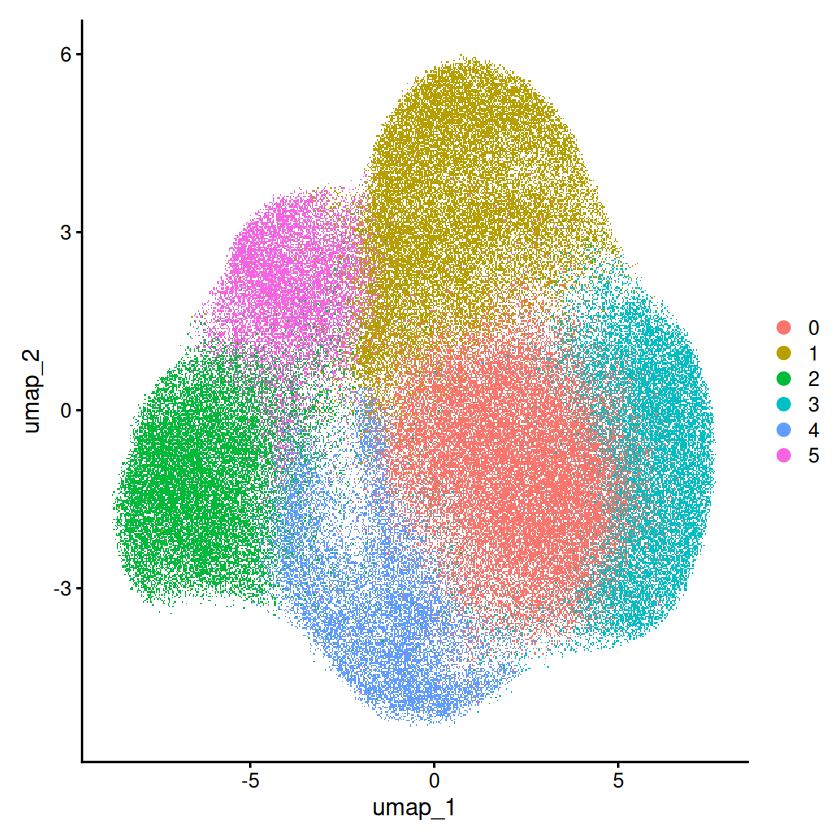

In [8]:
DimPlot(seu_cd4)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



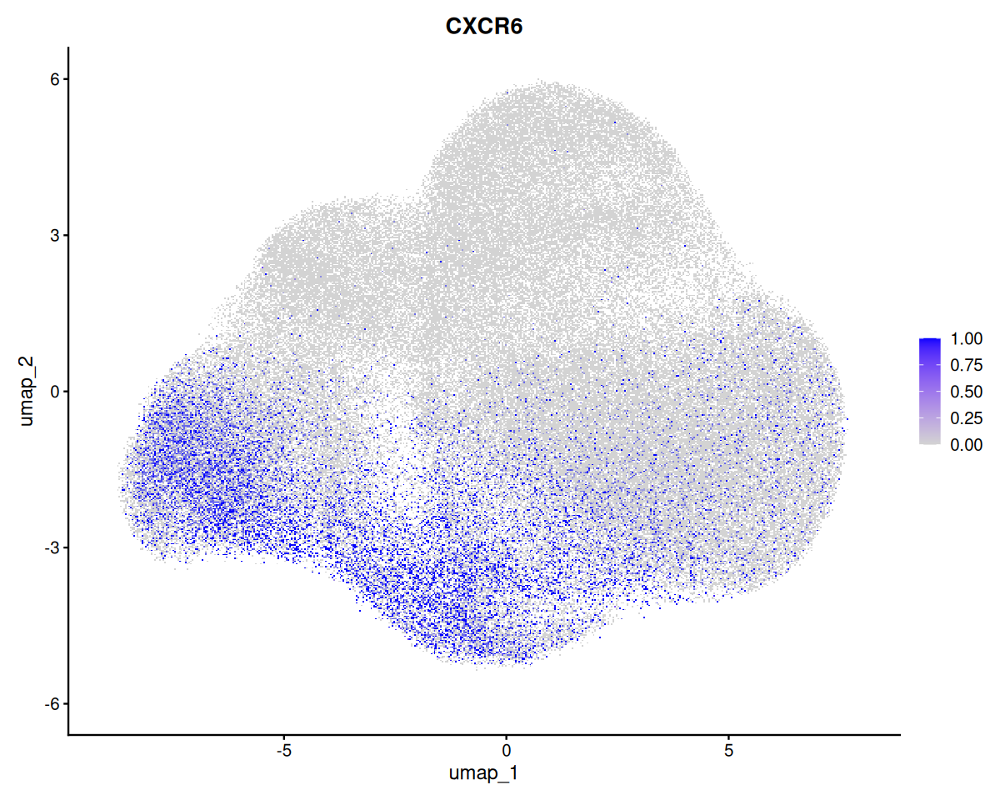

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



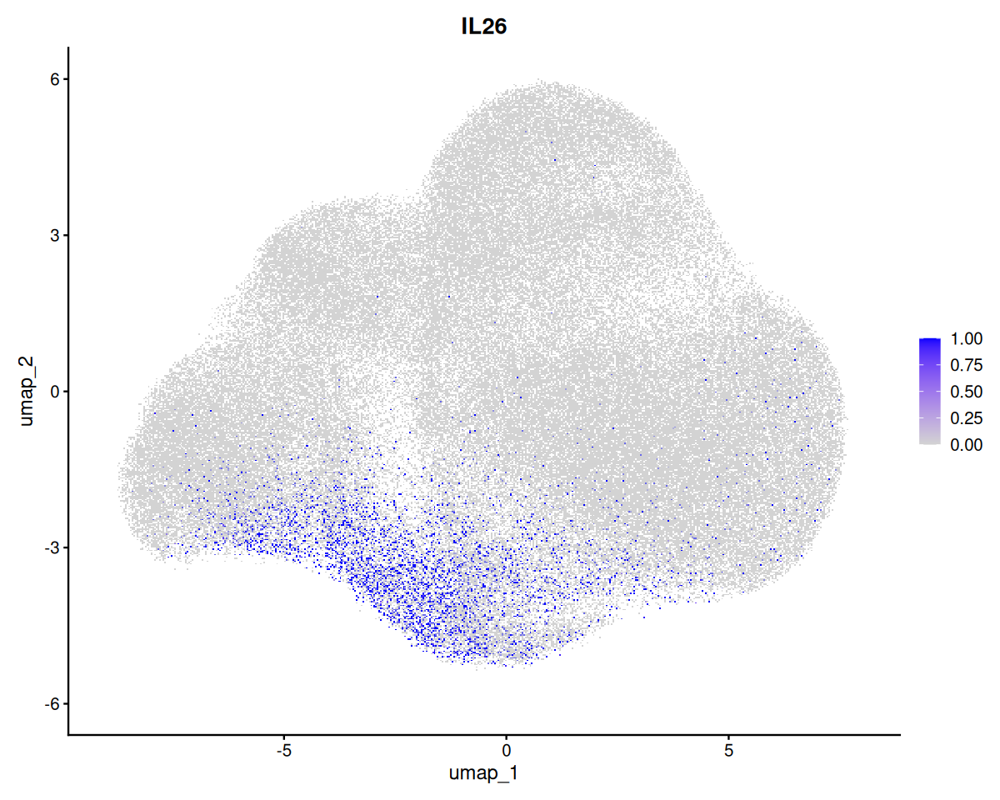

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



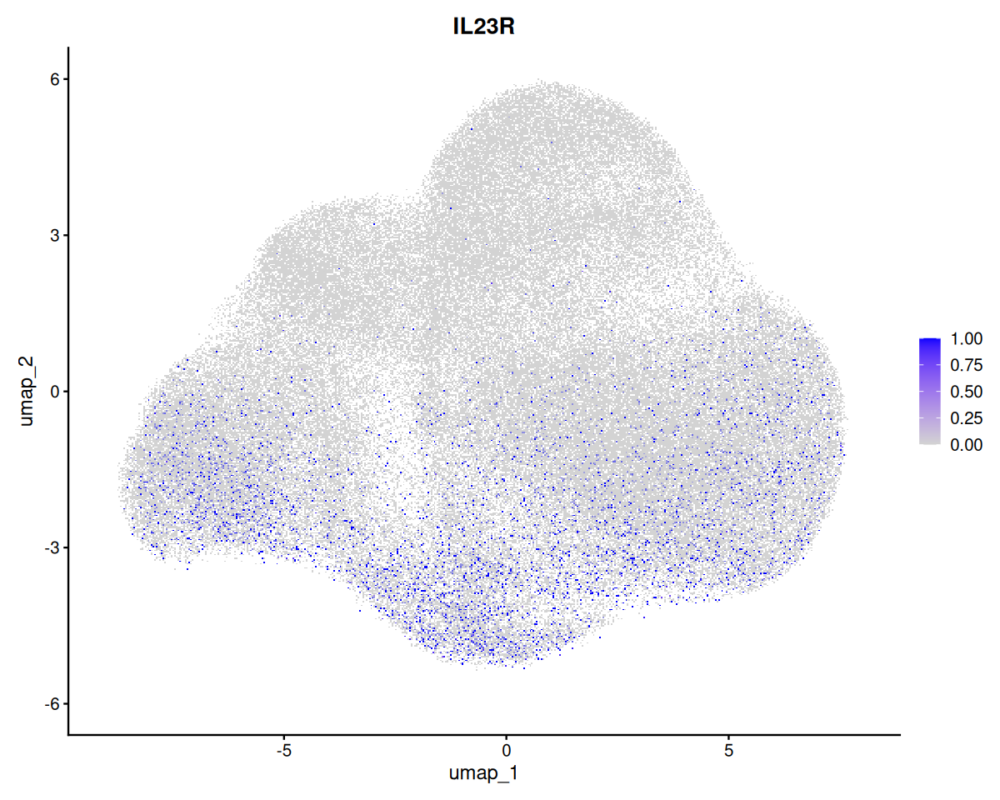

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



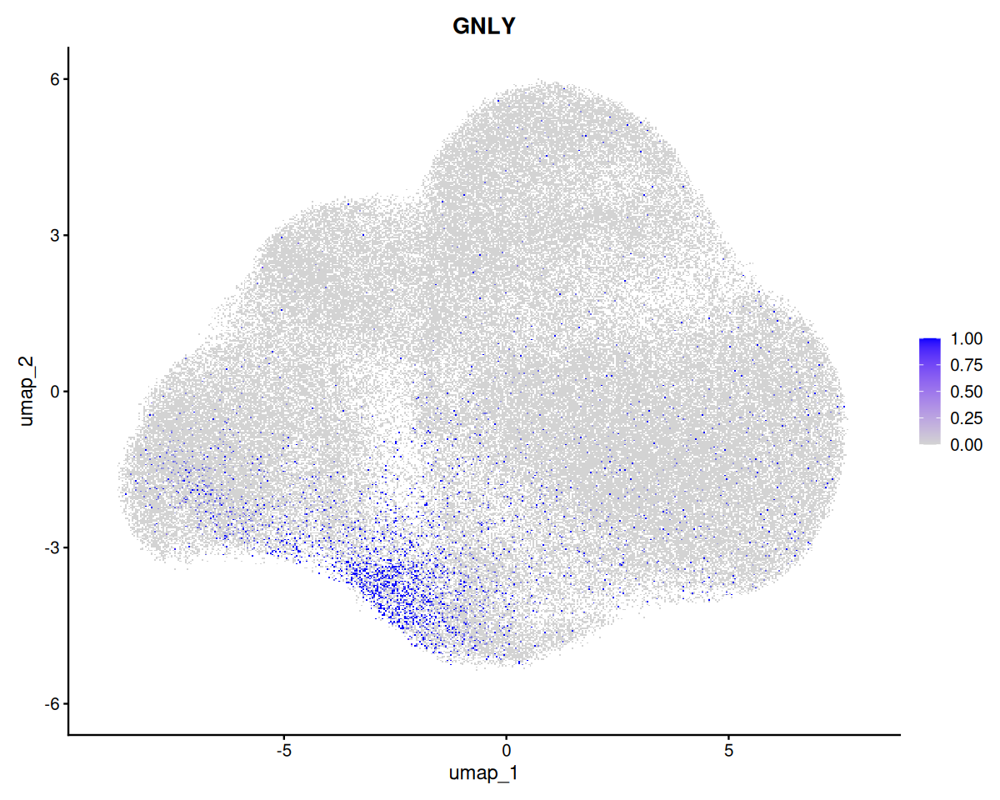

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



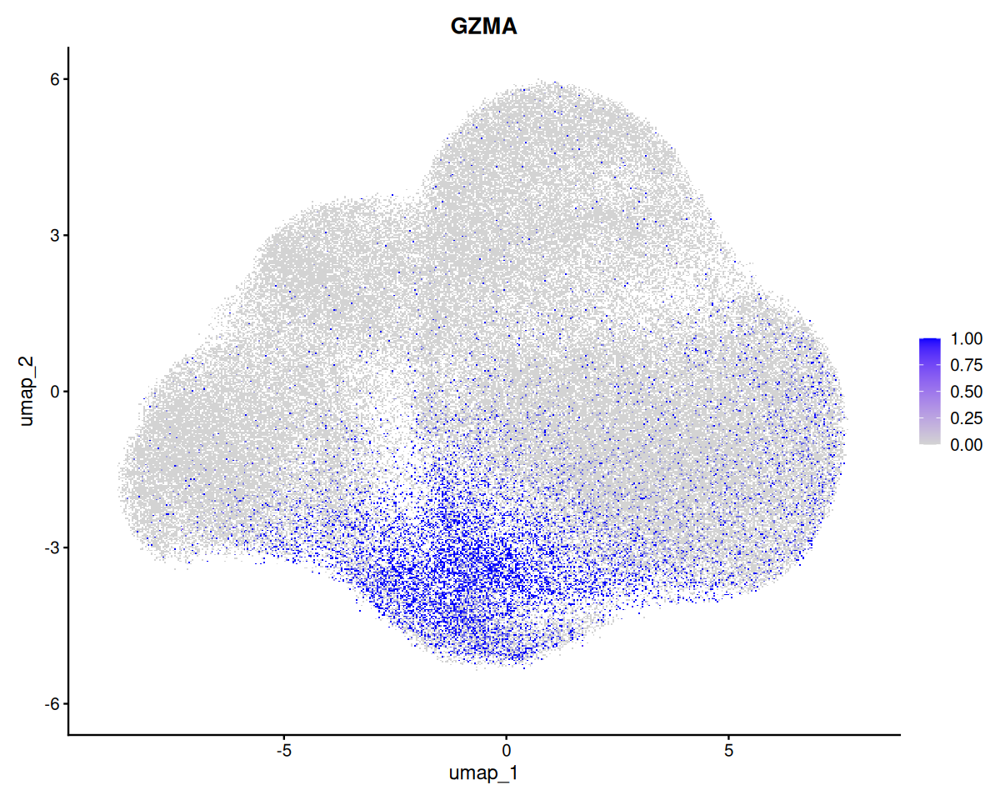

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



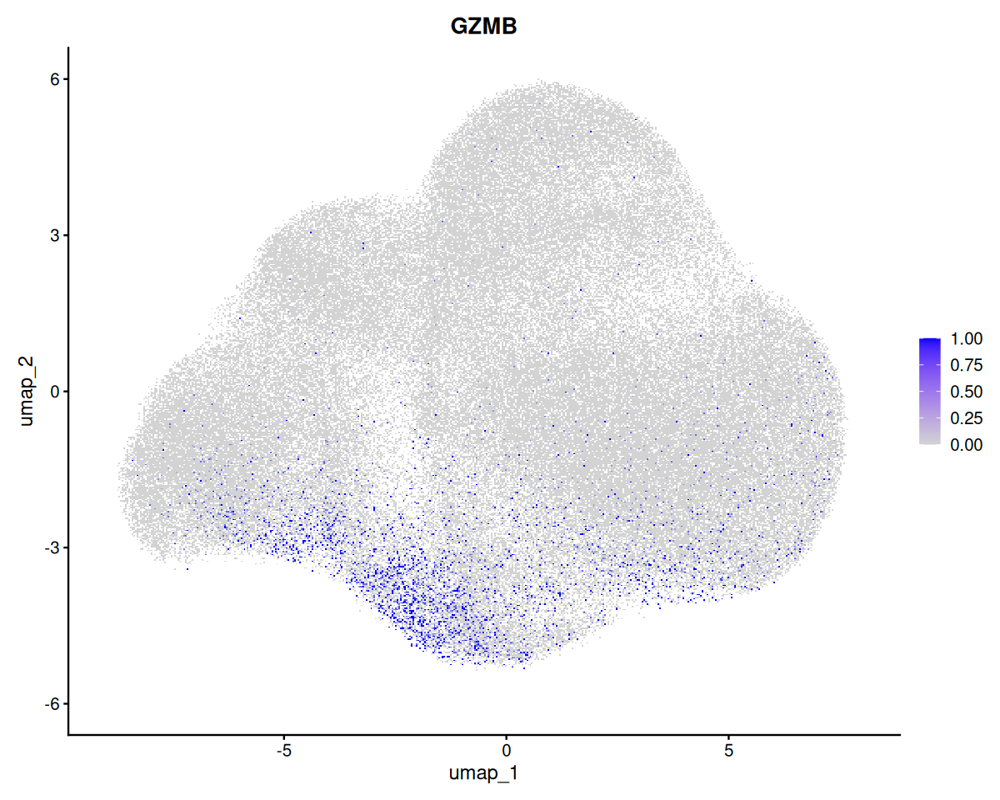

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



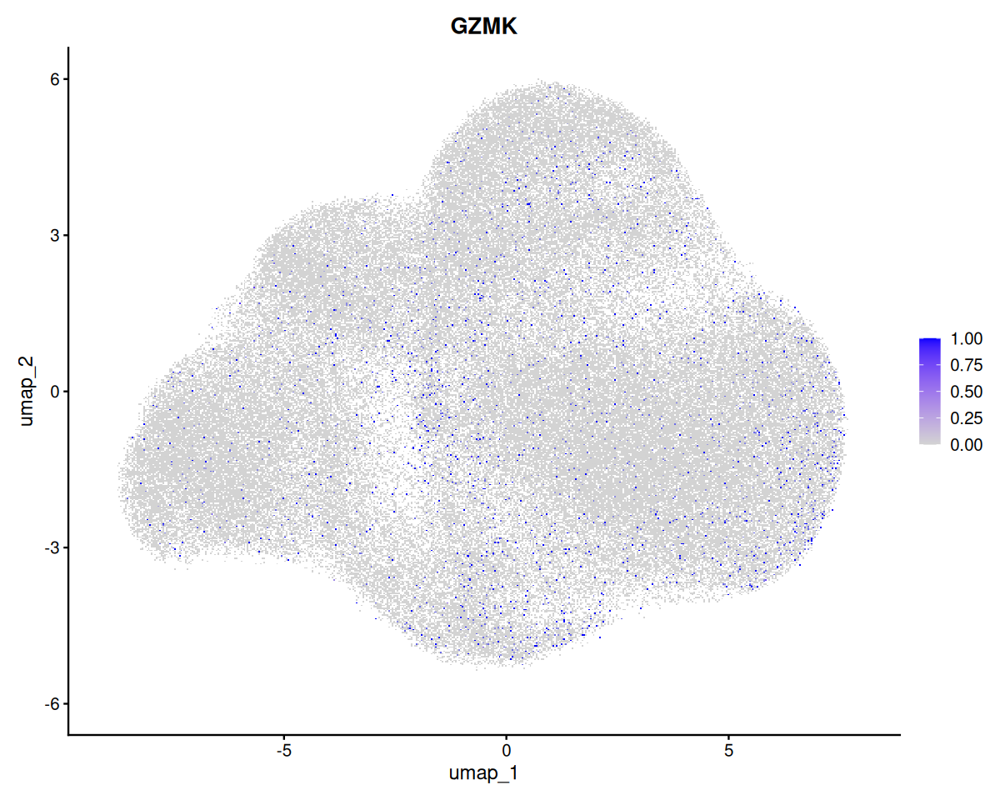

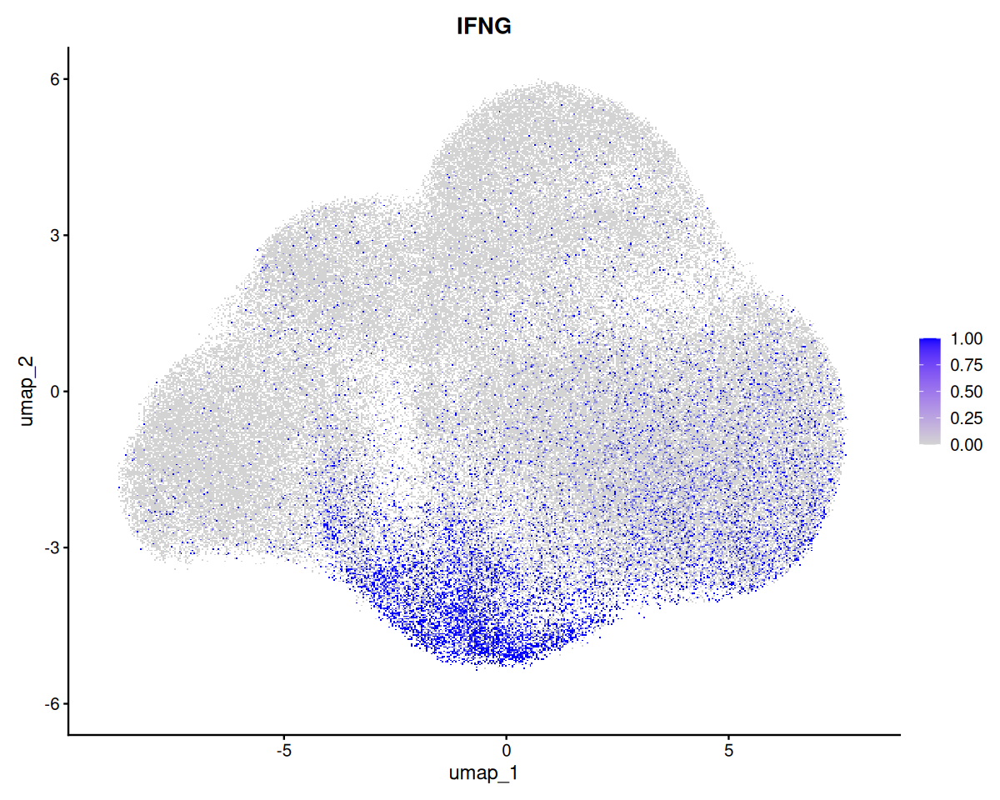

In [9]:
options(repr.plot.width = 10, repr.plot.height = 8)
FeaturePlot(seu_cd4, features= c("CXCR6"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(seu_cd4, features= c("IL26"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(seu_cd4, features= c("IL23R"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(seu_cd4, features= c("GNLY"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(seu_cd4, features= c("GZMA"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(seu_cd4, features= c("GZMB"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(seu_cd4, features= c("GZMK"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(seu_cd4, features= c("IFNG"), min.cutoff = 0, max.cutoff = 1)


In [10]:
seu_cd4@meta.data  %>% colnames

[1] "orig.ident"         "nCount_RNA"         "nFeature_RNA"      
 [4] "sample_id"          "Patient"            "Disease"           
 [7] "Site"               "Treatment"          "Disease_duration"  
[10] "Inflammation"       "Age"                "Gender"            
[13] "Ethnicity"          "Inflammation_score" "Ileum_vs_Colon"    
[16] "LibraryType"        "CellsLoaded"        "Match"             
[19] "Batch"              "doublet_scores"     "predicted_doublets"
[22] "n_genes_by_counts"  "total_counts"       "total_counts_mt"   
[25] "pct_counts_mt"      "total_counts_rp"    "pct_counts_rp"     
[28] "total_counts_hb"    "pct_counts_hb"      "total_counts_ig"   
[31] "pct_counts_ig"      "S_score"            "G2M_score"         
[34] "phase"              "cellbarcode"        "diff"              
[37] "final_analysis"     "minor"              "major"             
[40] "sub_bucket"         "bucket"             "Remission_status"  
[43] "bc"                 "RNA_snn_res.0.3"    "seurat_clusters"

In [11]:
merged_ds <- SplitObject(seu_cd4, split.by = "Patient")
merged.list <- lapply(X = merged_ds, FUN = function(x) {
DefaultAssay(x)  <- "RNA"
x$barcode  <- colnames(x)
x <- NormalizeData(x)
x <- FindVariableFeatures(x, selection.method = "vst", nfeatures = 800)
})

gut_5p_integrated <- Run.STACAS(merged.list, dims = 1:12, k.weight = 70)
gut_5p_integrated <- RunUMAP(gut_5p_integrated, dims = 1:12) 
gut_5p_integrated <- FindNeighbors(gut_5p_integrated)
gut_5p_integrated <- FindClusters(gut_5p_integrated, res = c(0.5))

saveRDS(gut_5p_integrated, "data/published_data/thomas_integrated_cd4.rds")

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normalizing layer: counts

Finding variable features for layer counts

Normal

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Merging dataset 26 into 29 11 5 17 9 3 10 1 36

Extracting anchors for merged samples

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”

Integrating dataset 2 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 4 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 6 with reference dataset

Finding integration vectors

Finding integration vector weights

Integrating data


Integrating dataset 7 with reference dataset

Finding integration vectors

Finding integration vector weights



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 145704
Number of edges: 3694006

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8724
Number of communities: 10
Elapsed time: 93 seconds


In [35]:
gut_5p_integrated <- readRDS("data/published_data/thomas_integrated_cd4.rds")

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



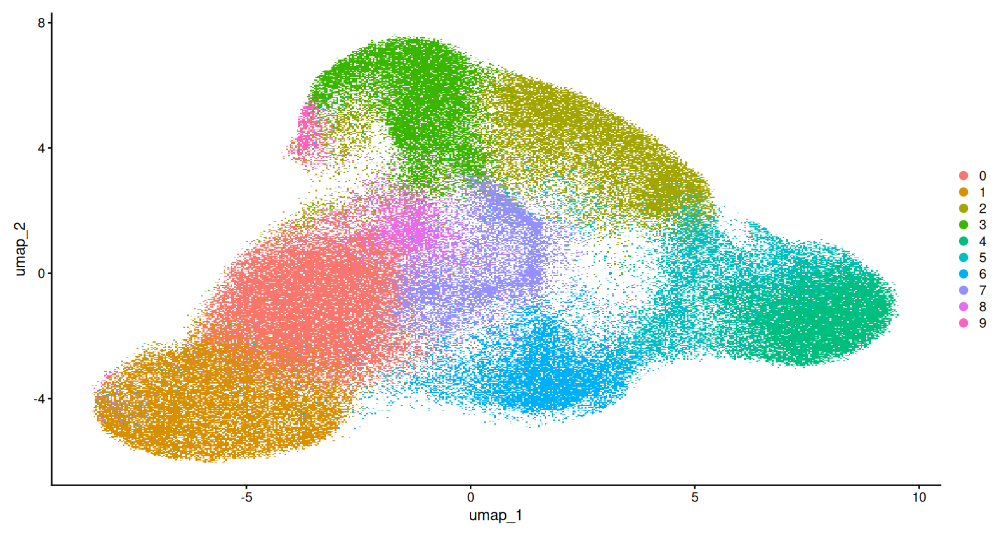

In [38]:
DimPlot(gut_5p_integrated)

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



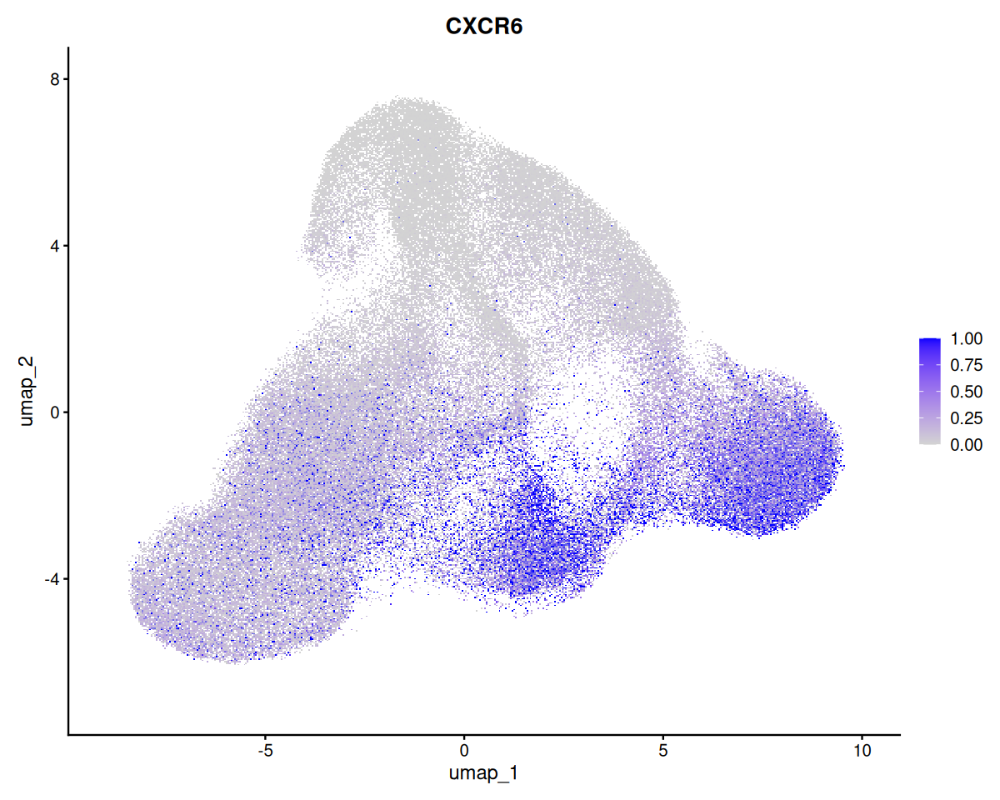

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



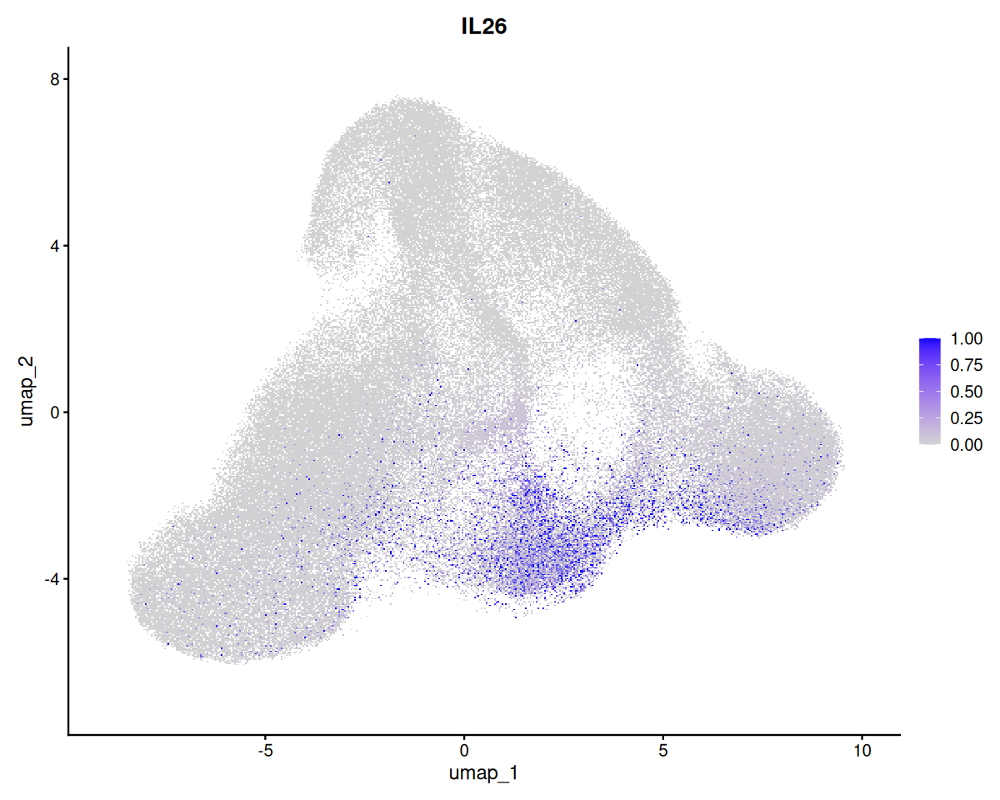

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



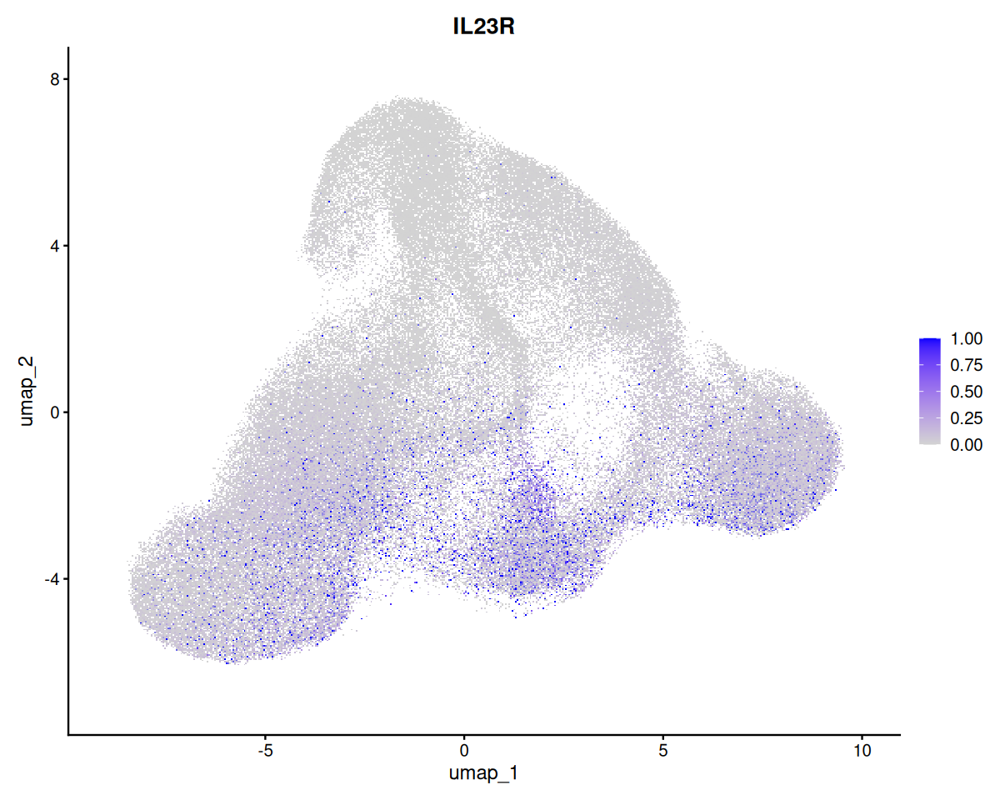

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



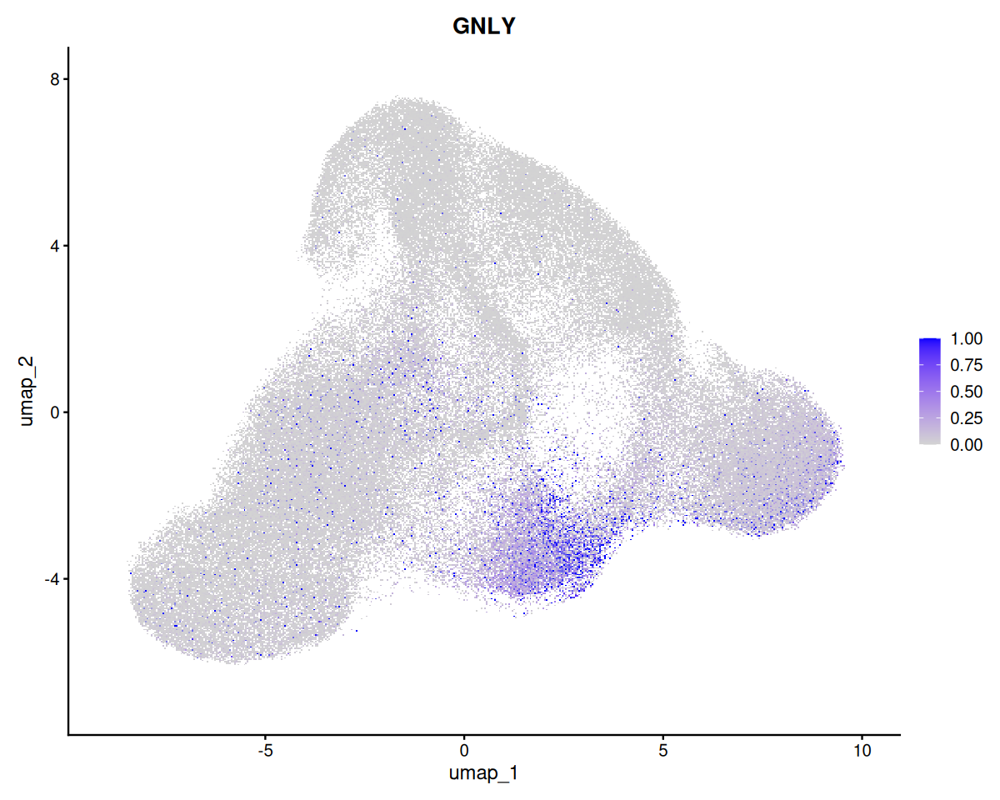

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



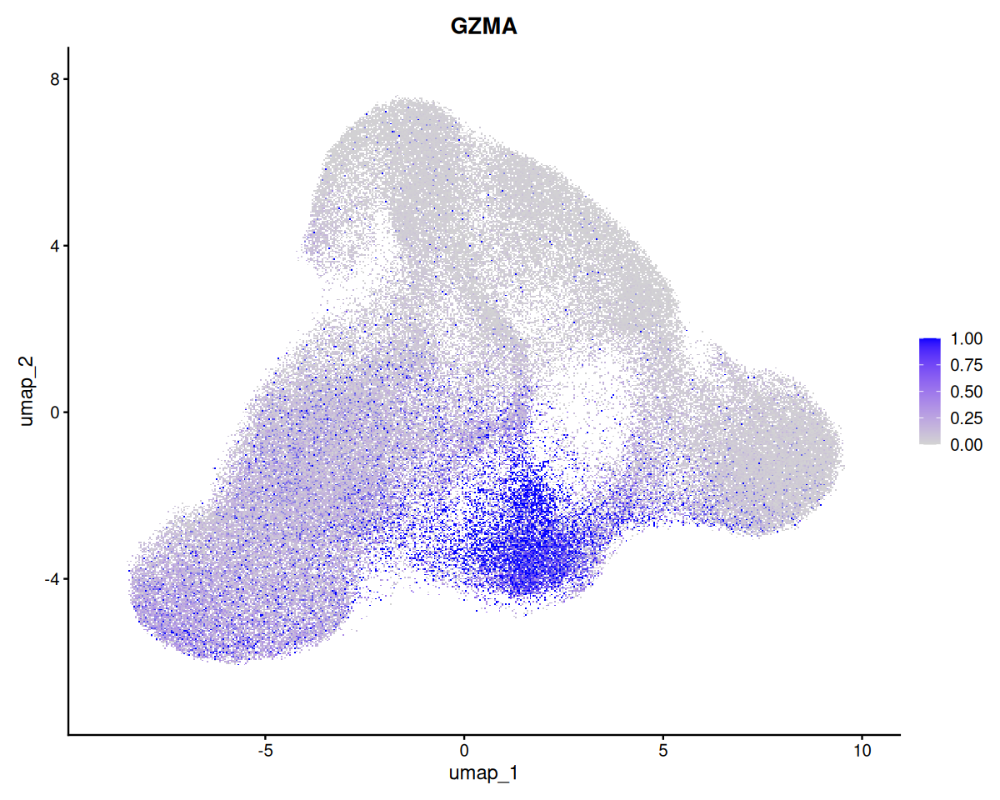

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



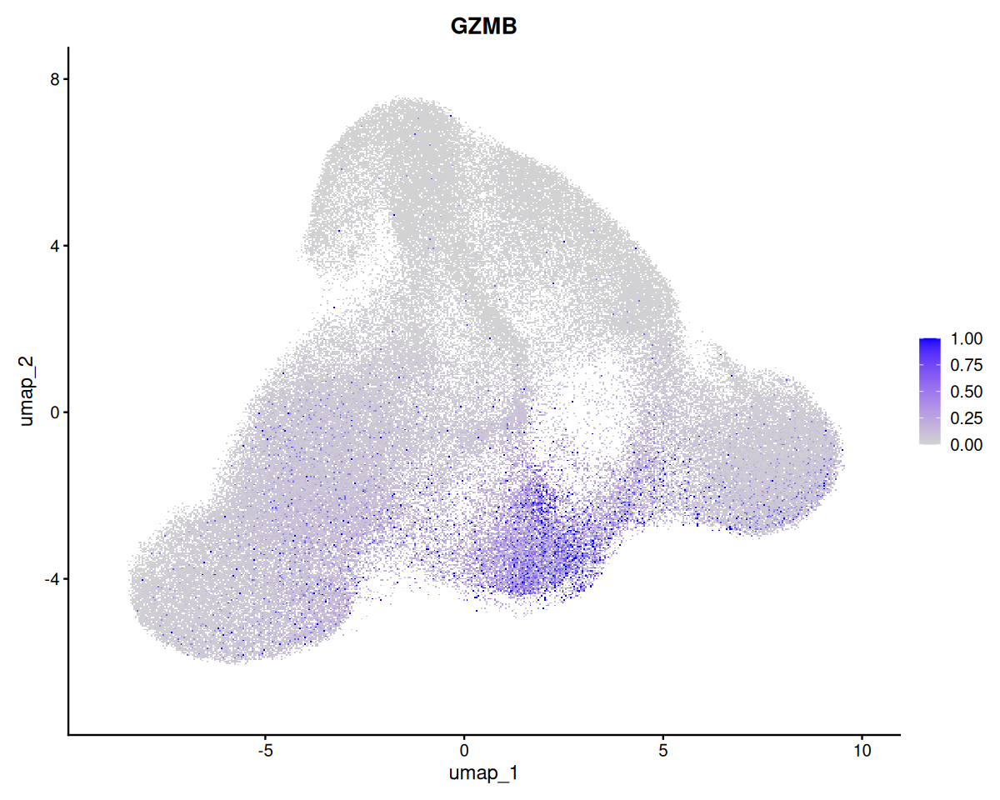

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



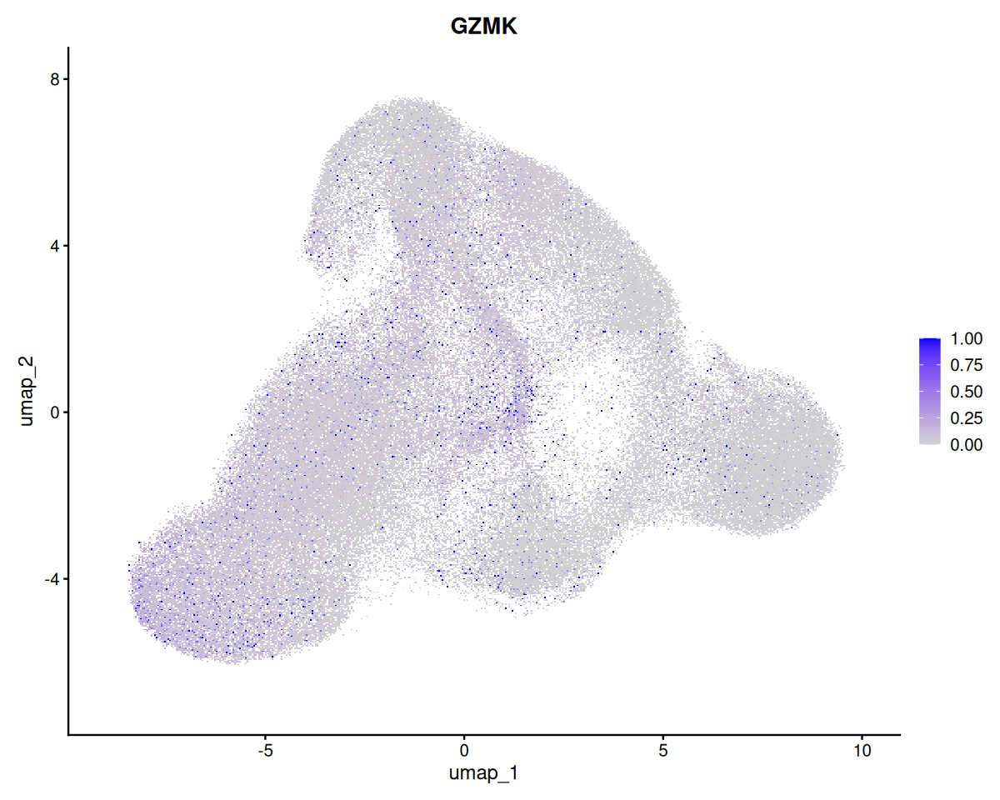

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



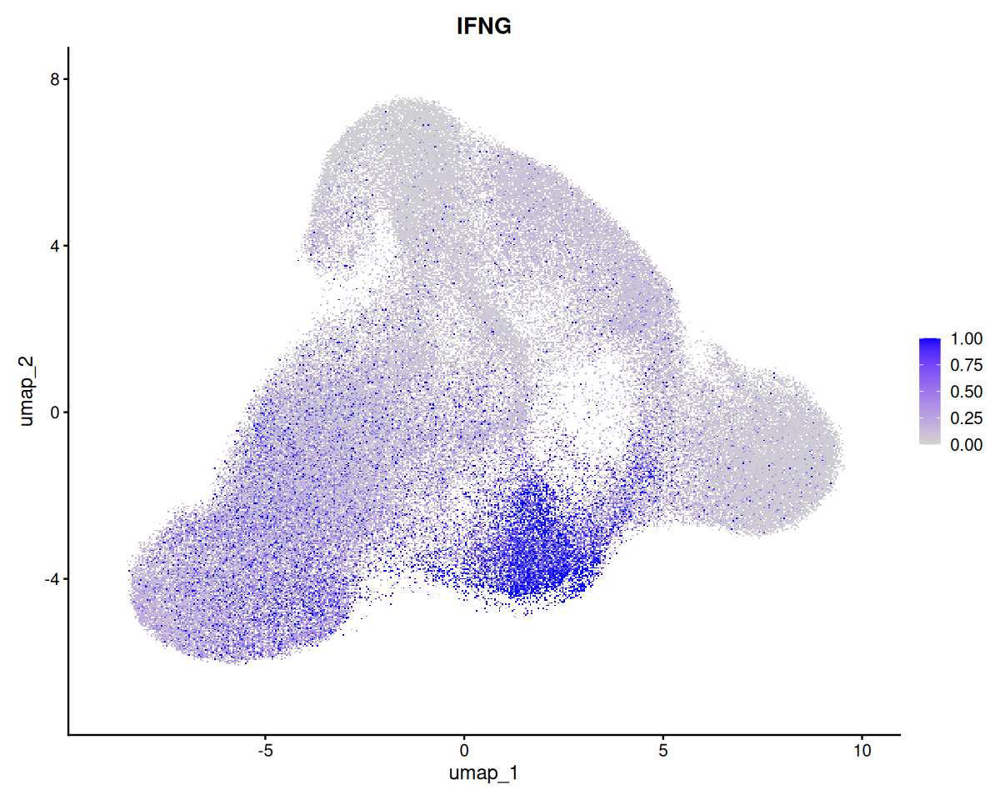

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



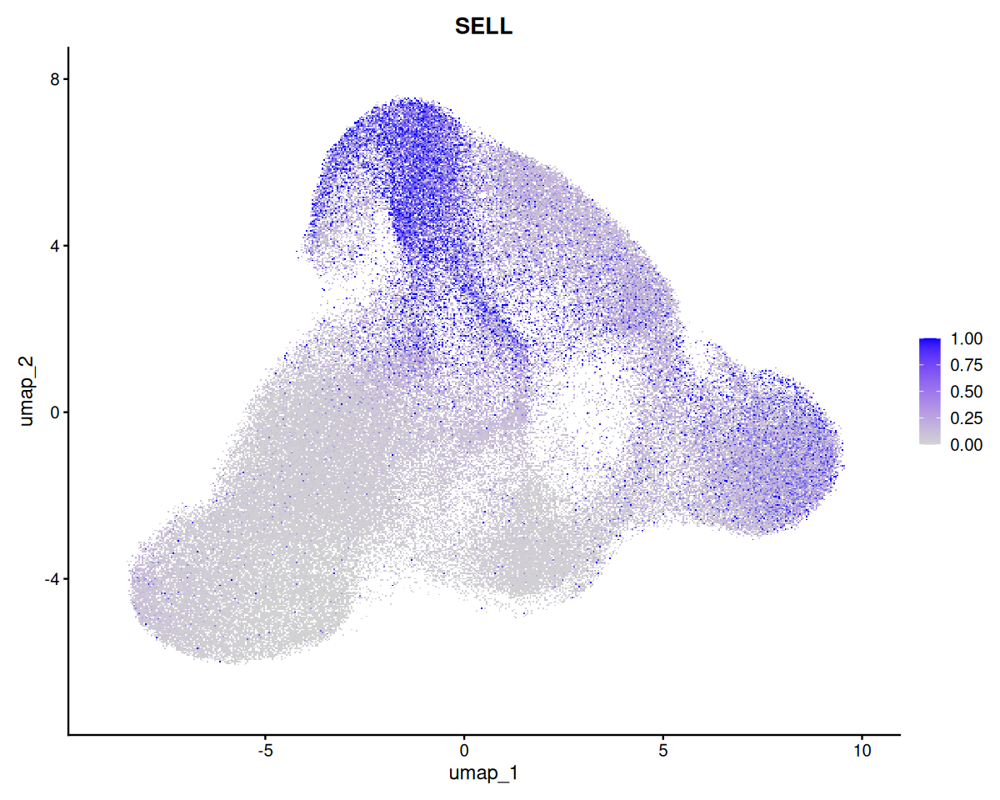

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



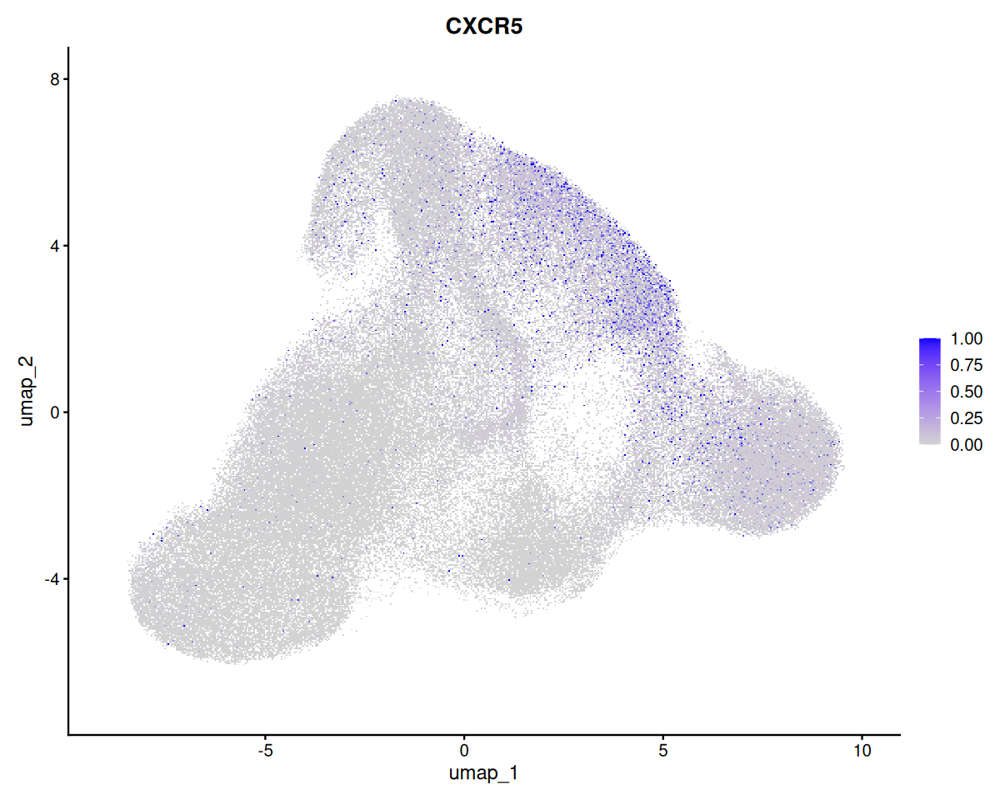

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



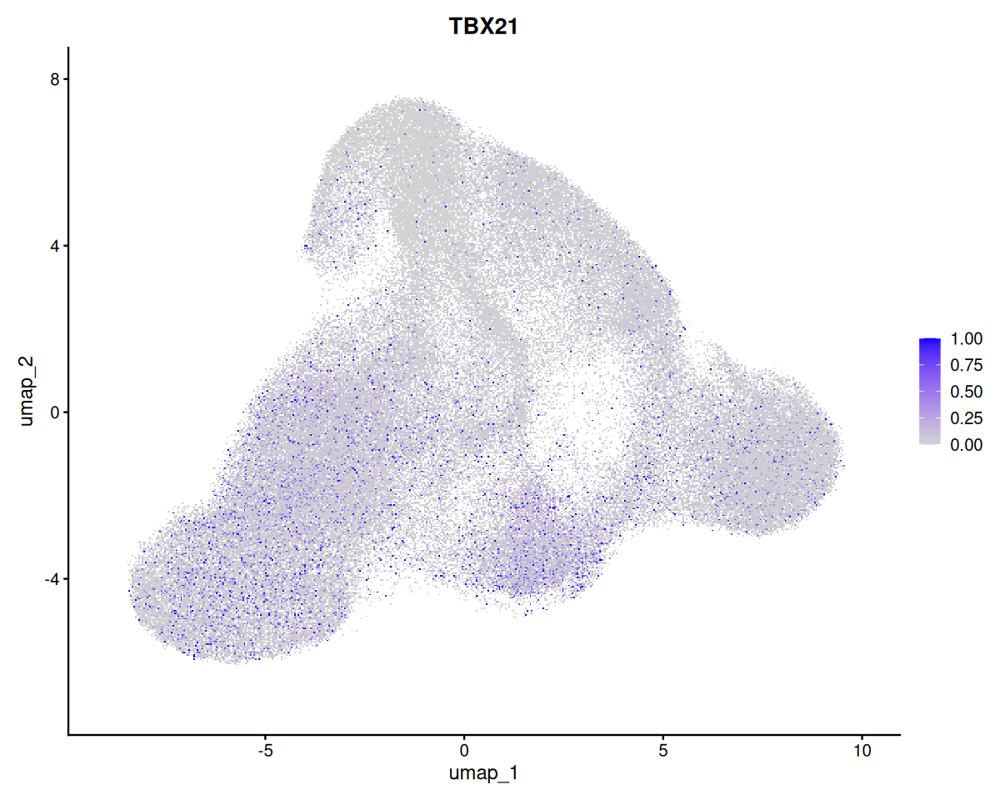

Warning message:
“Could not find MKI67 in the default search locations, found in ‘RNA’ assay instead”
Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



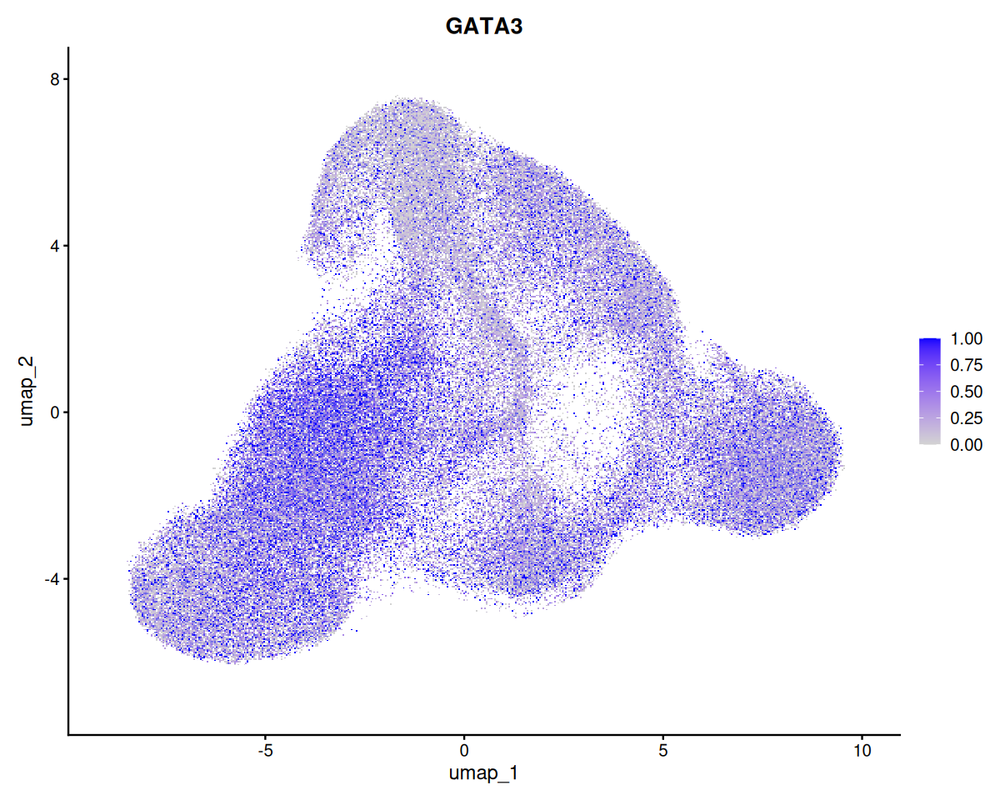

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



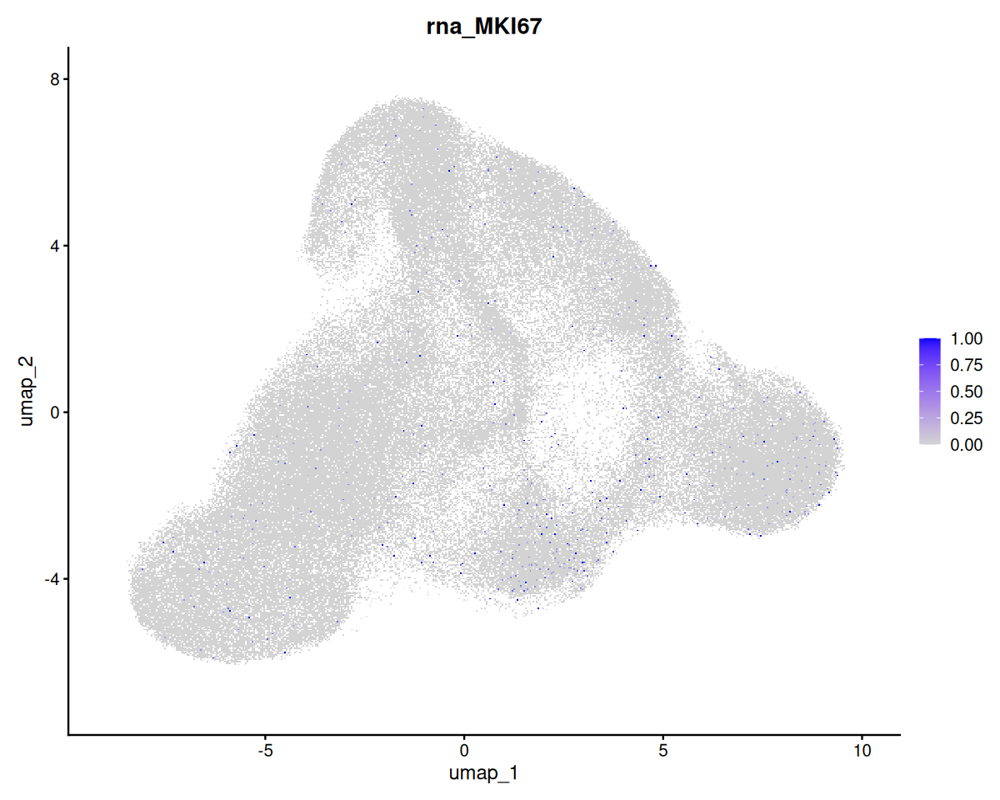

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



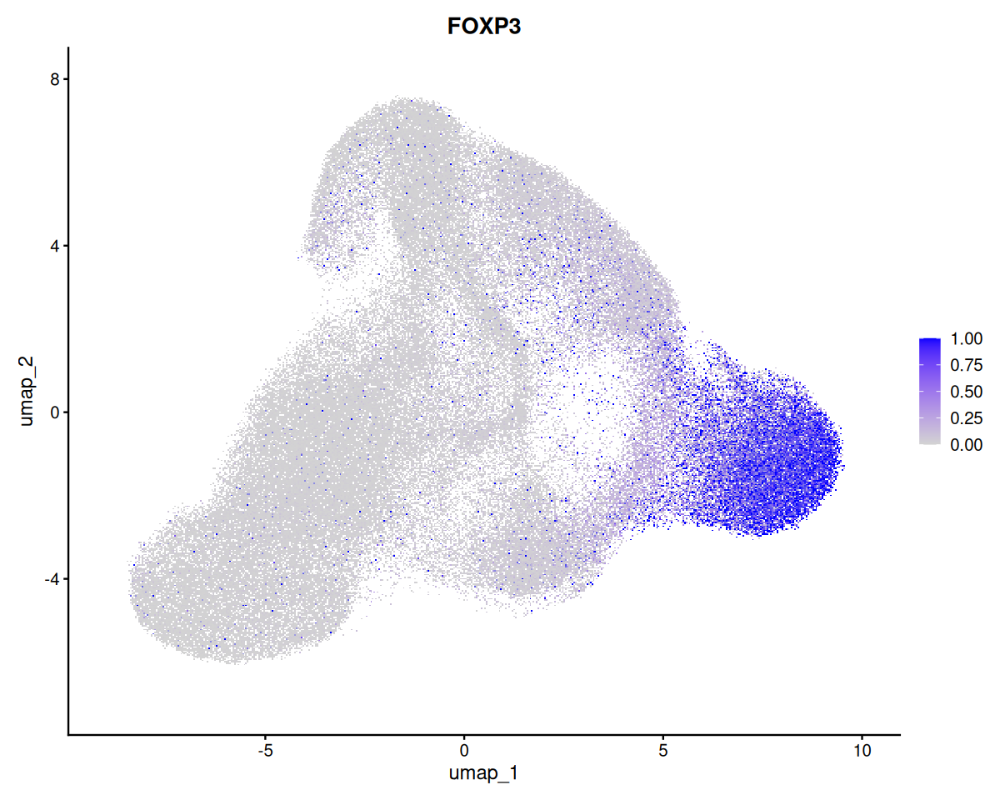

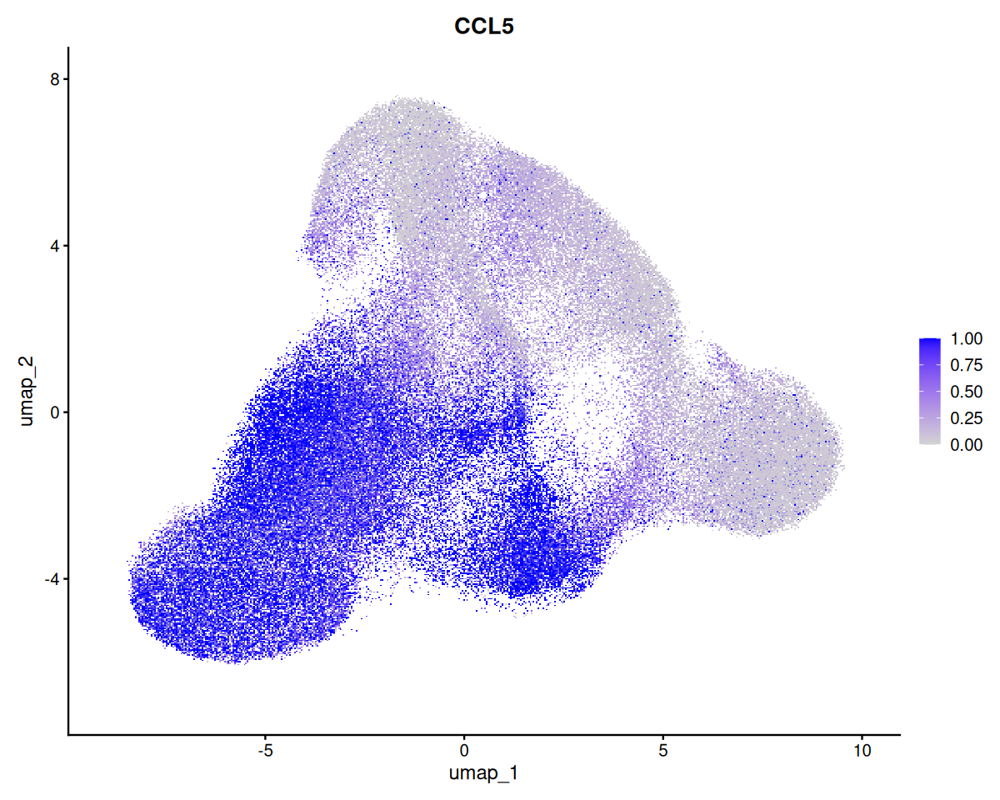

In [14]:
options(repr.plot.width = 10, repr.plot.height = 8)
FeaturePlot(gut_5p_integrated, features= c("CXCR6"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(gut_5p_integrated, features= c("IL26"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(gut_5p_integrated, features= c("IL23R"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(gut_5p_integrated, features= c("GNLY"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(gut_5p_integrated, features= c("GZMA"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(gut_5p_integrated, features= c("GZMB"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(gut_5p_integrated, features= c("GZMK"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(gut_5p_integrated, features= c("IFNG"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(gut_5p_integrated, features= c("SELL"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(gut_5p_integrated, features= c("CXCR5"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(gut_5p_integrated, features= c("TBX21"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(gut_5p_integrated, features= c("GATA3"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(gut_5p_integrated, features= c("MKI67"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(gut_5p_integrated, features= c("FOXP3"), min.cutoff = 0, max.cutoff = 1)
FeaturePlot(gut_5p_integrated, features= c("CCL5"), min.cutoff = 0, max.cutoff = 1)


In [15]:
gut_5p_integrated@meta.data  %>% colnames

[1] "orig.ident"             "nCount_RNA"             "nFeature_RNA"          
 [4] "sample_id"              "Patient"                "Disease"               
 [7] "Site"                   "Treatment"              "Disease_duration"      
[10] "Inflammation"           "Age"                    "Gender"                
[13] "Ethnicity"              "Inflammation_score"     "Ileum_vs_Colon"        
[16] "LibraryType"            "CellsLoaded"            "Match"                 
[19] "Batch"                  "doublet_scores"         "predicted_doublets"    
[22] "n_genes_by_counts"      "total_counts"           "total_counts_mt"       
[25] "pct_counts_mt"          "total_counts_rp"        "pct_counts_rp"         
[28] "total_counts_hb"        "pct_counts_hb"          "total_counts_ig"       
[31] "pct_counts_ig"          "S_score"                "G2M_score"             
[34] "phase"                  "cellbarcode"            "diff"                  
[37] "final_analysis"         "minor"                  "major"                 
[40] "sub_bucket"             "bucket"                 "Remission_status"      
[43] "bc"                     "RNA_snn_res.0.3"        "seurat_clusters"       
[46] "barcode"                "integrated_snn_res.0.5"

In [19]:
gut_5p_integrated@meta.data  %>% group_by(Disease, Site, Treatment, Inflammation, Remission_status)  %>% tally

Disease,Site,Treatment,Inflammation,Remission_status,n
<chr>,<chr>,<chr>,<chr>,<chr>,<int>
CD,Ascending_Colon,Post,Inflamed,Remission,1812
CD,Ascending_Colon,Post,Non_Inflamed,Non_Remission,954
CD,Ascending_Colon,Post,Non_Inflamed,Remission,2581
CD,Ascending_Colon,Pre,Inflamed,Remission,5386
CD,Ascending_Colon,Pre,Non_Inflamed,Non_Remission,1908
CD,Ascending_Colon,Pre,Non_Inflamed,Remission,203
CD,Descending_Colon,Post,Non_Inflamed,Non_Remission,495
CD,Descending_Colon,Post,Non_Inflamed,Remission,3600
CD,Descending_Colon,Pre,Inflamed,Non_Remission,634


In [7]:
gut_5p_integrated$Disease  %>% table

.
     CD Healthy      UC 
  66534    4713   74457 

In [21]:
gut_5p_integrated$Site  %>% table

.
 Ascending_Colon Descending_Colon           Rectum          Sigmoid 
           21779            32159            38396            13656 
  Terminal_Ileum 
           39714 

In [22]:
gut_5p_integrated$Treatment  %>% table

.
 Post   Pre 
63178 77813 

In [23]:
gut_5p_integrated$Inflammation  %>% table

.
     Healthy     Inflamed Non_Inflamed 
        4713        90762        50229 

In [24]:
gut_5p_integrated$Remission_status  %>% table

.
Non_Remission          None     Not_avail     Remission 
        70580          4713          2538         67873 

In [53]:
md <- gut_5p_integrated@meta.data
df4 <- md %>% group_by(sample_id, seurat_clusters) %>% 
  summarise(n = n()) %>% 
  unique() %>% 
  mutate(freq = n / sum(n))  %>%
dplyr::select(-n)  %>% 
pivot_wider(names_from = seurat_clusters, values_from = freq, values_fill = 0)  %>% 
pivot_longer(!sample_id, names_to = "seurat_clusters", values_to = "freq")

# As we've lost non-grouping variables, let's join them back
md_to_join <- md %>% dplyr::select(Remission_status, Inflammation, 
                                   Treatment, Site, Disease, sample_id, Patient) %>% unique()
df4  <- left_join(df4, md_to_join, by = "sample_id")


`summarise()` has grouped output by 'sample_id'. You can override using the
`.groups` argument.


In [54]:
df4

sample_id,seurat_clusters,freq,Remission_status,Inflammation,Treatment,Site,Disease,Patient
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
CID003352-2,0,0.210810811,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,1,0.059459459,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,2,0.091891892,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,3,0.023783784,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,4,0.212972973,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,5,0.190270270,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,6,0.105945946,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,7,0.022702703,Non_Remission,Inflamed,Post,Rectum,UC,UC1
CID003352-2,8,0.081081081,Non_Remission,Inflamed,Post,Rectum,UC,UC1


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


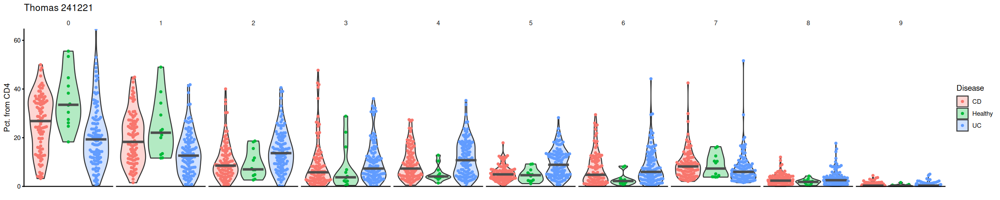

In [40]:
options(repr.plot.width = 20, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("UC","CD","Healthy") )

df_filt  %>% 
ggplot(aes(x = Disease, y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Disease), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = Disease), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Thomas 241221")


#ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(1,4)), label = "p.signif") +
#stat_pvalue_manual(
#    stat_test, label = "p.label", 
    #y.position = 60,
#    remove.bracket = TRUE
 #   ) + 
#ggtheme()

In [15]:
gut_5p_integrated@meta.data  %>% colnames

[1] "orig.ident"             "nCount_RNA"             "nFeature_RNA"          
 [4] "sample_id"              "Patient"                "Disease"               
 [7] "Site"                   "Treatment"              "Disease_duration"      
[10] "Inflammation"           "Age"                    "Gender"                
[13] "Ethnicity"              "Inflammation_score"     "Ileum_vs_Colon"        
[16] "LibraryType"            "CellsLoaded"            "Match"                 
[19] "Batch"                  "doublet_scores"         "predicted_doublets"    
[22] "n_genes_by_counts"      "total_counts"           "total_counts_mt"       
[25] "pct_counts_mt"          "total_counts_rp"        "pct_counts_rp"         
[28] "total_counts_hb"        "pct_counts_hb"          "total_counts_ig"       
[31] "pct_counts_ig"          "S_score"                "G2M_score"             
[34] "phase"                  "cellbarcode"            "diff"                  
[37] "final_analysis"         "minor"                  "major"                 
[40] "sub_bucket"             "bucket"                 "Remission_status"      
[43] "bc"                     "RNA_snn_res.0.3"        "seurat_clusters"       
[46] "barcode"                "integrated_snn_res.0.5"

In [33]:
gut_5p_integrated$Site  %>% table

.
 Ascending_Colon Descending_Colon           Rectum          Sigmoid 
           21779            32159            38396            13656 
  Terminal_Ileum 
           39714 

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


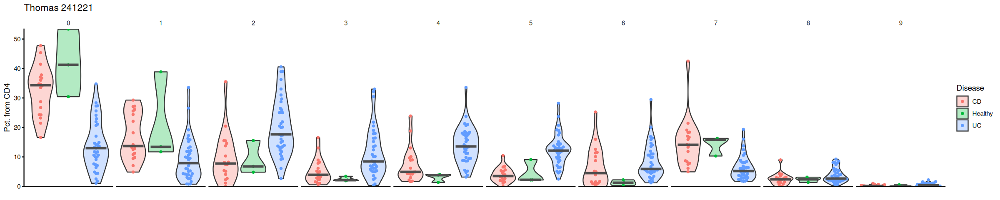

In [41]:
options(repr.plot.width = 20, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("UC","CD","Healthy") & Site == "Rectum" )

df_filt  %>% 
ggplot(aes(x = Disease, y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Disease), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = Disease), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Thomas 241221") 

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


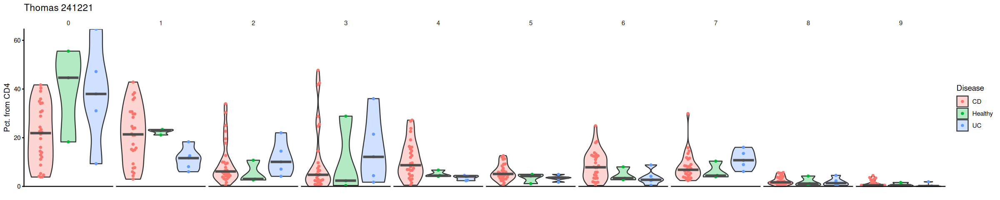

In [42]:
options(repr.plot.width = 20, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("UC","CD","Healthy") & Site == "Terminal_Ileum" )

df_filt  %>% 
ggplot(aes(x = Disease, y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Disease), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = Disease), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Thomas 241221") 
#ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(1,4)), label = "p.signif") +
#stat_pvalue_manual(
#    stat_test, label = "p.label", 
    #y.position = 60,
#    remove.bracket = TRUE
 #   ) + 
#ggtheme()

In [78]:
is.na(df4$Treatment ) %>% table

.
FALSE  TRUE 
 2040   120 

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


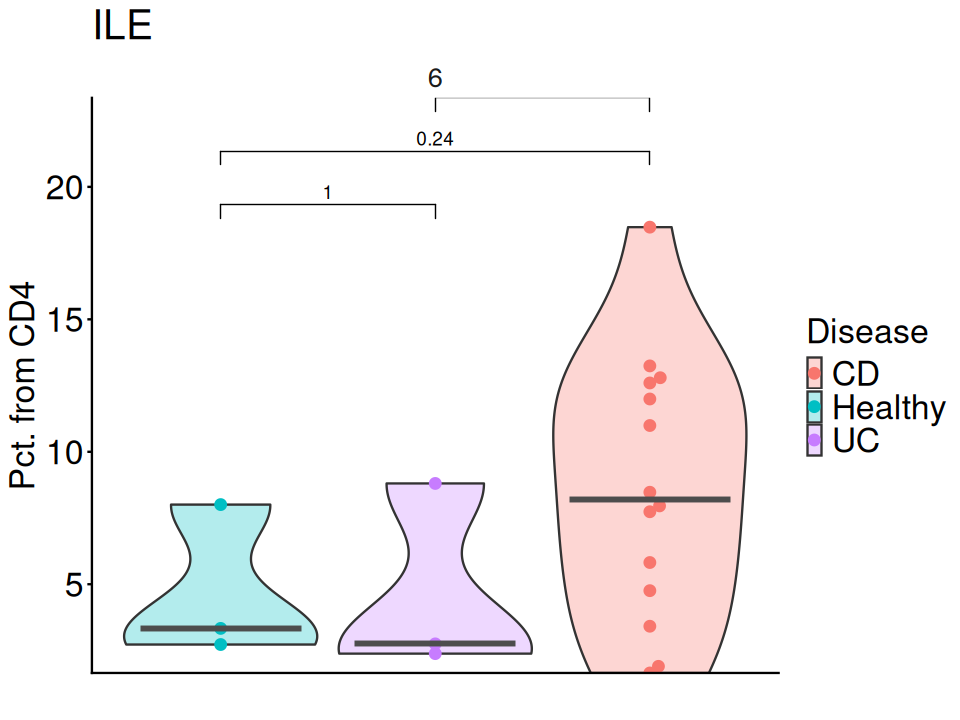

In [124]:
options(repr.plot.width = 8, repr.plot.height = 6)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("UC","CD","Healthy") & 
              Site == "Terminal_Ileum" & seurat_clusters == 6 & (is.na(Treatment)|Treatment == "Pre"))

df_filt  %>% 
ggplot(aes(x = factor(Disease, levels = c("Healthy","UC","CD")),
           y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Disease), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 3, aes(color = Disease), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
scale_color_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
scale_fill_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "ILE") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.format") +
 
ggtheme()

In [125]:
ggsave("figures/thomas/cd4_freq_violin_ile.svg", width = 10, height = 9, units = "cm")

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Warning message in wilcox.test.default(c(1.20481927710843, 1.75438596491228, 8.33333333333333:
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(21.9178082191781, 1.17252931323283, 7.3490813648294, :
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(1.20481927710843, 1.75438596491228, 8.33333333333333:
“cannot compute exact p-value with ties”
Warning message in wilcox.test.default(c(21.9178082191781, 1.17252931323283, 7.3490813648294, :
“cannot compute exact p-value with ties”


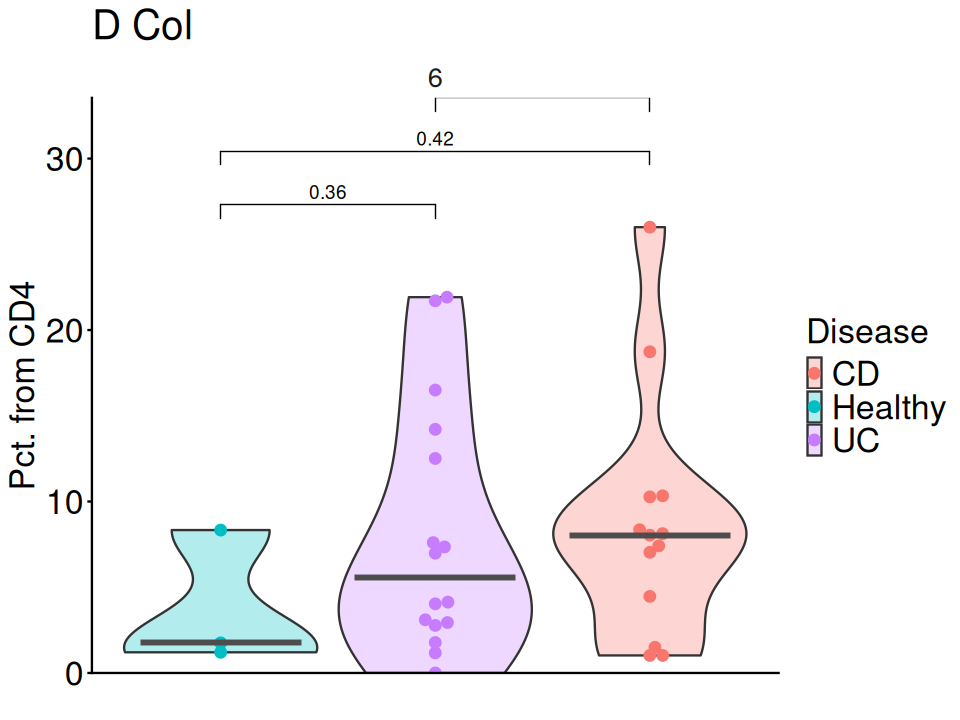

In [126]:
options(repr.plot.width = 8, repr.plot.height = 6)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("UC","CD","Healthy") & 
              Site %in% c("Descending_Colon") & seurat_clusters == 6 & (is.na(Treatment)|Treatment == "Pre"))

df_filt  %>% 
ggplot(aes(x = factor(Disease, levels = c("Healthy","UC","CD")),
           y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Disease), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 3, aes(color = Disease), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
scale_color_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
scale_fill_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "D Col") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.format") +
 
ggtheme()

ggsave("figures/thomas/cd4_freq_violin_desc_colon.svg", width = 10, height = 9, units = "cm")

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


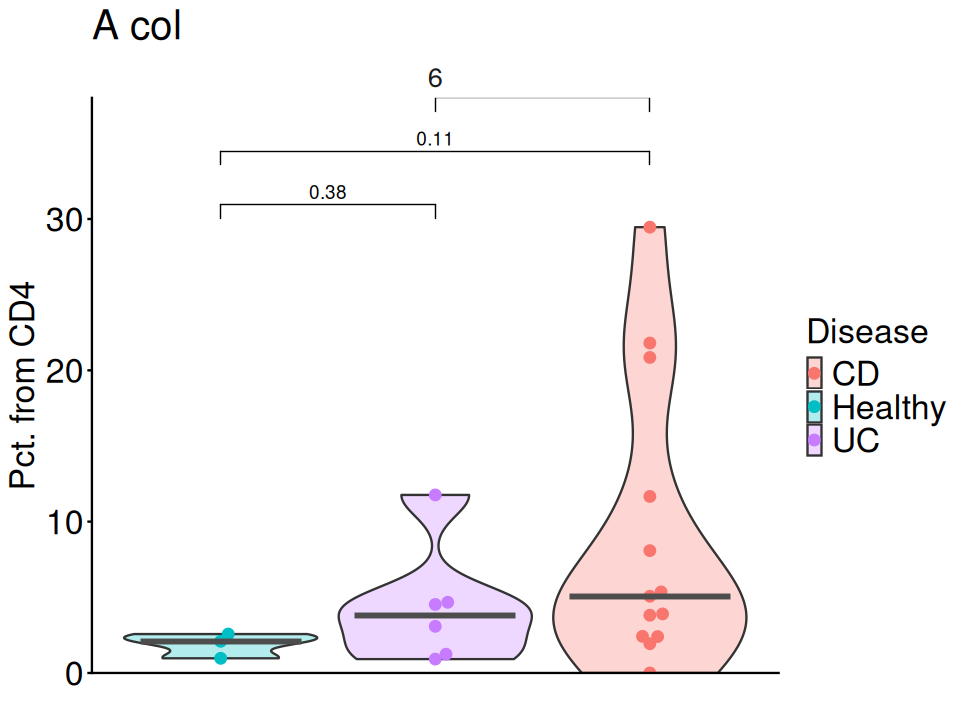

In [127]:
options(repr.plot.width = 8, repr.plot.height = 6)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("UC","CD","Healthy") & 
              Site %in% c("Ascending_Colon") & seurat_clusters == 6 & (is.na(Treatment)|Treatment == "Pre"))

df_filt  %>% 
ggplot(aes(x = factor(Disease, levels = c("Healthy","UC","CD")),
           y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Disease), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 3, aes(color = Disease), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
scale_color_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
scale_fill_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "A col") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.format") +
 
ggtheme()

In [128]:
ggsave("figures/thomas/cd4_freq_violin_asc_colon.svg", width = 10, height = 9, units = "cm")

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


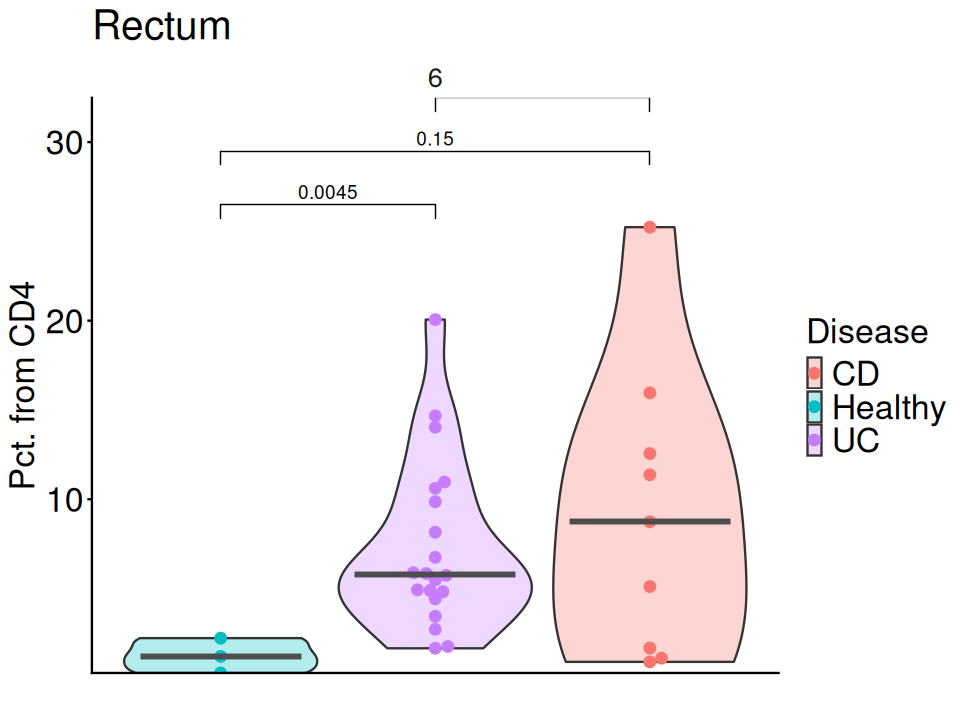

In [117]:
options(repr.plot.width = 8, repr.plot.height = 6)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("UC","CD","Healthy") & 
              Site == "Rectum" & seurat_clusters == 6 & (is.na(Treatment)|Treatment == "Pre"))

df_filt  %>% 
ggplot(aes(x = factor(Disease, levels = c("Healthy","UC","CD")),
           y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Disease), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 3, aes(color = Disease), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
scale_color_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
scale_fill_manual(values = c("Healthy" = "#00bfc4ff","UC" = "#c77cffff","CD" = "#f8766dff")) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Rectum") +
ggpubr::stat_compare_means(comparisons = list(c(1,2),c(1,3),c(2,3)), label = "p.format") +
 
ggtheme()

In [118]:
ggsave("figures/thomas/cd4_freq_violin_rectum.svg", width = 10, height = 9, units = "cm")

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


mapping: label = ~ggplot2::after_stat(p.signif) 
geom_text: na.rm = FALSE
stat_compare_means: label.x.npc = left, label.y.npc = top, label.x = NULL, label.y = NULL, label.sep = , , method = NULL, method.args = list(), paired = FALSE, ref.group = NULL, symnum.args = list(), hide.ns = FALSE, na.rm = FALSE
position_identity 

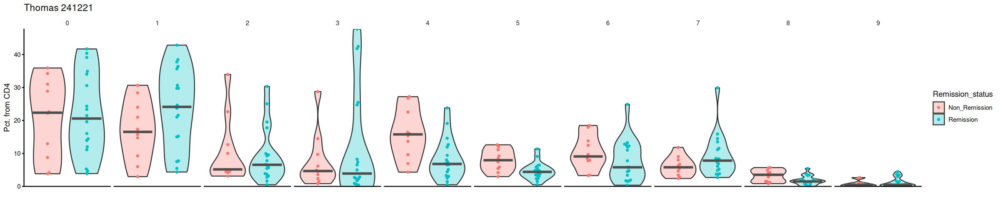

In [43]:
options(repr.plot.width = 20, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("CD") & Site == "Terminal_Ileum")

df_filt  %>% 
ggplot(aes(x = Remission_status, y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Remission_status), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = Remission_status), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Thomas 241221") 
ggpubr::stat_compare_means(label = "p.signif") 
#stat_pvalue_manual(
#    stat_test, label = "p.label", 
    #y.position = 60,
#    remove.bracket = TRUE
 #   ) + 
#ggtheme()

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


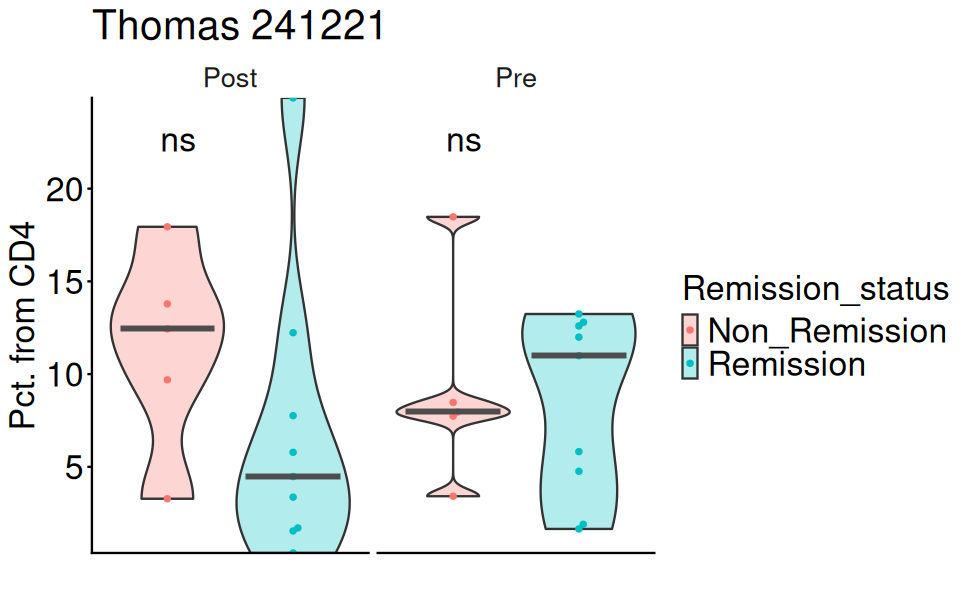

In [50]:
options(repr.plot.width = 8, repr.plot.height = 5)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("CD") & Site == "Terminal_Ileum" & seurat_clusters == 6)

df_filt  %>% 
ggplot(aes(x = Remission_status, y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Remission_status), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = Remission_status), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~Treatment) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Thomas 241221") +
ggtheme() +
ggpubr::stat_compare_means(label = "p.signif", size = 7, label.y = 22) 


Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


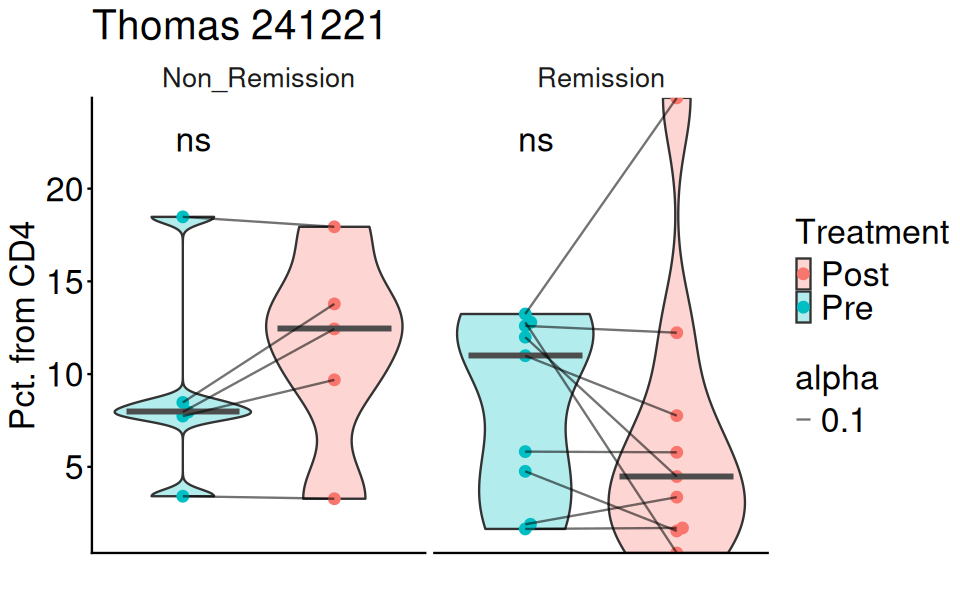

In [137]:
options(repr.plot.width = 8, repr.plot.height = 5)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("CD") & Site == "Terminal_Ileum" & seurat_clusters == 6)

df_filt  %>% 
mutate(Donor_Rem = paste(Patient, Remission_status))  %>% 
ggplot(aes(x = factor(Treatment, levels = c("Pre","Post")), y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Treatment), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 3, aes(color = Treatment), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~Remission_status) +
  ylab("Pct. from CD4") +
  xlab("") +
geom_line(aes(group = Donor_Rem, alpha = 0.1)) +

  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Thomas 241221") +
ggtheme() +
ggpubr::stat_compare_means(label = "p.signif", size = 7, label.y = 22, paired = TRUE) 


In [136]:
ggsave("figures/thomas/cd4_freq_pre_post.svg", width = 12, height = 9, units = "cm")

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.


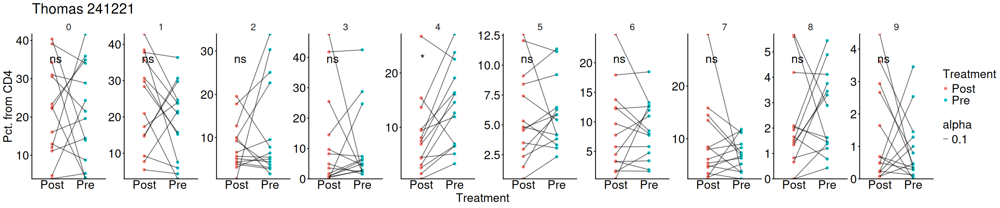

In [65]:
options(repr.plot.width = 24, repr.plot.height = 5)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("CD") & Site == "Terminal_Ileum")

df_filt  %>% 
mutate(Donor_Rem = paste(Patient, Remission_status))  %>% 
ggplot(aes(x = Treatment, y = freq*100)) + # you can change the x to whatever variable you're interested in
  # geom_violin(alpha = 0.3, aes(fill = Remission_status), scale = "width") + 
 geom_point(aes(color = Treatment)) +
geom_line(aes(group = Donor_Rem, alpha = 0.1)) +

  ylab("Pct. from CD4") +
  ylim(c(0,NA)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  scale_y_continuous(expand = c(NA,40))+
  facet_wrap(~seurat_clusters, scales = "free", ncol = 10) +

  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank()) + ggtitle(label = "Thomas 241221") +
ggtheme() +
ggpubr::stat_compare_means(label = "p.signif", size = 7, label.y.npc = 0.8) 


In [25]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


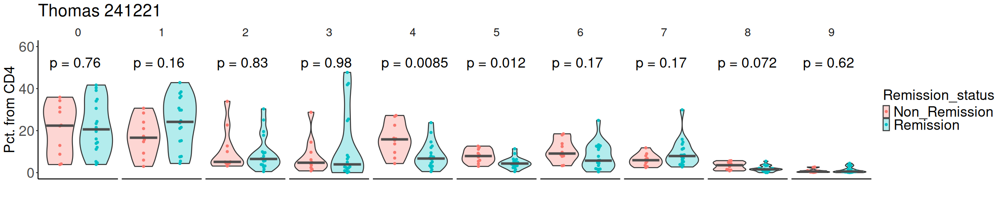

In [26]:
options(repr.plot.width = 20, repr.plot.height = 4)
df_filt <- df4 %>% 
dplyr::filter(Disease %in% c("CD") & Site == "Terminal_Ileum")

df_filt  %>% 
ggplot(aes(x = Remission_status, y = freq*100)) + # you can change the x to whatever variable you're interested in
   geom_violin(alpha = 0.3, aes(fill = Remission_status), scale = "width") + 
 
ggbeeswarm::geom_beeswarm(size = 1.5, aes(color = Remission_status), cex = 2, 
                shape = 16, corral = "random") +
 stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
  facet_wrap(~seurat_clusters, ncol = 11) +
  ylab("Pct. from CD4") +
  xlab("") +
  ylim(c(0,60)) + # This ensures that our x axis starts at zero, but feel free to remove this line
  #scale_y_continuous(expand = c(NA,70))+
  theme_classic() +
  theme(strip.background = element_blank(), 
        panel.grid = element_blank(),
        axis.ticks.x = element_blank(),
        axis.text.x = element_blank()) + ggtitle(label = "Thomas 241221") +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.y = 50) +
ggtheme()

# Other datasets for correlation & nichenet

In [5]:
list.files("data/published_data/")

[1] "cd4tcells_final.h5ad"            "thomas_bcells_ad_genes.csv"     
 [3] "thomas_bcells_ad_meta.csv"       "thomas_bcells_ad.mtx"           
 [5] "thomas_cd4_ad_genes.csv"         "thomas_cd4_ad_meta.csv"         
 [7] "thomas_cd4_ad.mtx"               "thomas_cd8tcells_ad_genes.csv"  
 [9] "thomas_cd8tcells_ad_meta.csv"    "thomas_cd8tcells_ad.mtx"        
[11] "thomas_epicolonic_ad_genes.csv"  "thomas_epicolonic_ad_meta.csv"  
[13] "thomas_epicolonic_ad.mtx"        "thomas_fibperi_ad_genes.csv"    
[15] "thomas_fibperi_ad_meta.csv"      "thomas_fibperi_ad.mtx"          
[17] "thomas_ilc_ad_genes.csv"         "thomas_ilc_ad_meta.csv"         
[19] "thomas_ilc_ad.mtx"               "thomas_ilealepi_ad_genes.csv"   
[21] "thomas_ilealepi_ad_meta.csv"     "thomas_ilealepi_ad.mtx"         
[23] "thomas_integrated_cd4.rds"       "thomas_myeloid_ad_genes.csv"    
[25] "thomas_myeloid_ad_meta.csv"      "thomas_myeloid_ad.mtx"          
[27] "thomas_plasmacells_ad_genes.csv" "thomas_plasmacells_ad_meta.csv" 
[29] "thomas_plasmacells_ad.mtx"       "thomas_vasc_ad_genes.csv"       
[31] "thomas_vasc_ad_meta.csv"         "thomas_vasc_ad.mtx"

In [10]:
list.files("data/published_data/")[grepl(list.files("data/published_data/"), pattern = "mtx") &
                                   grepl(list.files("data/published_data/"), pattern = "thomas_")]

[1] "thomas_bcells_ad.mtx"      "thomas_cd4_ad.mtx"        
 [3] "thomas_cd8tcells_ad.mtx"   "thomas_epicolonic_ad.mtx" 
 [5] "thomas_fibperi_ad.mtx"     "thomas_ilc_ad.mtx"        
 [7] "thomas_ilealepi_ad.mtx"    "thomas_myeloid_ad.mtx"    
 [9] "thomas_plasmacells_ad.mtx" "thomas_vasc_ad.mtx"

In [11]:
matrices  <- list.files("data/published_data/")[grepl(list.files("data/published_data/"), pattern = "mtx") &
                                   grepl(list.files("data/published_data/"), pattern = "thomas_")][c(1,3:10)]

In [12]:
list.files("data/published_data/")[grepl(list.files("data/published_data/"), pattern = "_ad_genes") &
                                   grepl(list.files("data/published_data/"), pattern = "thomas_")]

[1] "thomas_bcells_ad_genes.csv"      "thomas_cd4_ad_genes.csv"        
 [3] "thomas_cd8tcells_ad_genes.csv"   "thomas_epicolonic_ad_genes.csv" 
 [5] "thomas_fibperi_ad_genes.csv"     "thomas_ilc_ad_genes.csv"        
 [7] "thomas_ilealepi_ad_genes.csv"    "thomas_myeloid_ad_genes.csv"    
 [9] "thomas_plasmacells_ad_genes.csv" "thomas_vasc_ad_genes.csv"

In [13]:
gene_files  <- list.files("data/published_data/")[grepl(list.files("data/published_data/"), pattern = "_ad_genes") &
                                   grepl(list.files("data/published_data/"), pattern = "thomas_")][c(1,3:10)]

In [14]:
list.files("data/published_data/")[grepl(list.files("data/published_data/"), pattern = "_ad_meta") &
                                   grepl(list.files("data/published_data/"), pattern = "thomas_")]

[1] "thomas_bcells_ad_meta.csv"      "thomas_cd4_ad_meta.csv"        
 [3] "thomas_cd8tcells_ad_meta.csv"   "thomas_epicolonic_ad_meta.csv" 
 [5] "thomas_fibperi_ad_meta.csv"     "thomas_ilc_ad_meta.csv"        
 [7] "thomas_ilealepi_ad_meta.csv"    "thomas_myeloid_ad_meta.csv"    
 [9] "thomas_plasmacells_ad_meta.csv" "thomas_vasc_ad_meta.csv"

In [15]:
md_files  <- list.files("data/published_data/")[grepl(list.files("data/published_data/"), pattern = "_ad_meta") &
                                   grepl(list.files("data/published_data/"), pattern = "thomas_")][c(1,3:10)]

In [18]:
celltypes  <- gsub(gene_files, pattern = "\\.csv", replacement = "")

In [20]:
dir.create("data/published_data/thomas/")

In [34]:
process_dataset  <- function(i) {
    
dat_ad_mtx <- readMM(paste0("data/published_data/",matrices[i]))

dat_genes <- read_csv(paste0("data/published_data/",gene_files[i]))

dat_metadata <- read_csv(paste0("data/published_data/",md_files[i]))

rownames(dat_ad_mtx) <- dat_metadata$bc
colnames(dat_ad_mtx) <- dat_genes$...1

dat_ad_mtx2 <- t(dat_ad_mtx)

rownames(dat_metadata) <- dat_metadata$bc

seu_dat <- CreateSeuratObject(dat_ad_mtx2, meta.data = dat_metadata)
seu_dat$bc <- colnames(seu_dat)

seu_dat <- NormalizeData(seu_dat, verbose = FALSE)
seu_dat <- FindVariableFeatures(seu_dat, nfeatures = 1000, verbose = FALSE)
seu_dat <- ScaleData(seu_dat, verbose = FALSE)
seu_dat <- RunPCA(seu_dat, npcs = 10, verbose = FALSE)
seu_dat <- RunUMAP(seu_dat, reduction = "pca", dims = 1:10)
seu_dat <- FindNeighbors(seu_dat, dims = 1:10)
seu_dat <- FindClusters(seu_dat, resolution = 0.3)
seu_dat$dataset  <- celltypes[i]
print(DimPlot(seu_dat, group.by = "minor"))
saveRDS(seu_dat, paste0("data/published_data/thomas/",celltypes[i],".rds"))
    
}

In [35]:
length(celltypes)

[1] 9

New names:
• `` -> `...1`
Rows: 33075 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): ...1, feature_types, gene_id, gene_symbol
dbl (4): n_cells_by_counts, mean_counts, pct_dropout_by_counts, total_counts
lgl (4): hb, ig, rp, mt

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 74840 Columns: 39
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (20): sample_id, Patient, Disease, Site, Treatment, Inflammation, Gender...
dbl (18): Disease_duration, Age, Inflammation_score, CellsLoaded, doublet_sc...
lgl  (1): predicted_doublets

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Warning message:
“Unknown or uninitialised column: `bc`.”
Warning message:
“Unknown

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 74840
Number of edges: 1869017

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8854
Number of communities: 7
Elapsed time: 42 seconds


New names:
• `` -> `...1`
Rows: 33075 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): ...1, feature_types, gene_id, gene_symbol
dbl (4): n_cells_by_counts, mean_counts, pct_dropout_by_counts, total_counts
lgl (4): hb, ig, rp, mt

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 305862 Columns: 39
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (20): sample_id, Patient, Disease, Site, Treatment, Inflammation, Gender...
dbl (18): Disease_duration, Age, Inflammation_score, CellsLoaded, doublet_sc...
lgl  (1): predicted_doublets

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Warning message:
“Unknown or uninitialised column: `bc`.”
Warning message:
“Unknow

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 305862
Number of edges: 8294288

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9133
Number of communities: 11
Elapsed time: 492 seconds


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



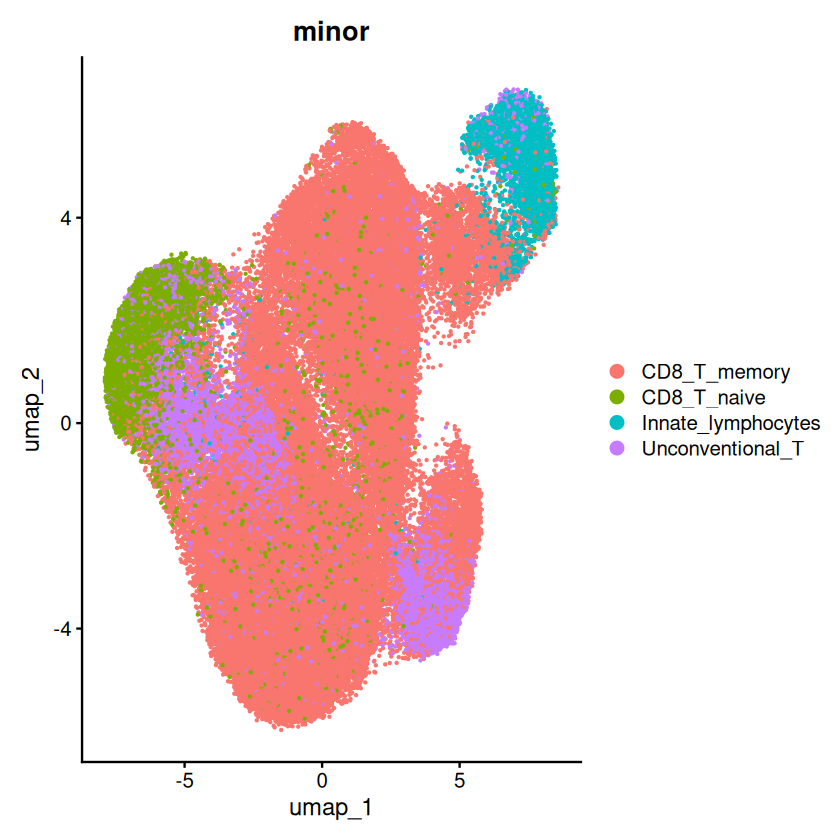

New names:
• `` -> `...1`
Rows: 33075 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): ...1, feature_types, gene_id, gene_symbol
dbl (4): n_cells_by_counts, mean_counts, pct_dropout_by_counts, total_counts
lgl (4): hb, ig, rp, mt

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 103053 Columns: 39
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (20): sample_id, Patient, Disease, Site, Treatment, Inflammation, Gender...
dbl (18): Disease_duration, Age, Inflammation_score, CellsLoaded, doublet_sc...
lgl  (1): predicted_doublets

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Warning message:
“Unknown or uninitialised column: `bc`.”
Warning message:
“Unknow

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 103053
Number of edges: 2946530

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9276
Number of communities: 9
Elapsed time: 75 seconds


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



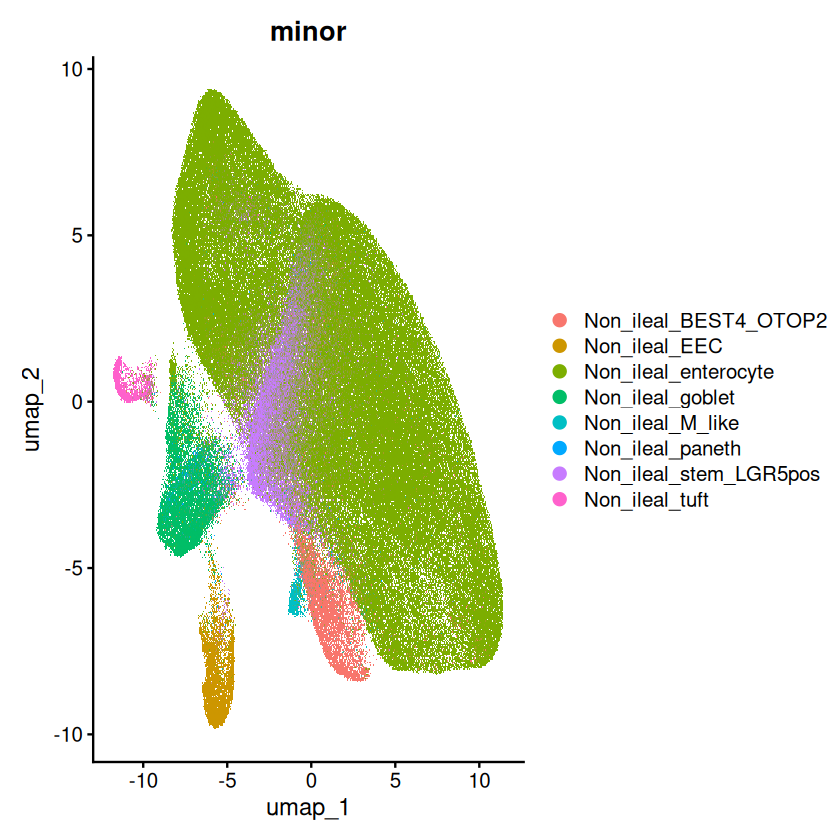

New names:
• `` -> `...1`
Rows: 33075 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): ...1, feature_types, gene_id, gene_symbol
dbl (4): n_cells_by_counts, mean_counts, pct_dropout_by_counts, total_counts
lgl (4): hb, ig, rp, mt

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 3680 Columns: 39
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (20): sample_id, Patient, Disease, Site, Treatment, Inflammation, Gender...
dbl (18): Disease_duration, Age, Inflammation_score, CellsLoaded, doublet_sc...
lgl  (1): predicted_doublets

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Warning message:
“Unknown or uninitialised column: `bc`.”
Warning message:
“Unknown 

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 3680
Number of edges: 112507

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.7933
Number of communities: 3
Elapsed time: 0 seconds


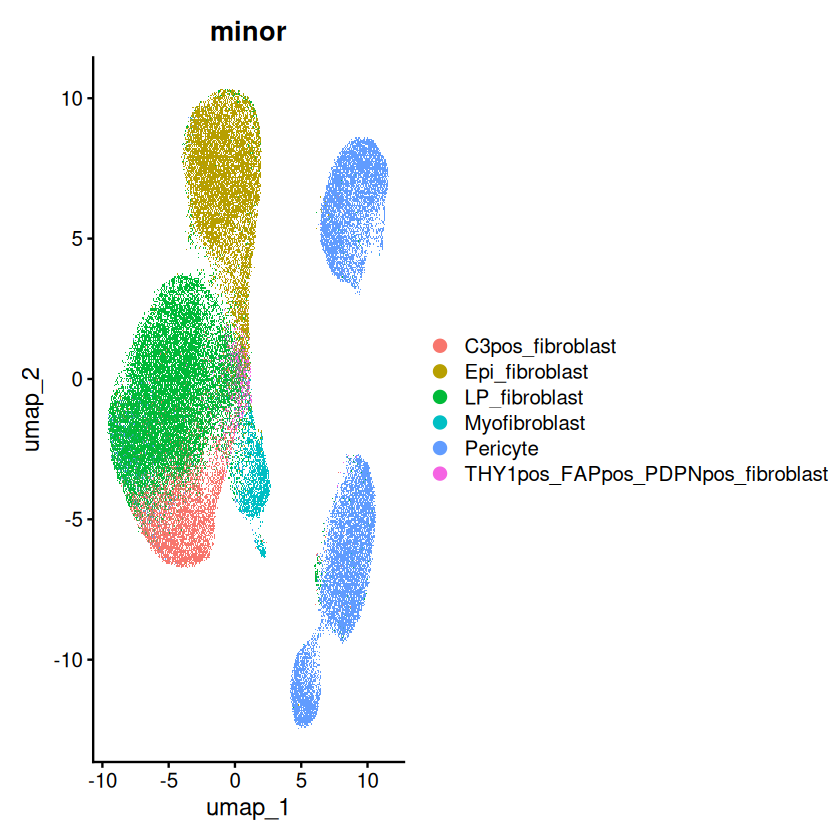

New names:
• `` -> `...1`
Rows: 33075 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): ...1, feature_types, gene_id, gene_symbol
dbl (4): n_cells_by_counts, mean_counts, pct_dropout_by_counts, total_counts
lgl (4): hb, ig, rp, mt

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 49782 Columns: 39
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (20): sample_id, Patient, Disease, Site, Treatment, Inflammation, Gender...
dbl (18): Disease_duration, Age, Inflammation_score, CellsLoaded, doublet_sc...
lgl  (1): predicted_doublets

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Warning message:
“Unknown or uninitialised column: `bc`.”
Warning message:
“Unknown

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 49782
Number of edges: 1466196

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9014
Number of communities: 10
Elapsed time: 29 seconds


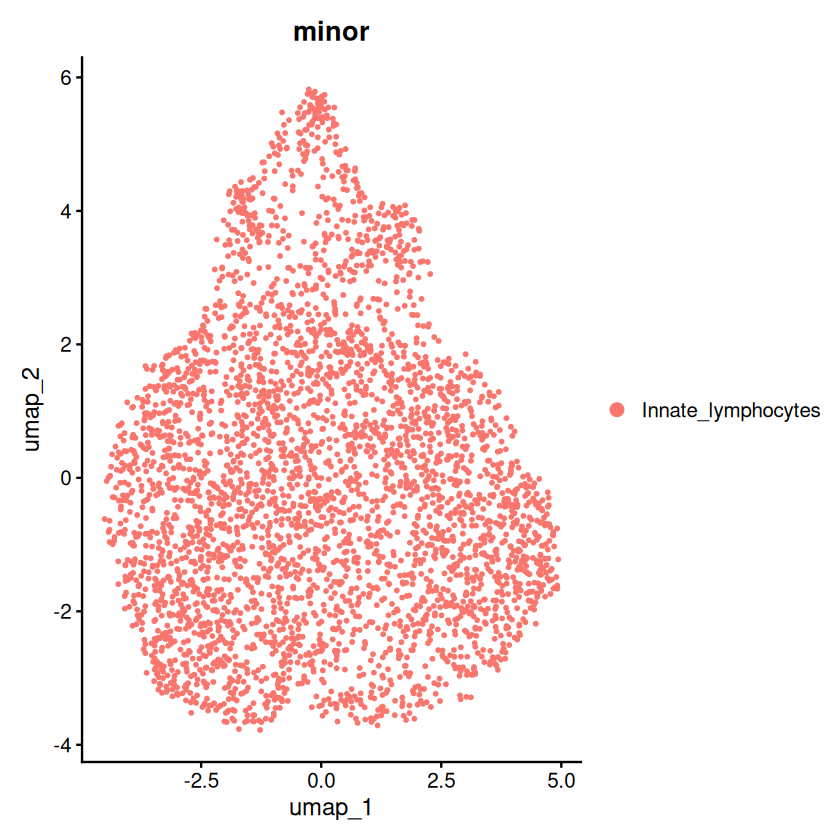

New names:
• `` -> `...1`
Rows: 33075 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): ...1, feature_types, gene_id, gene_symbol
dbl (4): n_cells_by_counts, mean_counts, pct_dropout_by_counts, total_counts
lgl (4): hb, ig, rp, mt

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 30858 Columns: 39
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (20): sample_id, Patient, Disease, Site, Treatment, Inflammation, Gender...
dbl (18): Disease_duration, Age, Inflammation_score, CellsLoaded, doublet_sc...
lgl  (1): predicted_doublets

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Warning message:
“Unknown or uninitialised column: `bc`.”
Warning message:
“Unknown

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 30858
Number of edges: 964635

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9266
Number of communities: 11
Elapsed time: 10 seconds


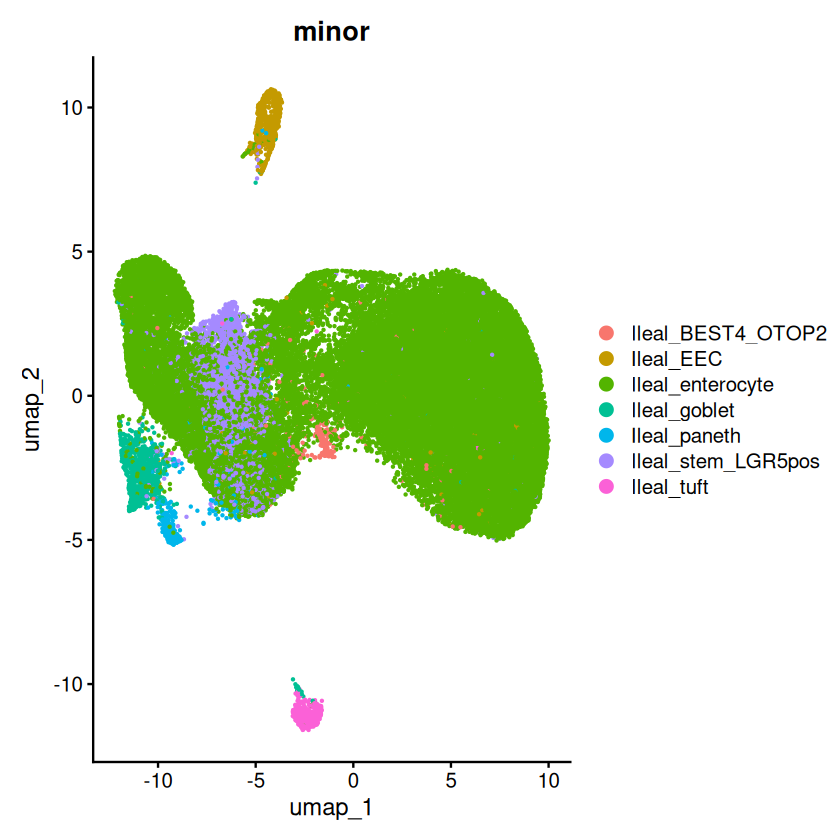

New names:
• `` -> `...1`
Rows: 33075 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): ...1, feature_types, gene_id, gene_symbol
dbl (4): n_cells_by_counts, mean_counts, pct_dropout_by_counts, total_counts
lgl (4): hb, ig, rp, mt

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 141951 Columns: 39
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (20): sample_id, Patient, Disease, Site, Treatment, Inflammation, Gender...
dbl (18): Disease_duration, Age, Inflammation_score, CellsLoaded, doublet_sc...
lgl  (1): predicted_doublets

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Warning message:
“Unknown or uninitialised column: `bc`.”
Warning message:
“Unknow

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 141951
Number of edges: 3590750

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9034
Number of communities: 9
Elapsed time: 107 seconds


Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



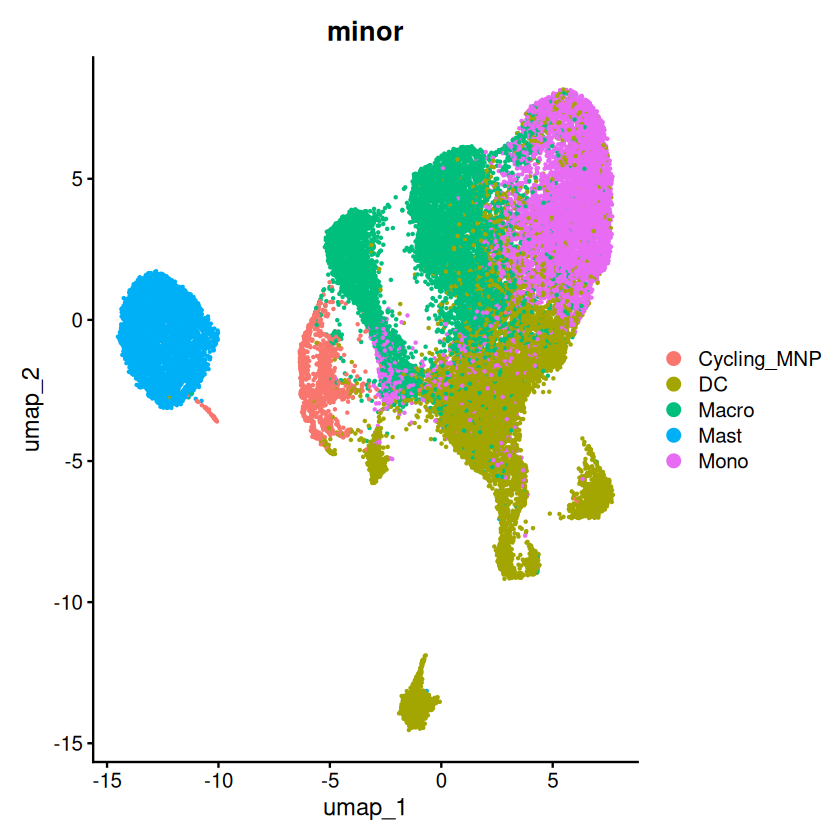

New names:
• `` -> `...1`
Rows: 33075 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (4): ...1, feature_types, gene_id, gene_symbol
dbl (4): n_cells_by_counts, mean_counts, pct_dropout_by_counts, total_counts
lgl (4): hb, ig, rp, mt

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 71809 Columns: 39
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (20): sample_id, Patient, Disease, Site, Treatment, Inflammation, Gender...
dbl (18): Disease_duration, Age, Inflammation_score, CellsLoaded, doublet_sc...
lgl  (1): predicted_doublets

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Warning message:
“Unknown or uninitialised column: `bc`.”
Warning message:
“Unknown

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 71809
Number of edges: 2110781

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9086
Number of communities: 9
Elapsed time: 39 seconds


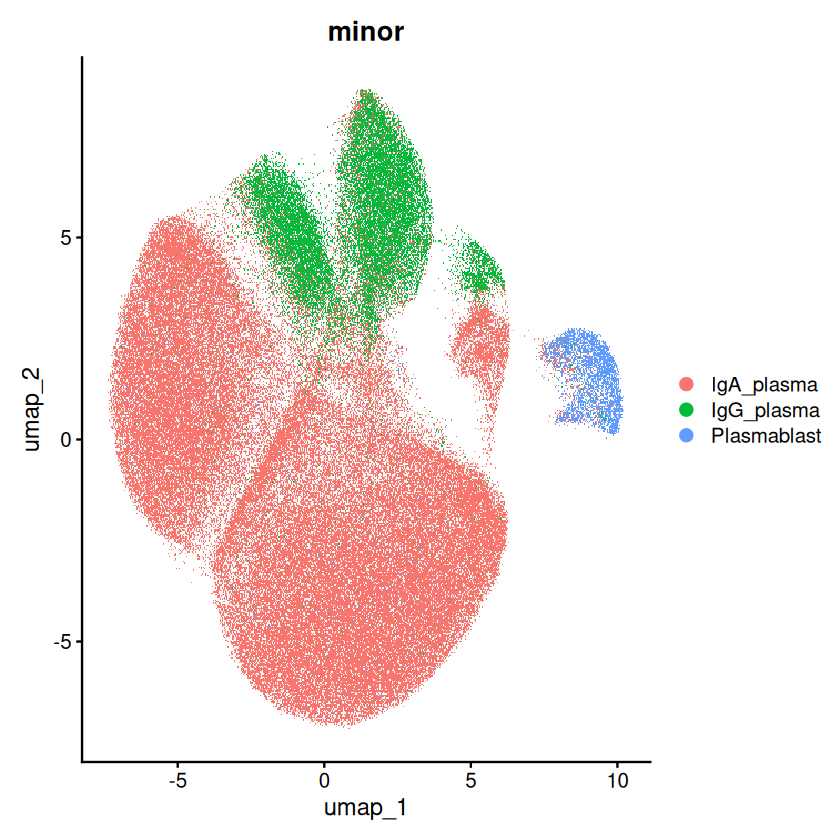

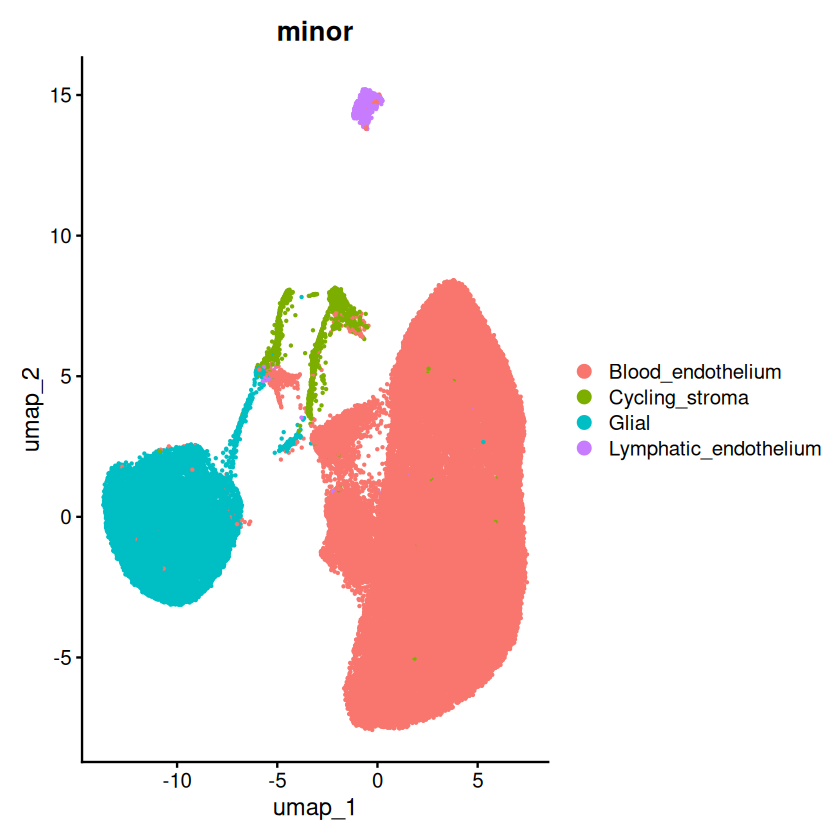

In [36]:
for(i in 2:9){
    process_dataset(i)
}

In [29]:
colnames(seu_dat@meta.data)

[1] "orig.ident"         "nCount_RNA"         "nFeature_RNA"      
 [4] "sample_id"          "Patient"            "Disease"           
 [7] "Site"               "Treatment"          "Disease_duration"  
[10] "Inflammation"       "Age"                "Gender"            
[13] "Ethnicity"          "Inflammation_score" "Ileum_vs_Colon"    
[16] "LibraryType"        "CellsLoaded"        "Match"             
[19] "Batch"              "doublet_scores"     "predicted_doublets"
[22] "n_genes_by_counts"  "total_counts"       "total_counts_mt"   
[25] "pct_counts_mt"      "total_counts_rp"    "pct_counts_rp"     
[28] "total_counts_hb"    "pct_counts_hb"      "total_counts_ig"   
[31] "pct_counts_ig"      "S_score"            "G2M_score"         
[34] "phase"              "cellbarcode"        "diff"              
[37] "final_analysis"     "minor"              "major"             
[40] "sub_bucket"         "bucket"             "Remission_status"  
[43] "bc"                 "RNA_snn_res.0.3"    "seurat_clusters"   
[46] "dataset"

In [97]:
ls()

[1] "all_receptors"               "background_expressed_genes" 
 [3] "best_upstream_ligands"       "celltypes"                  
 [5] "condition_oi"                "condition_reference"        
 [7] "dataset_names"               "DE_table_receiver"          
 [9] "expressed_genes_receiver"    "expressed_genes_sender"     
[11] "expressed_receptors"         "gene_files"                 
[13] "geneset_oi"                  "ggtheme"                    
[15] "i"                           "ligand_activities"          
[17] "ligand_target_matrix"        "list_expressed_genes_sender"
[19] "lr_network"                  "matrices"                   
[21] "md_files"                    "organism"                   
[23] "p_hist_lig_activity"         "paths"                      
[25] "potential_ligands"           "potential_ligands_focused"  
[27] "process_dataset"             "receiver"                   
[29] "sender_celltypes"            "seu"                        
[31] "seu_dat"                     "seu_list"                   
[33] "seu_list_smaller"            "seu_merged"                 
[35] "seurat_obj_receiver"         "thomas_cd4"                 
[37] "vis_ligand_aupr"             "weighted_networks"

In [ ]:
dat_ad_mtx <- readMM("data/published_data/thomas_dat_ad.mtx")

dat_ad_mtx[1:5,1:5]

dat_genes <- read_csv("data/published_data/thomas_dat_ad_genes.csv")

dat_metadata <- read_csv("data/published_data/thomas_dat_ad_meta.csv")

dat_genes
dat_metadata

rownames(dat_ad_mtx) <- dat_metadata$bc
colnames(dat_ad_mtx) <- dat_genes$...1

dat_ad_mtx2 <- t(dat_ad_mtx)


rownames(dat_metadata) <- dat_metadata$bc

seu_dat <- CreateSeuratObject(dat_ad_mtx2, meta.data = dat_metadata)

seu_dat$bc <- colnames(seu_dat)

md_join <- left_join(seu_dat@meta.data, dat_metadata)
rownames(md_join) <- seu_dat$bc


In [ ]:
seu_dat@meta.data <- md_join

seu_dat <- NormalizeData(seu_dat, verbose = FALSE)
seu_dat <- FindVariableFeatures(seu_dat, nfeatures = 1000, verbose = FALSE)
seu_dat <- ScaleData(seu_dat, verbose = FALSE)
seu_dat <- RunPCA(seu_dat, npcs = 10, verbose = FALSE)
seu_dat <- RunUMAP(seu_dat, reduction = "pca", dims = 1:10)
seu_dat <- FindNeighbors(seu_dat, dims = 1:10)
seu_dat <- FindClusters(seu_dat, resolution = 0.3)

## Thomas whole dataset small

In [59]:
paths  <- list.files("data/published_data/thomas/", full.names = T)

In [60]:
dataset_names  <- gsub(list.files("data/published_data/thomas/", full.names = F), pattern = "\\.rds", replacement = "")

In [61]:
dataset_names

[1] "thomas_bcells_ad_genes"       "thomas_cd8tcells_ad_genes"   
 [3] "thomas_epicolonic_ad_genes"   "thomas_fibperi_ad_genes"     
 [5] "thomas_ilc_ad_genes"          "thomas_ilealepi_ad_genes"    
 [7] "thomas_merged_Ileum"          "thomas_myeloid_ad_genes"     
 [9] "thomas_plasmacells_ad_genes"  "thomas_seu_merged_aggregated"
[11] "thomas_vasc_ad_genes"

In [92]:
seu_list  <- list()

In [68]:
for(i in 1:9){
    seu  <-  readRDS(paths[i])
    seu$barcode  <- colnames(seu)
    if(ncol(seu)>10000){
    seu  <- subset(seu, barcode %in% sample(colnames(seu), size = 10000))
        }
    seu_list[[i]]  <- seu
}

In [66]:
seu_list

list()

In [ ]:
seu_list  <- merge(seu_list[1], c(seu_list[2], seu_list[3], seu_list[4], 
                                  seu_list[5], seu_list[6], seu_list[7], 
                                  seu_list[8], seu_list[9]))

In [63]:
thomas_cd4  <- readRDS("data/mapping_data_onto_predict/thomas_query.rds")

In [64]:
thomas_cd4$dataset  <- "CD4"

In [93]:
for(i in 1:9){
    seu  <-  readRDS(paths[i])
    seu$barcode  <- colnames(seu)
    if(ncol(seu)>2000){
    seu  <- subset(seu, barcode %in% sample(colnames(seu), size = 2000))
        }
    seu_list[[i]]  <- seu
}

In [94]:
seu_merged  <- merge(seu_list[[1]], c(seu_list[[2]], seu_list[[3]], seu_list[[4]], 
                                  seu_list[[5]], seu_list[[6]], seu_list[[7]], 
                                  seu_list[[8]], seu_list[[9]], thomas_cd4))

Warning message:
"Some cell names are duplicated across objects provided. Renaming to enforce unique cell names."


In [95]:
seu_merged  <- JoinLayers(seu_merged)

In [96]:
seu_merged$major  %>% table

.
                                B                  C3pos_fibroblast 
                             2217                               222 
                            CD4_T                             CD8_T 
                           146113                              1995 
                      Cycling_MNP                    Cycling_stroma 
                               86                                 2 
                               DC                       Endothelium 
                              672                                74 
                   Epi_fibroblast                        Fibroblast 
                              298                                80 
                            Glial                  Ileal_epithelium 
                               17                              2583 
               Innate_lymphocytes                     LP_fibroblast 
                             2126                               725 
                             Mas

In [97]:
seu_merged@meta.data  <- seu_merged@meta.data  %>% mutate(
    combinedMajorTypes_plus_cd4_ctl = if_else(major == "CD4_T", seurat_clusters, major))

In [98]:
seu_merged$seurat_clusters  %>% table

.
    0     1    10     2     3     4     5     6     7     8     9 
33745 26853    66 22627 19435 18114 13050 12565 11222  4770  1257 

In [99]:
seu_merged$combinedMajorTypes_plus_cd4_ctl  %>% table

.
                                0                                 1 
                            28547                             22455 
                                2                                 3 
                            20035                             17699 
                                4                                 5 
                            16880                             12130 
                                6                                 7 
                            11926                             10817 
                                8                                 9 
                             4490                              1134 
                                B                  C3pos_fibroblast 
                             2217                               222 
                            CD8_T                       Cycling_MNP 
                             1995                                86 
                   Cycling_strom

In [100]:
Idents(seu_merged)  <- seu_merged$combinedMajorTypes_plus_cd4_ctl

In [101]:
library(nichenetr)

In [102]:
receiver = "6"
expressed_genes_receiver <- get_expressed_genes(receiver, seu_merged, pct = 0.05)

In [ ]:
organism <- "human"

if(organism == "human"){
  lr_network <- readRDS(url("https://zenodo.org/record/7074291/files/lr_network_human_21122021.rds"))
  ligand_target_matrix <- readRDS(url("https://zenodo.org/record/7074291/files/ligand_target_matrix_nsga2r_final.rds"))
  weighted_networks <- readRDS(url("https://zenodo.org/record/7074291/files/weighted_networks_nsga2r_final.rds"))
} else if(organism == "mouse"){
  lr_network <- readRDS(url("https://zenodo.org/record/7074291/files/lr_network_mouse_21122021.rds"))
  ligand_target_matrix <- readRDS(url("https://zenodo.org/record/7074291/files/ligand_target_matrix_nsga2r_final_mouse.rds"))
  weighted_networks <- readRDS(url("https://zenodo.org/record/7074291/files/weighted_networks_nsga2r_final_mouse.rds"))

}

lr_network <- lr_network %>% distinct(from, to)
head(lr_network)

In [103]:
all_receptors <- unique(lr_network$to)  
expressed_receptors <- intersect(all_receptors, expressed_genes_receiver)

potential_ligands <- lr_network %>% filter(to %in% expressed_receptors) %>% pull(from) %>% unique()

In [104]:
seu_merged$major  %>% table

.
                                B                  C3pos_fibroblast 
                             2217                               222 
                            CD4_T                             CD8_T 
                           146113                              1995 
                      Cycling_MNP                    Cycling_stroma 
                               86                                 2 
                               DC                       Endothelium 
                              672                                74 
                   Epi_fibroblast                        Fibroblast 
                              298                                80 
                            Glial                  Ileal_epithelium 
                               17                              2583 
               Innate_lymphocytes                     LP_fibroblast 
                             2126                               725 
                             Mas

In [105]:
sender_celltypes <- levels(factor(seu_merged$combinedMajorTypes_plus_cd4_ctl))

# Use lapply to get the expressed genes of every sender cell type separately here
list_expressed_genes_sender <- sender_celltypes %>% unique() %>% lapply(get_expressed_genes, seu_merged, 0.05)
expressed_genes_sender <- list_expressed_genes_sender %>% unlist() %>% unique()

potential_ligands_focused <- intersect(potential_ligands, expressed_genes_sender) 

# Also check 
length(expressed_genes_sender)
## [1] 8492
length(potential_ligands)
## [1] 483
length(potential_ligands_focused)
## [1] 127

Warning message in asMethod(object):
"sparse->dense coercion: allocating vector of size 1.1 GiB"
integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed



[1] 14226

[1] 521

[1] 353

In [106]:
seu_merged$Disease  %>% table

.
     CD Healthy      UC 
  76045    5844   81815 

In [107]:
seu_merged$combinedMajorTypes_plus_cd4_ctl  %>% table

.
                                0                                 1 
                            28547                             22455 
                                2                                 3 
                            20035                             17699 
                                4                                 5 
                            16880                             12130 
                                6                                 7 
                            11926                             10817 
                                8                                 9 
                             4490                              1134 
                                B                  C3pos_fibroblast 
                             2217                               222 
                            CD8_T                       Cycling_MNP 
                             1995                                86 
                   Cycling_strom

In [108]:
condition_oi <-  "CD"
condition_reference <- "Healthy"

seurat_obj_receiver <- subset(seu_merged, combinedMajorTypes_plus_cd4_ctl %in% c(0:9))

DE_table_receiver <-  FindMarkers(object = seurat_obj_receiver,
                                  ident.1 = condition_oi, ident.2 = condition_reference,
                                  group.by = "Disease",
                                  min.pct = 0.05) %>% rownames_to_column("gene")

geneset_oi <- DE_table_receiver %>% filter(p_val_adj <= 0.05 & abs(avg_log2FC) >= 0.25) %>% pull(gene)
geneset_oi <- geneset_oi %>% .[. %in% rownames(ligand_target_matrix)]

In [109]:
background_expressed_genes <- expressed_genes_receiver %>% .[. %in% rownames(ligand_target_matrix)]

length(background_expressed_genes)
## [1] 3476
length(geneset_oi)
## [1] 260

[1] 5424

[1] 507

In [110]:
ligand_activities <- predict_ligand_activities(geneset = geneset_oi,
                                               background_expressed_genes = background_expressed_genes,
                                               ligand_target_matrix = ligand_target_matrix,
                                               potential_ligands = potential_ligands)

In [111]:
ligand_activities <- ligand_activities %>% arrange(-aupr_corrected) %>% arrange(desc(aupr_corrected))
ligand_activities

test_ligand,auroc,aupr,aupr_corrected,pearson
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
IFNG,0.5676661,0.1486895,0.05579832,0.12076471
IL21,0.5585169,0.1424049,0.04951370,0.11677961
IL27,0.5493581,0.1410163,0.04812517,0.11055140
IL4,0.5623011,0.1409460,0.04805485,0.10144980
IL1B,0.5500425,0.1387219,0.04583070,0.10567669
ANGPT2,0.5332487,0.1369225,0.04403130,0.10147521
OSM,0.5494732,0.1367496,0.04385848,0.09137457
IL10,0.5584185,0.1356623,0.04277113,0.10232674
JAM2,0.5639587,0.1352277,0.04233657,0.07660937


`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


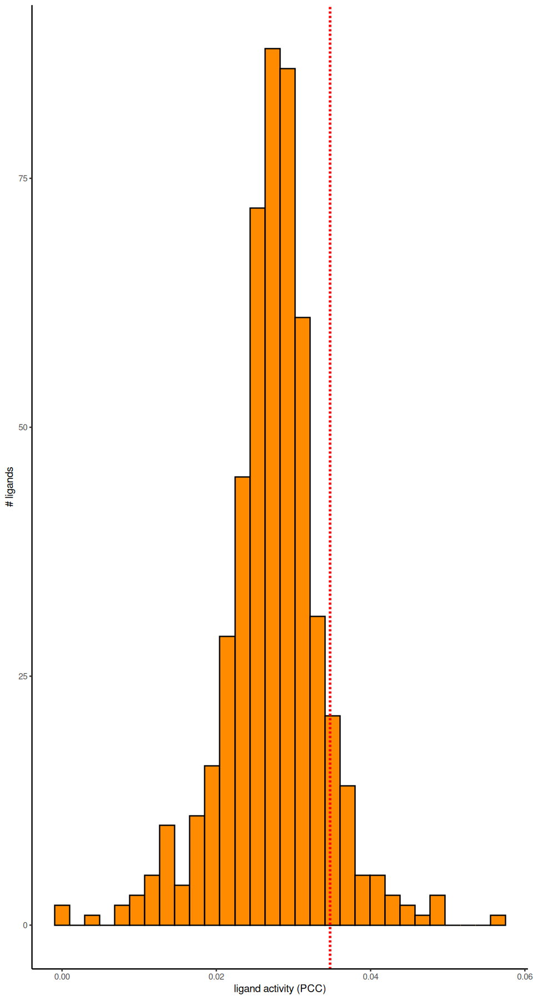

In [112]:
p_hist_lig_activity <- ggplot(ligand_activities, aes(x=aupr_corrected)) + 
  geom_histogram(color="black", fill="darkorange")  + 
  geom_vline(aes(xintercept=min(ligand_activities %>% top_n(50, aupr_corrected) %>% pull(aupr_corrected))),
             color="red", linetype="dashed", size=1) + 
  labs(x="ligand activity (PCC)", y = "# ligands") +
  theme_classic()

p_hist_lig_activity

In [113]:
best_upstream_ligands <- ligand_activities %>% top_n(50, aupr_corrected) %>% arrange(-aupr_corrected) %>% pull(test_ligand)

In [114]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


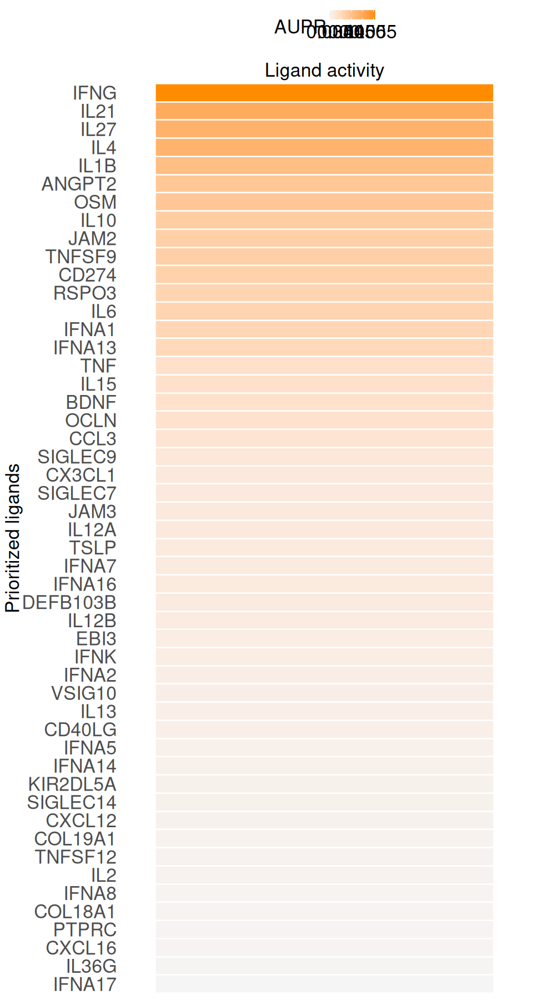

In [115]:
options(repr.plot.width = 8, repr.plot.height = 15)
vis_ligand_aupr <- ligand_activities %>% filter(test_ligand %in% best_upstream_ligands) %>%
  column_to_rownames("test_ligand") %>% select(aupr_corrected) %>% arrange(aupr_corrected) %>% as.matrix(ncol = 1)

(make_heatmap_ggplot(vis_ligand_aupr,
                     "Prioritized ligands", "Ligand activity", 
                     legend_title = "AUPR", color = "darkorange") + 
    theme(axis.text.x.top = element_blank())) + ggtheme()

In [116]:
saveRDS(seu_merged, "data/published_data/thomas/thomas_merged_subset_for_nichenet_2000.rds")

## Il27 expression

In [2]:
paths  <- list.files("data/published_data/thomas/", full.names = T)

In [3]:
dataset_names  <- gsub(list.files("data/published_data/thomas/", full.names = F), pattern = "\\.rds", replacement = "")

In [4]:
dataset_names

[1] "thomas_bcells_ad_genes"                
 [2] "thomas_cd8tcells_ad_genes"             
 [3] "thomas_epicolonic_ad_genes"            
 [4] "thomas_fibperi_ad_genes"               
 [5] "thomas_ilc_ad_genes"                   
 [6] "thomas_ilealepi_ad_genes"              
 [7] "thomas_merged_Ileum"                   
 [8] "thomas_merged_subset_for_nichenet_2000"
 [9] "thomas_merged_subset_for_nichenet"     
[10] "thomas_myeloid_ad_genes"               
[11] "thomas_plasmacells_ad_genes"           
[12] "thomas_seu_merged_aggregated"          
[13] "thomas_vasc_ad_genes"

In [7]:
dataset_names  <- dataset_names[!grepl(dataset_names, pattern = "merged")]

In [8]:
seu_list  <- list()

In [10]:
paths

[1] "data/published_data/thomas//thomas_bcells_ad_genes.rds"                
 [2] "data/published_data/thomas//thomas_cd8tcells_ad_genes.rds"             
 [3] "data/published_data/thomas//thomas_epicolonic_ad_genes.rds"            
 [4] "data/published_data/thomas//thomas_fibperi_ad_genes.rds"               
 [5] "data/published_data/thomas//thomas_ilc_ad_genes.rds"                   
 [6] "data/published_data/thomas//thomas_ilealepi_ad_genes.rds"              
 [7] "data/published_data/thomas//thomas_merged_Ileum.rds"                   
 [8] "data/published_data/thomas//thomas_merged_subset_for_nichenet_2000.rds"
 [9] "data/published_data/thomas//thomas_merged_subset_for_nichenet.rds"     
[10] "data/published_data/thomas//thomas_myeloid_ad_genes.rds"               
[11] "data/published_data/thomas//thomas_plasmacells_ad_genes.rds"           
[12] "data/published_data/thomas//thomas_seu_merged_aggregated.rds"          
[13] "data/published_data/thomas//thomas_vasc_ad_genes.rds"

In [11]:
paths  <- paths[!grepl(paths, pattern = "merged")]

In [12]:
for(i in 1:9){
    seu  <-  readRDS(paths[i])
    md  <- seu@meta.data
    md$IL_27  <- seu@assays$RNA@layers$data[which(rownames(seu@assays$RNA)=="IL27"),]
    md$dataset  <- dataset_names[i]
    if(i == 1){
        md_all  <- md
    } else {
        md_all  <- rbind(md_all, md)
    }
}

In [13]:
summary(md_all$IL_27)

    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
0.000000 0.000000 0.000000 0.001436 0.000000 3.421968 

In [14]:
colnames(md)

[1] "orig.ident"         "nCount_RNA"         "nFeature_RNA"      
 [4] "sample_id"          "Patient"            "Disease"           
 [7] "Site"               "Treatment"          "Disease_duration"  
[10] "Inflammation"       "Age"                "Gender"            
[13] "Ethnicity"          "Inflammation_score" "Ileum_vs_Colon"    
[16] "LibraryType"        "CellsLoaded"        "Match"             
[19] "Batch"              "doublet_scores"     "predicted_doublets"
[22] "n_genes_by_counts"  "total_counts"       "total_counts_mt"   
[25] "pct_counts_mt"      "total_counts_rp"    "pct_counts_rp"     
[28] "total_counts_hb"    "pct_counts_hb"      "total_counts_ig"   
[31] "pct_counts_ig"      "S_score"            "G2M_score"         
[34] "phase"              "cellbarcode"        "diff"              
[37] "final_analysis"     "minor"              "major"             
[40] "sub_bucket"         "bucket"             "Remission_status"  
[43] "bc"                 "RNA_snn_res.0.3"    "seurat_clusters"   
[46] "dataset"            "IL_27"

In [15]:
library(dplyr)

In [16]:
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major)  %>% 
summarise(avg_IL27 = mean(IL_27))

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation'. You can override using the `.groups` argument.


sample_id,Patient,Disease,Site,Treatment,Inflammation,major,avg_IL27
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>
CID003352-2,UC1,UC,Rectum,Post,Inflamed,B,0.0000000000
CID003352-2,UC1,UC,Rectum,Post,Inflamed,C3pos_fibroblast,0.0000000000
CID003352-2,UC1,UC,Rectum,Post,Inflamed,CD8_T,0.0000000000
CID003352-2,UC1,UC,Rectum,Post,Inflamed,Cycling_MNP,0.0786715958
CID003352-2,UC1,UC,Rectum,Post,Inflamed,Cycling_stroma,0.0000000000
CID003352-2,UC1,UC,Rectum,Post,Inflamed,DC,0.0480500316
CID003352-2,UC1,UC,Rectum,Post,Inflamed,Endothelium,0.0000000000
CID003352-2,UC1,UC,Rectum,Post,Inflamed,Epi_fibroblast,0.0000000000
CID003352-2,UC1,UC,Rectum,Post,Inflamed,Fibroblast,0.0000000000


In [17]:
library(ggplot2)
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation'. You can override using the `.groups` argument.


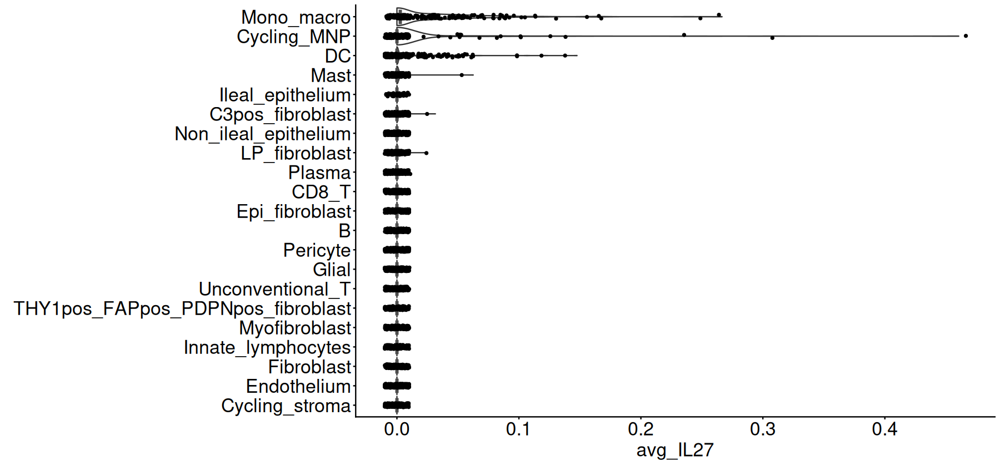

In [18]:
options(repr.plot.width = 15, repr.plot.height = 7)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
ggplot(aes(x = reorder(major, X = avg_IL27, FUN = mean, decreasing = F), y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width") +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
geom_jitter(width = 0.1, height = 0.01, size = 1) + theme_classic() + ggtheme() + coord_flip() + xlab("")

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation'. You can override using the `.groups` argument.


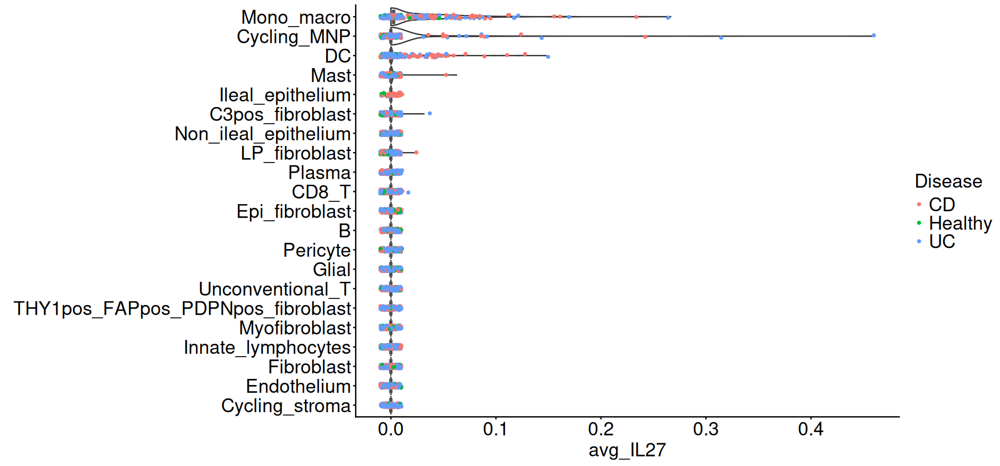

In [19]:
options(repr.plot.width = 15, repr.plot.height = 7)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
ggplot(aes(x = reorder(major, X = avg_IL27, FUN = mean, decreasing = F), y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width") +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
geom_jitter(width = 0.1, height = 0.01, size = 1, aes(color = Disease)) + theme_classic() + ggtheme() + coord_flip() + xlab("")

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation'. You can override using the `.groups` argument.
Warning message:
“Groups with fewer than two datapoints have been dropped.
ℹ Set `drop = FALSE` to consider such groups for position adjustment purposes.”


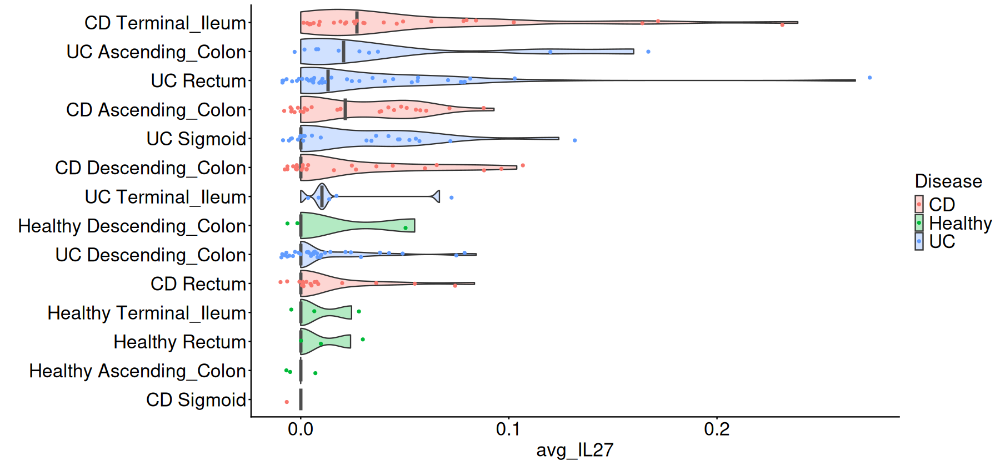

In [20]:
options(repr.plot.width = 15, repr.plot.height = 7)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
dplyr::filter(major == "Mono_macro")  %>% 
mutate(Disease_Site = paste(Disease, Site))  %>% 
ggplot(aes(x = reorder(Disease_Site, X = avg_IL27, FUN = mean, decreasing = F), y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width", aes(fill = Disease)) +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
geom_jitter(width = 0.1, height = 0.01, size = 1, aes(color = Disease)) + theme_classic() + ggtheme() + coord_flip() + xlab("")

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation'. You can override using the `.groups` argument.


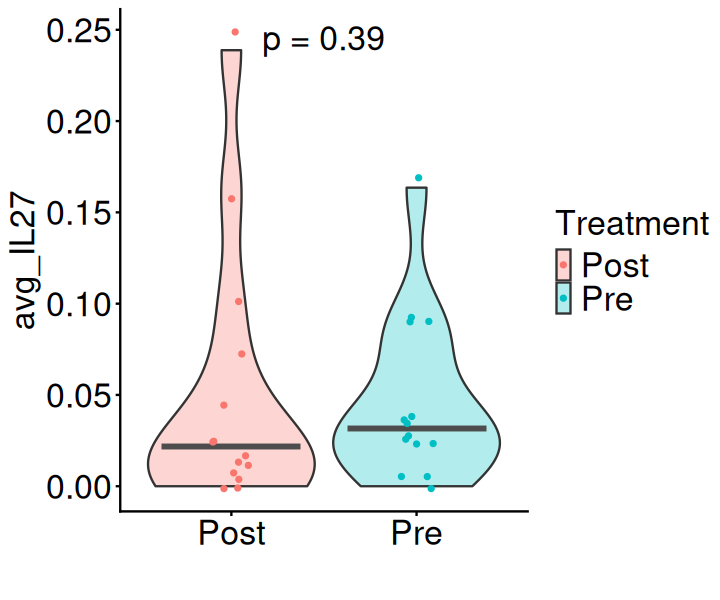

In [21]:
options(repr.plot.width = 6, repr.plot.height = 5)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
dplyr::filter(major == "Mono_macro")  %>% 
mutate(Disease_Site = paste(Disease, Site))  %>% 
dplyr::filter(Disease_Site == "CD Terminal_Ileum")  %>% 
ggplot(aes(x = Treatment, y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width", aes(fill = Treatment)) +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
geom_jitter(width = 0.1, height = 0.01, size = 1, aes(color = Treatment)) + theme_classic() + ggtheme() + xlab("") +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.3)

In [22]:
colnames(md_all)

[1] "orig.ident"         "nCount_RNA"         "nFeature_RNA"      
 [4] "sample_id"          "Patient"            "Disease"           
 [7] "Site"               "Treatment"          "Disease_duration"  
[10] "Inflammation"       "Age"                "Gender"            
[13] "Ethnicity"          "Inflammation_score" "Ileum_vs_Colon"    
[16] "LibraryType"        "CellsLoaded"        "Match"             
[19] "Batch"              "doublet_scores"     "predicted_doublets"
[22] "n_genes_by_counts"  "total_counts"       "total_counts_mt"   
[25] "pct_counts_mt"      "total_counts_rp"    "pct_counts_rp"     
[28] "total_counts_hb"    "pct_counts_hb"      "total_counts_ig"   
[31] "pct_counts_ig"      "S_score"            "G2M_score"         
[34] "phase"              "cellbarcode"        "diff"              
[37] "final_analysis"     "minor"              "major"             
[40] "sub_bucket"         "bucket"             "Remission_status"  
[43] "bc"                 "RNA_snn_res.0.3"    "seurat_clusters"   
[46] "dataset"            "IL_27"

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation', 'major'. You can override using the `.groups`
argument.


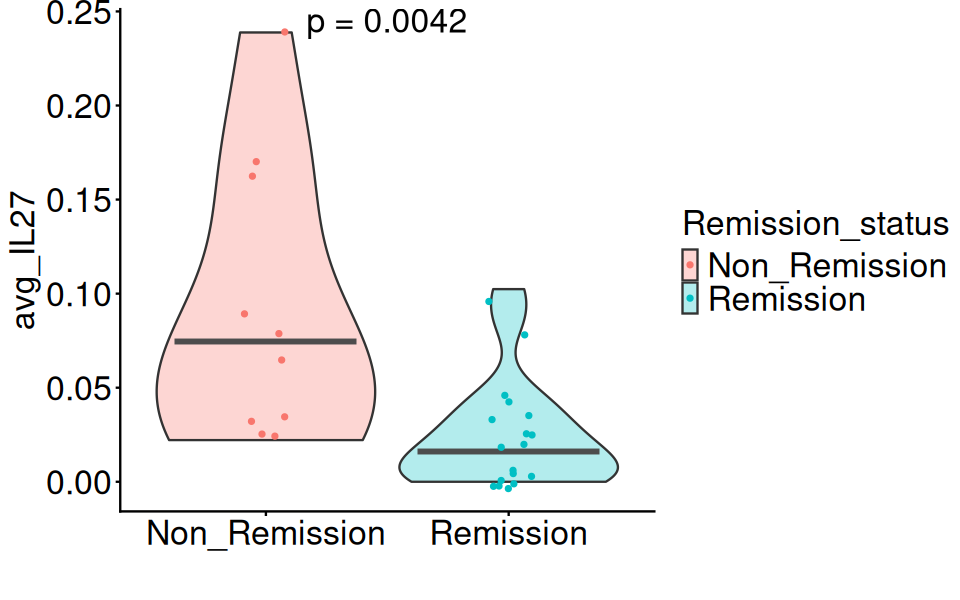

In [27]:
###### options(repr.plot.width = 8, repr.plot.height = 5)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major, Remission_status)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
dplyr::filter(major == "Mono_macro")  %>% 
mutate(Disease_Site = paste(Disease, Site))  %>% 
dplyr::filter(Disease_Site == "CD Terminal_Ileum")  %>% 
ggplot(aes(x = Remission_status, y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width", aes(fill = Remission_status)) +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
geom_jitter(width = 0.1, height = 0.01, size = 1, aes(color = Remission_status)) + theme_classic() + ggtheme() + xlab("") +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.3) 

In [33]:
md_all  %>%
mutate(Disease_Site = paste(Disease, Site))  %>% 
dplyr::filter(Disease_Site == "CD Terminal_Ileum")  %>% 
group_by(Remission_status, Treatment, Patient)  %>% tally()  %>% 
dplyr::select(-n)  %>% ungroup()  %>% 
group_by(Remission_status, Treatment)  %>% tally() 

Remission_status,Treatment,n
<chr>,<chr>,<int>
Non_Remission,Post,5
Non_Remission,Pre,5
Remission,Post,9
Remission,Pre,9


`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation', 'major'. You can override using the `.groups`
argument.


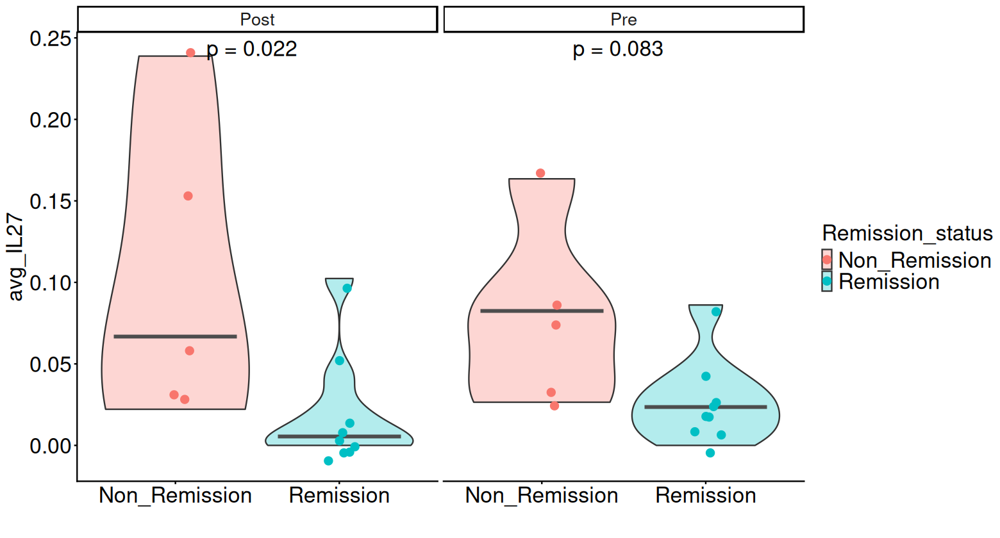

In [133]:
options(repr.plot.width = 13, repr.plot.height = 7)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major, Remission_status)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
dplyr::filter(major == "Mono_macro")  %>% 
mutate(Disease_Site = paste(Disease, Site))  %>% 
dplyr::filter(Disease_Site == "CD Terminal_Ileum")  %>% 
ggplot(aes(x = Remission_status, y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width", aes(fill = Remission_status)) +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
facet_wrap(~Treatment) +
geom_jitter(width = 0.1, height = 0.01, size = 3, aes(color = Remission_status)) + theme_classic() + ggtheme() + xlab("") +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.3) 

In [134]:
ggsave("figures/thomas/IL27_myeloid_cells.svg", width = 16, height = 9, units = "cm")

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation'. You can override using the `.groups` argument.


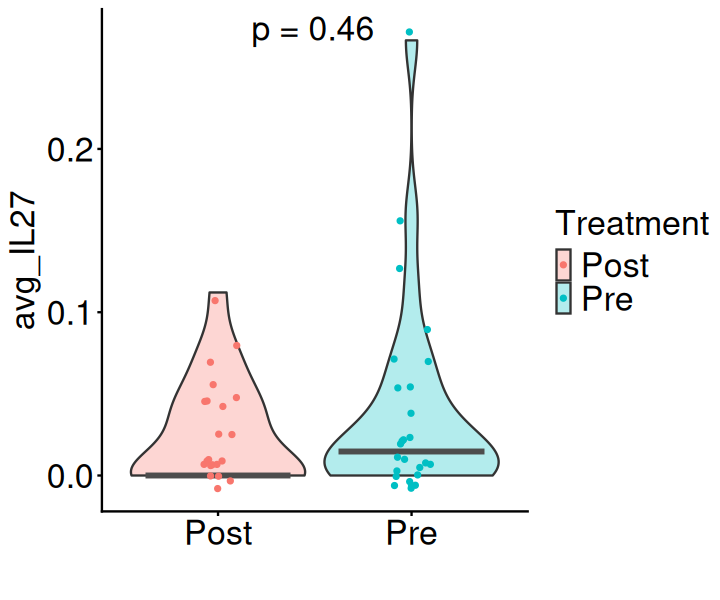

In [24]:
options(repr.plot.width = 6, repr.plot.height = 5)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, major)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
dplyr::filter(major == "Mono_macro")  %>% 
mutate(Disease_Site = paste(Disease, Site))  %>% 
dplyr::filter(Disease_Site %in% c("UC Ascending_Colon" , "UC Rectum"))  %>% 
ggplot(aes(x = Treatment, y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width", aes(fill = Treatment)) +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
geom_jitter(width = 0.1, height = 0.01, size = 1, aes(color = Treatment)) + theme_classic() + ggtheme() + xlab("") +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.3)

`summarise()` has grouped output by 'sample_id', 'Patient', 'Disease', 'Site',
'Treatment', 'Inflammation', 'Remission_status'. You can override using the
`.groups` argument.


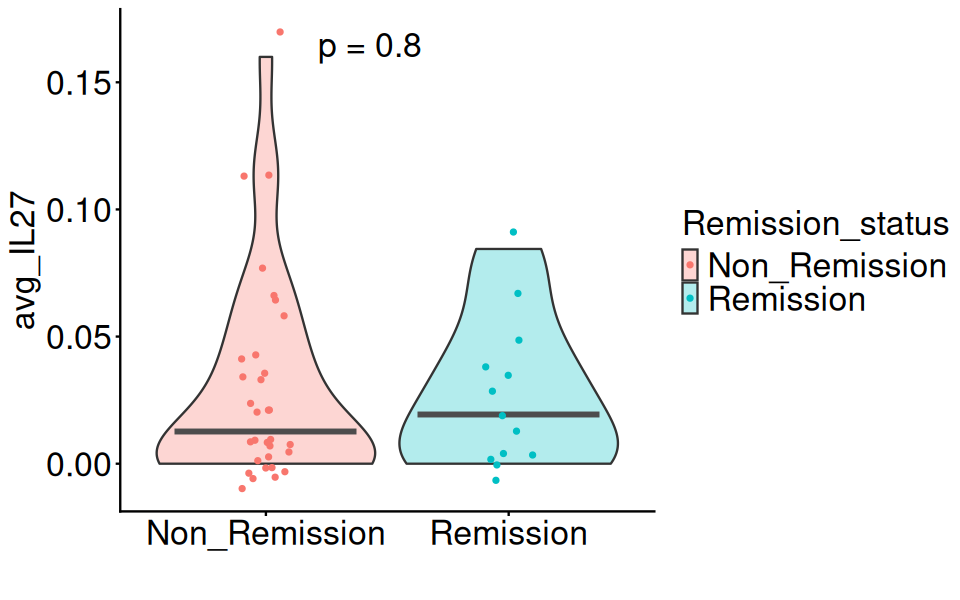

In [25]:
options(repr.plot.width = 8, repr.plot.height = 5)
md_all  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation, Remission_status, major)  %>% 
summarise(avg_IL27 = mean(IL_27))  %>% 
dplyr::filter(major == "Mono_macro")  %>% 
mutate(Disease_Site = paste(Disease, Site))  %>% 
dplyr::filter(Disease_Site %in% c("UC Ascending_Colon" , "UC Rectum") & Remission_status != "Not_avail")  %>% 
ggplot(aes(x = Remission_status, y = avg_IL27)) +
geom_violin(alpha = 0.3, scale = "width", aes(fill = Remission_status)) +
  stat_summary(fun = "median",
               geom = "crossbar", 
               width = 0.75,
               color = "grey30") +
geom_jitter(width = 0.1, height = 0.01, size = 1, aes(color = Remission_status)) + theme_classic() + ggtheme() + xlab("") +
ggpubr::stat_compare_means(label = "p.format", size = 7, label.x = 1.3)

# Expression heatmap and volcano CD vs Healthy

In [1]:
paths  <- list.files("data/published_data/thomas/", full.names = T)

In [2]:
dataset_names  <- gsub(list.files("data/published_data/thomas/", full.names = F), pattern = "\\.rds", replacement = "")

In [3]:
dataset_names

[1] "thomas_bcells_ad_genes"      "thomas_cd8tcells_ad_genes"  
 [3] "thomas_epicolonic_ad_genes"  "thomas_fibperi_ad_genes"    
 [5] "thomas_ilc_ad_genes"         "thomas_ilealepi_ad_genes"   
 [7] "thomas_merged_Ileum"         "thomas_myeloid_ad_genes"    
 [9] "thomas_plasmacells_ad_genes" "thomas_vasc_ad_genes"

In [4]:
mtx_list  <- list()

In [5]:
genes_of_interest  <- c('IFNG',
'IL27',
'IL21',
'IL4',
'IL1B',
'ANGPT2',
'IFNA1',
'IL10',
'OSM',
'TNFSF9',
'JAM2',
'IL6',
'CD274',
'RSPO3',
'IFNA13',
'TNF',
'TSLP',
'BDNF',
'IL15',
'IL12A',
'CCL3',
'IFNA7',
'SIGLEC9',
'IFNA16',
'SIGLEC7',
'OCLN',
'IFNB1',
'IFNK',
'IL12B',
'EBI3')


In [8]:
for(i in 1:9){
    seu  <-  readRDS(paths[i])
    md  <- seu@meta.data
    aggexp  <- AggregateExpression(seu, group.by = c("sample_id","major"),
                                   features = genes_of_interest, return.seurat = T)
    aggexp$source  <- dataset_names[i]
    mtx_list[[i]]  <- aggexp
    
}

The following grouping variables have 1 value and will be ignored: major

Centering and scaling data matrix

Names of identity class contain underscores ('_'), replacing with dashes ('-')
This message is displayed once every 8 hours.
Centering and scaling data matrix

The following grouping variables have 1 value and will be ignored: major

Centering and scaling data matrix

Centering and scaling data matrix

The following grouping variables have 1 value and will be ignored: major

Centering and scaling data matrix

The following grouping variables have 1 value and will be ignored: major

Centering and scaling data matrix

Warning message:
“The counts layer for the integrated assay is empty. Skipping assay.”
Warning message:
“The counts layer for the prediction.score.id assay is empty. Skipping assay.”
Centering and scaling data matrix

Centering and scaling data matrix

The following grouping variables have 1 value and will be ignored: major

Centering and scaling data matrix



In [9]:
mtx_list

[[1]]
An object of class Seurat 
30 features across 215 samples within 1 assay 
Active assay: RNA (30 features, 0 variable features)
 3 layers present: counts, data, scale.data

[[2]]
An object of class Seurat 
30 features across 643 samples within 1 assay 
Active assay: RNA (30 features, 0 variable features)
 3 layers present: counts, data, scale.data

[[3]]
An object of class Seurat 
30 features across 180 samples within 1 assay 
Active assay: RNA (30 features, 0 variable features)
 3 layers present: counts, data, scale.data

[[4]]
An object of class Seurat 
30 features across 1310 samples within 1 assay 
Active assay: RNA (30 features, 0 variable features)
 3 layers present: counts, data, scale.data

[[5]]
An object of class Seurat 
30 features across 216 samples within 1 assay 
Active assay: RNA (30 features, 0 variable features)
 3 layers present: counts, data, scale.data

[[6]]
An object of class Seurat 
30 features across 36 samples within 1 assay 
Active assay: RNA (30 features

In [10]:
colnames(mtx_list[[2]])

[1] "CID003352-2_CD8-T"              "CID003352-2_Innate-lymphocytes"
  [3] "CID003352-2_Unconventional-T"   "CID003353-1_CD8-T"             
  [5] "CID003353-1_Innate-lymphocytes" "CID003353-1_Unconventional-T"  
  [7] "CID003354-1_CD8-T"              "CID003354-1_Innate-lymphocytes"
  [9] "CID003354-1_Unconventional-T"   "CID003355-1_CD8-T"             
 [11] "CID003355-1_Innate-lymphocytes" "CID003355-1_Unconventional-T"  
 [13] "CID003356-1_CD8-T"              "CID003356-1_Innate-lymphocytes"
 [15] "CID003356-1_Unconventional-T"   "CID003357-1_CD8-T"             
 [17] "CID003357-1_Innate-lymphocytes" "CID003357-1_Unconventional-T"  
 [19] "CID003359-1_CD8-T"              "CID003359-1_Innate-lymphocytes"
 [21] "CID003359-1_Unconventional-T"   "CID003360-1_CD8-T"             
 [23] "CID003360-1_Innate-lymphocytes" "CID003360-1_Unconventional-T"  
 [25] "CID003361-1_CD8-T"              "CID003361-1_Innate-lymphocytes"
 [27] "CID003361-1_Unconventional-T"   "CID003362-1_CD8-T"             
 [29] "CID003362-1_Innate-lymphocytes" "CID003362-1_Unconventional-T"  
 [31] "CID003363-1_CD8-T"              "CID003363-1_Innate-lymphocytes"
 [33] "CID003363-1_Unconventional-T"   "CID003364-1_CD8-T"             
 [35] "CID003364-1_Innate-lymphocytes" "CID003364-1_Unconventional-T"  
 [37] "CID003365-1_CD8-T"              "CID003365-1_Innate-lymphocytes"
 [39] "CID003365-1_Unconventional-T"   "CID003366-1_CD8-T"             
 [41] "CID003366-1_Innate-lymphocytes" "CID003366-1_Unconventional-T"  
 [43] "CID003367-2_CD8-T"              "CID003367-2_Innate-lymphocytes"
 [45] "CID003367-2_Unconventional-T"   "CID003368-1_CD8-T"             
 [47] "CID003368-1_Innate-lymphocytes" "CID003368-1_Unconventional-T"  
 [49] "CID003369-1_CD8-T"              "CID003369-1_Innate-lymphocytes"
 [51] "CID003369-1_Unconventional-T"   "CID003370-1_CD8-T"             
 [53] "CID003370-1_Innate-lymphocytes" "CID003370-1_Unconventional-T"  
 [55] "CID003371-2_CD8-T"              "CID003371-2_Innate-lymphocytes"
 [57] "CID003371-2_Unconventional-T"   "CID003372-1_CD8-T"             
 [59] "CID003372-1_Innate-lymphocytes" "CID003372-1_Unconventional-T"  
 [61] "CID003373-1_CD8-T"              "CID003373-1_Innate-lymphocytes"
 [63] "CID003373-1_Unconventional-T"   "CID003374-1_CD8-T"             
 [65] "CID003374-1_Innate-lymphocytes" "CID003374-1_Unconventional-T"  
 [67] "CID003375-1_CD8-T"              "CID003375-1_Innate-lymphocytes"
 [69] "CID003375-1_Unconventional-T"   "CID003376-1_CD8-T"             
 [71] "CID003376-1_Innate-lymphocytes" "CID003376-1_Unconventional-T"  
 [73] "CID003377-1_CD8-T"              "CID003377-1_Innate-lymphocytes"
 [75] "CID003377-1_Unconventional-T"   "CID003378-1_CD8-T"             
 [77] "CID003378-1_Innate-lymphocytes" "CID003378-1_Unconventional-T"  
 [79] "CID003379-1_CD8-T"              "CID003379-1_Innate-lymphocytes"
 [81] "CID003379-1_Unconventional-T"   "CID003380-1_CD8-T"             
 [83] "CID003380-1_Innate-lymphocytes" "CID003380-1_Unconventional-T"  
 [85] "CID003381-1_CD8-T"              "CID003381-1_Innate-lymphocytes"
 [87] "CID003381-1_Unconventional-T"   "CID003382-1_CD8-T"             
 [89] "CID003382-1_Innate-lymphocytes" "CID003382-1_Unconventional-T"  
 [91] "CID003383-1_CD8-T"              "CID003383-1_Innate-lymphocytes"
 [93] "CID003383-1_Unconventional-T"   "CID003384-1_CD8-T"             
 [95] "CID003384-1_Innate-lymphocytes" "CID003384-1_Unconventional-T"  
 [97] "CID003385-1_CD8-T"              "CID003385-1_Innate-lymphocytes"
 [99] "CID003385-1_Unconventional-T"   "CID003386-1_CD8-T"             
[101] "CID003386-1_Innate-lymphocytes" "CID003386-1_Unconventional-T"  
[103] "CID003665-1_CD8-T"              "CID003665-1_Innate-lymphocytes"
[105] "CID003665-1_Unconventional-T"   "CID003666-1_CD8-T"             
[107] "CID003666-1_Innate-lymphocytes" "CID003666-1_Unconventional-T"  
[109] "CID003667-1_CD8-T"              "CID003667-1_Innate-lymphocytes"
[111] "CID003667-1_Unconventional-T"   "CI

In [11]:
seu_merged  <- merge(mtx_list[[1]], c(mtx_list[[2]], mtx_list[[3]], mtx_list[[4]],
                                     mtx_list[[5]], mtx_list[[6]], mtx_list[[7]],
                                     mtx_list[[8]], mtx_list[[9]]))

Warning message:
“Some cell names are duplicated across objects provided. Renaming to enforce unique cell names.”


In [12]:
seu_merged  <- JoinLayers(seu_merged)

In [13]:
seu_merged  %>% colnames

[1] "CID003352-2_1"                                  
   [2] "CID003353-1_1"                                  
   [3] "CID003354-1_1"                                  
   [4] "CID003355-1_1"                                  
   [5] "CID003356-1_1"                                  
   [6] "CID003357-1_1"                                  
   [7] "CID003359-1_1"                                  
   [8] "CID003360-1_1"                                  
   [9] "CID003361-1_1"                                  
  [10] "CID003362-1_1"                                  
  [11] "CID003363-1_1"                                  
  [12] "CID003364-1_1"                                  
  [13] "CID003365-1_1"                                  
  [14] "CID003366-1_1"                                  
  [15] "CID003367-2_1"                                  
  [16] "CID003368-1_1"                                  
  [17] "CID003369-1_1"                                  
  [18] "CID003370-1_1"                                  
  [19] "CID003371-2_1"                                  
  [20] "CID003372-1_1"                                  
  [21] "CID003373-1_1"                                  
  [22] "CID003374-1_1"                                  
  [23] "CID003375-1_1"                                  
  [24] "CID003376-1_1"                                  
  [25] "CID003377-1_1"                                  
  [26] "CID003378-1_1"                                  
  [27] "CID003379-1_1"                                  
  [28] "CID003380-1_1"                                  
  [29] "CID003381-1_1"                                  
  [30] "CID003382-1_1"                                  
  [31] "CID003383-1_1"                                  
  [32] "CID003384-1_1"                                  
  [33] "CID003385-1_1"                                  
  [34] "CID003386-1_1"                                  
  [35] "CID003665-1_1"                                  
  [36] "CID003666-1_1"                                  
  [37] "CID003667-1_1"                                  
  [38] "CID003669-1_1"                                  
  [39] "CID003670-1_1"                                  
  [40] "CID003671-1_1"                                  
  [41] "CID003672-1_1"                                  
  [42] "CID003673-1_1"                                  
  [43] "CID003674-1_1"                                  
  [44] "CID003675-1_1"                                  
  [45] "CID003676-2_1"                                  
  [46] "CID003677-1_1"                                  
  [47] "CID003678-1_1"                                  
  [48] "CID003679-1_1"                                  
  [49] "CID003680-1_1"                                  
  [50] "CID003681-1_1"                                  
  [51] "CID003682-1_1"                                  
  [52] "CID003683-1_1"                                  
  [53] "CID004696-1_1"                                  
  [54] "CID004697-1_1"                                  
  [55] "CID004698-1_1"                                  
  [56] "CID004699-1_1"                                  
  [57] "CID004700-1_1"                                  
  [58] "CID004701-1_1"                                  
  [59] "CID004702-1_1"                                  
  [60] "CID004703-1_1"                                  
  [61] "CID004704-1_1"                                  
  [62] "CID004705-1_1"                                  
  [63] "CID004706-1_1"                                  
  [64] "CID004707-1_1"                                  
  [65] "CID004708-1_1"                                  
  [66] "CID004709-1_1"                                  
  [67] "CID004710-1_1"                                  
  [68] "CID004711-1_1"                                  
  [69] "CID004712-1_1"                                  
  [70] "CID004713-1_1"                                  
  [71] "CID00

In [14]:
seu_merged$major  %>% table

.
                                B                  C3pos-fibroblast 
                               36                               231 
                            CD4-T                             CD8-T 
                               36                               252 
                      Cycling-MNP                    Cycling-stroma 
                              236                                27 
                               DC                       Endothelium 
                              252                                36 
                   Epi-fibroblast                        Fibroblast 
                              223                               172 
                            Glial                  Ileal-epithelium 
                               36                                36 
               Innate-lymphocytes                     LP-fibroblast 
                              247                               245 
                             Mas

In [15]:
seu_merged@assays$RNA@layers$counts

30 x 4308 sparse Matrix of class "dgCMatrix"
                                                                               
 [1,]  . . .  12  .   1 .  1   .  .   4   5  9  1  1  1  .   4   .  . . .  .  .
 [2,]  1 . .   9  .   4 .  2   .  .   2   .  2  4  4  1  2   .   3  . . .  1  .
 [3,]  1 . .   6  .   2 .  2   4  1   2   4  1  1  1  4  1   1   4  . . .  .  .
 [4,]  . . .   .  .   . .  .   .  .   .   .  .  .  .  2  .   .   .  . . .  .  .
 [5,]  3 . 1  47  2   8 2  8   6  1   5   5  1 12  9  9  8   2   8  1 . .  2  1
 [6,]  . . .   8  1   4 .  1   1  1   2   4  .  6  .  .  3   2   9  . . .  1  .
 [7,]  . . .   .  .   . .  .   .  .   .   .  .  .  .  .  .   1   .  . . .  .  .
 [8,]  . . .   .  .   . .  .   .  .   .   .  .  .  .  .  .   .   .  . . .  .  .
 [9,]  . . .   .  .   . .  .   .  .   .   .  .  2  .  .  .   2   .  . . .  .  .
[10,] 10 3 2 544  8  60 5 82  43  5 117  81 31 41 30 36 23  63 155 14 6 1 10  9
[11,]  . . .   .  .   . .  1   .  .   .   .  .  .  .  .  .   .   .  . . .  

In [16]:
table(seu_merged$source, seu_merged$major)

                             
                                B C3pos-fibroblast CD4-T CD8-T Cycling-MNP
  thomas_bcells_ad_genes        0                0     0     0           0
  thomas_cd8tcells_ad_genes     0                0     0   216           0
  thomas_epicolonic_ad_genes    0                0     0     0           0
  thomas_fibperi_ad_genes       0              202     0     0           0
  thomas_ilc_ad_genes           0                0     0     0           0
  thomas_ilealepi_ad_genes      0                0     0     0           0
  thomas_merged_Ileum          36               29    36    36          35
  thomas_myeloid_ad_genes       0                0     0     0         201
  thomas_plasmacells_ad_genes   0                0     0     0           0
                             
                              Cycling-stroma  DC Endothelium Epi-fibroblast
  thomas_bcells_ad_genes                   0   0           0              0
  thomas_cd8tcells_ad_genes           

In [17]:
meta_aggexp_3p  <- AggregateExpression(seu_merged, group.by = c("source"), slot = "counts",
                                  features = rownames(seu_merged), assay= "RNA",
                               return.seurat = F)

In [18]:
rowSums(meta_aggexp_3p$RNA)

IL10    IL1B   IL12A    IL21    IL15    OCLN    TSLP     IL4   IL12B     TNF 
   8686  884744    4686    1069   35329  146047   10628     204     568  140704 
  RSPO3     IL6  ANGPT2   CD274   IFNB1   IFNA7  IFNA16  IFNA13   IFNA1    IFNK 
  18014   39197   66816   17761     417       2       2       9       0      48 
   BDNF    IFNG    IL27    CCL3    EBI3  TNFSF9 SIGLEC9 SIGLEC7     OSM    JAM2 
   3323  182254    2185  989296   11034   88508    3350    5332   27829   58185

In [19]:
mtx2  <- meta_aggexp_3p$RNA[rowSums(meta_aggexp_3p$RNA)>0,]

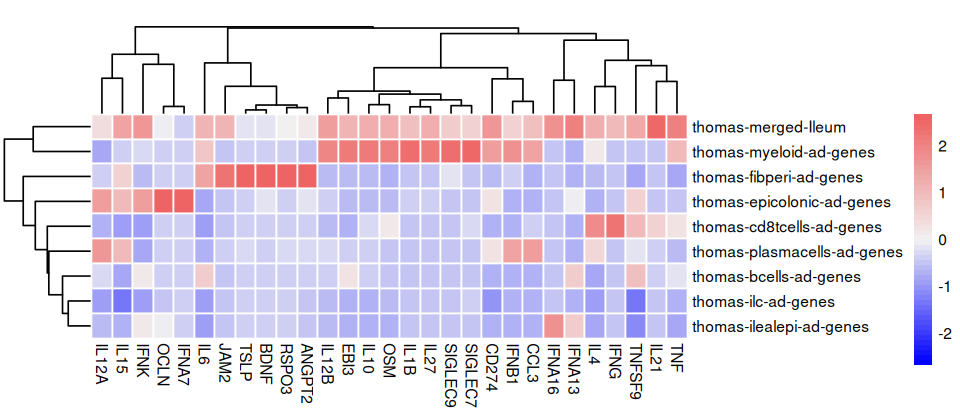

In [20]:
options(repr.plot.width = 8, repr.plot.height = 3.5)

pheatmap::pheatmap(t(mtx2), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("blue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, 
                  width = 8, height = 3.5)

In [21]:
saveRDS(seu_merged, "data/published_data/thomas/thomas_seu_merged_aggregated.rds")

In [2]:
seu_merged  <- readRDS("data/published_data/thomas/thomas_seu_merged_aggregated.rds")

In [5]:
seu_merged

An object of class Seurat 
30 features across 4308 samples within 1 assay 
Active assay: RNA (30 features, 0 variable features)
 3 layers present: scale.data, data, counts

In [4]:
seu_merged$major  %>% table


.
                                B                  C3pos-fibroblast 
                               36                               231 
                            CD4-T                             CD8-T 
                               36                               252 
                      Cycling-MNP                    Cycling-stroma 
                              236                                27 
                               DC                       Endothelium 
                              252                                36 
                   Epi-fibroblast                        Fibroblast 
                              223                               172 
                            Glial                  Ileal-epithelium 
                               36                                36 
               Innate-lymphocytes                     LP-fibroblast 
                              247                               245 
                             Mas

In [21]:
pheatmap::pheatmap(t(mtx2), main = "", 
         scale = "column", cluster_cols = T, cluster_rows = T,
        color=colorRampPalette(c("blue", "grey95", "indianred2"))(50), 
         border_color = "white",
                  fontsize = 9, 
                  width = 8, height = 3.5,
                  filename = "figures/ligand_receptor/thomas_ligand_expression_heatmap.pdf")

In [22]:
seu_merged$sample_id  %>% table

.
CID003352-2 CID003353-1 CID003354-1 CID003355-1 CID003356-1 CID003357-1 
         18          12          17          26          18          31 
CID003359-1 CID003360-1 CID003361-1 CID003362-1 CID003363-1 CID003364-1 
         16          17          18          18          17          17 
CID003365-1 CID003366-1 CID003367-2 CID003368-1 CID003369-1 CID003370-1 
         16          18          18          18          39          17 
CID003371-2 CID003372-1 CID003373-1 CID003374-1 CID003375-1 CID003376-1 
         16          18          34          16          17          17 
CID003377-1 CID003378-1 CID003379-1 CID003380-1 CID003381-1 CID003382-1 
         35          15          16          17          34          33 
CID003383-1 CID003384-1 CID003385-1 CID003386-1 CID003665-1 CID003666-1 
         18          17          15          33          28          17 
CID003667-1 CID003669-1 CID003670-1 CID003671-1 CID003672-1 CID003673-1 
         18          16          15          37  

In [23]:
table(seu_merged$sample_id %in% seu$sample_id)


TRUE 
4308 

In [24]:
colnames(seu@meta.data)

[1] "orig.ident"         "nCount_RNA"         "nFeature_RNA"      
 [4] "sample_id"          "Patient"            "Disease"           
 [7] "Site"               "Treatment"          "Disease_duration"  
[10] "Inflammation"       "Age"                "Gender"            
[13] "Ethnicity"          "Inflammation_score" "Ileum_vs_Colon"    
[16] "LibraryType"        "CellsLoaded"        "Match"             
[19] "Batch"              "doublet_scores"     "predicted_doublets"
[22] "n_genes_by_counts"  "total_counts"       "total_counts_mt"   
[25] "pct_counts_mt"      "total_counts_rp"    "pct_counts_rp"     
[28] "total_counts_hb"    "pct_counts_hb"      "total_counts_ig"   
[31] "pct_counts_ig"      "S_score"            "G2M_score"         
[34] "phase"              "cellbarcode"        "diff"              
[37] "final_analysis"     "minor"              "major"             
[40] "sub_bucket"         "bucket"             "Remission_status"  
[43] "bc"                 "RNA_snn_res.0.3"    "seurat_clusters"   
[46] "dataset"

In [22]:
md_to_join  <- seu@meta.data  %>% group_by(sample_id, Patient, Disease, Site, Treatment, Inflammation)  %>% tally  %>% dplyr::select(-n)

In [23]:
md_to_join

sample_id,Patient,Disease,Site,Treatment,Inflammation
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
CID003352-2,UC1,UC,Rectum,Post,Inflamed
CID003353-1,UC1,UC,Descending_Colon,Post,Non_Inflamed
CID003354-1,UC1,UC,Ascending_Colon,Post,Non_Inflamed
CID003355-1,UC1,UC,Terminal_Ileum,Post,Non_Inflamed
CID003356-1,UC1,UC,Rectum,Pre,Inflamed
CID003357-1,UC1,UC,Terminal_Ileum,Pre,Non_Inflamed
CID003359-1,UC1,UC,Ascending_Colon,Pre,Non_Inflamed
CID003360-1,UC2,UC,Rectum,Post,Inflamed
CID003361-1,UC2,UC,Sigmoid,Post,Inflamed


In [30]:
seu_merged

An object of class Seurat 
30 features across 4308 samples within 1 assay 
Active assay: RNA (30 features, 0 variable features)
 3 layers present: scale.data, data, counts

In [24]:
new_md  <- left_join(seu_merged@meta.data, md_to_join)

Joining with `by = join_by(sample_id)`


In [25]:
rownames(new_md)  <- colnames(seu_merged)

In [26]:
seu_merged@meta.data  <- new_md

In [27]:
seu_merged$Disease  %>% table

.
     CD Healthy      UC 
   2129     260    1919 

In [28]:
Idents(seu_merged)  <- seu_merged$Disease

In [ ]:
mtx3_filt

In [ ]:
mtx3_filt  <- as.data.frame(mtx3_filt)  %>% rownames_to_column("gene")  %>% 
pivot_longer(!gene, names_to = "sample_id_long", values_to = "value")  %>% 
mutate(sample_id = substr(sample_id_long, 1,nchar(sample_id_long)-2))

In [ ]:
mtx4  <- left_join(mtx3_filt, md_to_join)

In [ ]:
mtx4

In [ ]:
genes_test  <-  mtx4  %>% group_by(gene, Disease)  %>% 
dplyr::filter(Disease %in% c("CD","Healthy"))  %>% 
summarise(sum = sum(value))  %>% 
arrange(sum)  %>% 
dplyr::filter(sum > 10)  %>% 
pull(gene)  %>% unique

In [ ]:
stat_res  <- mtx4  %>%
dplyr::filter(Disease %in% c("CD","Healthy"))  %>% 
dplyr::filter(gene %in% genes_test)  %>% 
group_by(gene)  %>% 
rstatix::wilcox_test(value ~ Disease)

In [ ]:
stat_res  %>% arrange(p)

In [32]:
for(i in levels(factor(seu_merged$source))){
    
   data_sub  <- subset(seu_merged, source == i)
    
    #print(data_sub)
    
    mtx3  <- data_sub@assays$RNA@layers$counts
colnames(mtx3)  <- colnames(data_sub@assays$RNA)
rownames(mtx3)  <- rownames(data_sub@assays$RNA)
mtx3_filt  <- mtx3[,colSums(mtx3)>0]
    
    mtx3_filt  <- as.data.frame(mtx3_filt)  %>% rownames_to_column("gene")  %>% 
pivot_longer(!gene, names_to = "sample_id_long", values_to = "value")  %>% 
mutate(sample_id = substr(sample_id_long, 1,nchar(sample_id_long)-2))
    
    mtx4  <- left_join(mtx3_filt, md_to_join)
    
    
    genes_test  <-  mtx4  %>% group_by(gene, Disease)  %>% 
dplyr::filter(Disease %in% c("CD","Healthy"))  %>% 
summarise(sum = sum(value))  %>% 
arrange(sum)  %>% 
dplyr::filter(sum > 4)  %>% 
pull(gene)  %>% unique
    #print(genes_test)
    
    if(length(genes_test)>0){
  mrk  <- mtx4  %>%
dplyr::filter(Disease %in% c("CD","Healthy"))  %>% 
dplyr::filter(gene %in% genes_test)  %>% 
group_by(gene)  %>% 
rstatix::wilcox_test(value ~ Disease)
    
    mrk$celltype  <- i
    
    if(i == "thomas_bcells_ad_genes"){
        mrk_all  <- mrk
    } else {
        mrk_all  <- rbind(mrk_all, mrk)
    }
        }
}

Joining with `by = join_by(sample_id)`
`summarise()` has grouped output by 'gene'. You can override using the
`.groups` argument.
Joining with `by = join_by(sample_id)`
`summarise()` has grouped output by 'gene'. You can override using the
`.groups` argument.
Joining with `by = join_by(sample_id)`
`summarise()` has grouped output by 'gene'. You can override using the
`.groups` argument.
Joining with `by = join_by(sample_id)`
`summarise()` has grouped output by 'gene'. You can override using the
`.groups` argument.
Joining with `by = join_by(sample_id)`
`summarise()` has grouped output by 'gene'. You can override using the
`.groups` argument.
Joining with `by = join_by(sample_id)`
`summarise()` has grouped output by 'gene'. You can override using the
`.groups` argument.
Joining with `by = join_by(sample_id)`
`summarise()` has grouped output by 'gene'. You can override using the
`.groups` argument.
Joining with `by = join_by(sample_id)`
`summarise()` has grouped output by 'gene'. You can

In [33]:
mrk_all  %>% arrange(p)

gene,.y.,group1,group2,n1,n2,statistic,p,celltype
<chr>,<chr>,<chr>,<chr>,<int>,<int>,<dbl>,<dbl>,<chr>
OCLN,value,CD,Healthy,96,12,129.5,1.22e-05,thomas_plasmacells_ad_genes
IL27,value,CD,Healthy,68,9,164.0,3.61e-04,thomas_epicolonic_ad_genes
CD274,value,CD,Healthy,96,12,255.5,1.70e-03,thomas_plasmacells_ad_genes
TNF,value,CD,Healthy,94,9,688.0,1.95e-03,thomas_ilc_ad_genes
IL27,value,CD,Healthy,28,3,9.0,2.91e-03,thomas_ilealepi_ad_genes
RSPO3,value,CD,Healthy,96,12,273.5,2.99e-03,thomas_plasmacells_ad_genes
CCL3,value,CD,Healthy,96,12,273.0,3.10e-03,thomas_plasmacells_ad_genes
SIGLEC7,value,CD,Healthy,94,9,646.5,5.99e-03,thomas_ilc_ad_genes
TNF,value,CD,Healthy,96,12,317.0,1.15e-02,thomas_plasmacells_ad_genes


In [ ]:
seu_merged$major

In [48]:
   for(i in levels(factor(seu_merged$major))){
   data_sub  <- subset(seu_merged, major == i)
       mrk  <- FindMarkers(data_sub, `ident.1` = "CD", `ident.2` = "Healthy", 
                           only.pos = F, return.thresh = 1, slot = "counts",
                          logfc.threshold = -Inf, min.pct = 0.7, min.diff.pct = 0)
   
       if(nrow(mrk>0)){
           mrk$gene  <- rownames(mrk)
    mrk$celltype  <- i
    if(i == levels(factor(seu_merged$major))[1]){
        mrk_all2  <- mrk
    } else {
        mrk_all2  <- rbind(mrk_all2, mrk)
    }
           }
}
   


Warning message:
“Removing 863 cells missing data for vars requested”
Warning message:
“Removing 863 cells missing data for vars requested”
Warning message in FindMarkers.default(object = data.use, cells.1 = cells.1, cells.2 = cells.2, :
“No features pass min.pct threshold; returning empty data.frame”
Warning message:
“Removing 863 cells missing data for vars requested”
Warning message:
“Removing 863 cells missing data for vars requested”
Warning message:
“Removing 863 cells missing data for vars requested”
Warning message in FindMarkers.default(object = data.use, cells.1 = cells.1, cells.2 = cells.2, :
“No features pass min.pct threshold; returning empty data.frame”
Warning message:
“Removing 863 cells missing data for vars requested”
Warning message in FindMarkers.default(object = data.use, cells.1 = cells.1, cells.2 = cells.2, :
“No features pass min.pct threshold; returning empty data.frame”
Warning message:
“Removing 863 cells missing data for vars requested”
Warning message:
“Rem

In [49]:
mrk_all2  %>% arrange(p_val)

,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,gene,celltype
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
IL153,0.002034323,1.15519937,0.911,0.733,0.06102969,IL15,DC
IL27,0.002916090,-2.33254971,0.143,1.000,0.08748270,IL27,Ileal-epithelium
EBI32,0.006716046,1.71536981,0.815,0.667,0.20148138,EBI3,DC
TNF5,0.007390882,1.04745971,0.992,1.000,0.22172646,TNF,Mono-macro
SIGLEC92,0.010683497,0.02153621,0.847,0.867,0.32050490,SIGLEC9,Mono-macro
IL1B1,0.013224435,1.93243107,0.964,1.000,0.39673305,IL1B,CD4-T
IL154,0.016103361,0.70043427,1.000,1.000,0.48310084,IL15,Endothelium
SIGLEC9,0.034981816,0.39204728,0.742,0.600,1.00000000,SIGLEC9,DC
RSPO3,0.034986753,1.23670520,1.000,1.000,1.00000000,RSPO3,Endothelium


Warning message:
“ggrepel: 68 unlabeled data points (too many overlaps). Consider increasing max.overlaps”


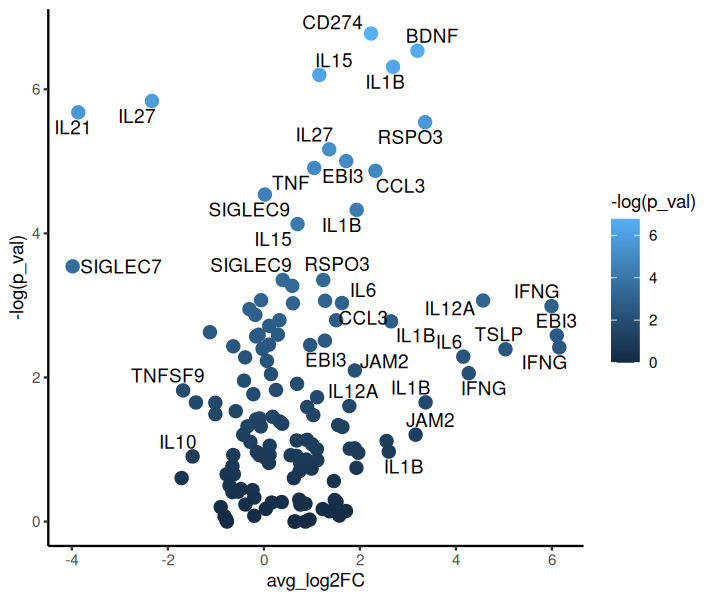

In [42]:
options(repr.plot.width = 6, repr.plot.height = 5)

mrk_all2  %>% #dplyr::filter(gene %in% genes_of_interest)  %>% 
arrange(p_val)  %>% 
#mutate(delabel = if_else(avg_log2FC > 8 | -log(p_val)>6,gene,""))  %>% 
ggplot(aes(x = avg_log2FC, y = -log(p_val), label = gene)) +
geom_point(aes(color = -log(p_val)), size = 3) +
        ggrepel::geom_text_repel() +
scale_shape_manual(values = c(7,8,10,21:25)) +
theme_classic() 

#ggsave("figures/ligand_receptor/volcano_predict3p.svg", width = 13, height = 10, units = "cm")

Warning message:
“Removing 232 cells missing data for features requested”
Warning message:
“Removing 232 cells missing data for vars requested”
Warning message:
“Removing 863 cells missing data for vars requested”
Warning message:
“Removed 232 rows containing non-finite outside the scale range
(`stat_ydensity()`).”
Warning message:
“Removed 232 rows containing missing values or values outside the scale range
(`geom_point()`).”


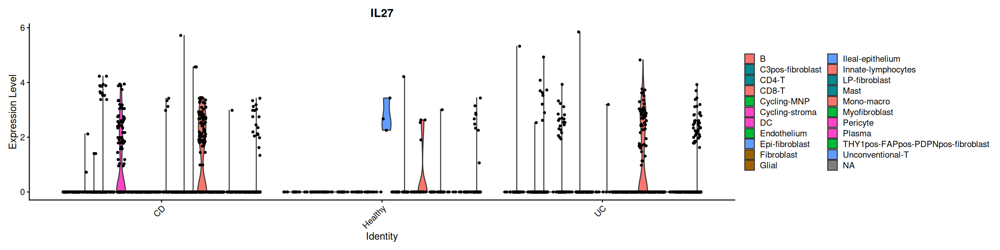

In [47]:
options(repr.plot.width = 20)
VlnPlot(seu_merged, features = "IL27", group.by = "Disease", split.by = "major")

In [ ]:
mrk_gns_list  <- list()

In [ ]:
for(i in 4:9){
    seu  <-  readRDS(paths[i])
    data_sub  <- subset(seu, Site == "Terminal_Ileum" & Disease %in% c("CD","Healthy"))
    Idents(data_sub)  <- data_sub$Disease
    mrk  <- FindMarkers(data_sub, `ident.1` = "CD", `ident.2` = "Healthy", 
                           only.pos = F, return.thresh = 1, slot = "counts",
                          logfc.threshold = -Inf, min.pct = 0, min.diff.pct = 0)
    mrk_gns_list[[i]]  <- mrk
    
}

In [ ]:
mrk_gns_list[[4]]  %>% arrange(p_val_adj)

In [ ]:
dataset_names

In [ ]:
for(i in c(1,2,4:9)){
    mrk_gns_list[[i]]$celltype  <- dataset_names[i]
    mrk_gns_list[[i]]$gene  <- rownames(mrk_gns_list[[i]])
}

In [ ]:
mrk_gns_list_all  <- bind_rows(mrk_gns_list)

In [ ]:
mrk_gns_list_all  %>% dplyr::filter(gene %in% genes_of_interest)

In [ ]:
mrk_gns_list_all  %>% dplyr::filter(gene %in% genes_of_interest)  %>% 
arrange(p_val)

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 5)

mrk_gns_list_all  %>% dplyr::filter(gene %in% genes_of_interest)  %>% 
arrange(p_val)  %>% 
mutate(delabel = if_else(avg_log2FC > 8 | -log(p_val)>6,gene,""))  %>% 
ggplot(aes(x = avg_log2FC, y = -log(p_val), label = delabel)) +
geom_point(aes(color = -log(p_val)), size = 3) +
        ggrepel::geom_text_repel() +
scale_shape_manual(values = c(7,8,10,21:25)) +
theme_classic() 

#ggsave("figures/ligand_receptor/volcano_predict3p.svg", width = 13, height = 10, units = "cm")

## Thomas Terminal Ileum

In [6]:
paths  <- list.files("data/published_data/thomas/", full.names = T)

In [7]:
dataset_names  <- gsub(list.files("data/published_data/thomas/", full.names = F), pattern = "\\.rds", replacement = "")

In [8]:
dataset_names

[1] "thomas_bcells_ad_genes"       "thomas_cd8tcells_ad_genes"   
 [3] "thomas_epicolonic_ad_genes"   "thomas_fibperi_ad_genes"     
 [5] "thomas_ilc_ad_genes"          "thomas_ilealepi_ad_genes"    
 [7] "thomas_merged_Ileum"          "thomas_myeloid_ad_genes"     
 [9] "thomas_plasmacells_ad_genes"  "thomas_seu_merged_aggregated"
[11] "thomas_vasc_ad_genes"

In [9]:
thomas_merged_Ileum <- readRDS("data/published_data/thomas/thomas_merged_Ileum.rds")

In [10]:
thomas_merged_Ileum

An object of class Seurat 
34086 features across 171843 samples within 3 assays 
Active assay: RNA (33075 features, 1000 variable features)
 3 layers present: scale.data, data, counts
 2 other assays present: integrated, prediction.score.id

In [11]:
thomas_merged_Ileum$minor  %>% table

.
                Blood_endothelium                  C3pos_fibroblast 
                             6172                               700 
                     CD4_T_helper                      CD4_T_memory 
                            11930                             16573 
                      CD4_T_naive                          CD4_Treg 
                             5213                              5998 
                     CD8_T_memory                       CD8_T_naive 
                            18720                              2042 
                      Cycling_MNP                    Cycling_stroma 
                              323                               106 
                               DC                    Epi_fibroblast 
                             3513                               307 
                     Follicular_B                          GClike_B 
                             3481                               167 
                            Glia

In [13]:
thomas_merged_Ileum$celltype  %>% table

.
     T cells      B cells  Fibroblasts    Epithelia Plasma cells      Myeloid 
       64701        17319         6119        49782        16067         9877 
  Endothelia 
        7978 

In [16]:
thomas_cd4  <- readRDS("data/mapping_data_onto_predict/thomas_query.rds")

thomas_cd4$dataset  <- "CD4"

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



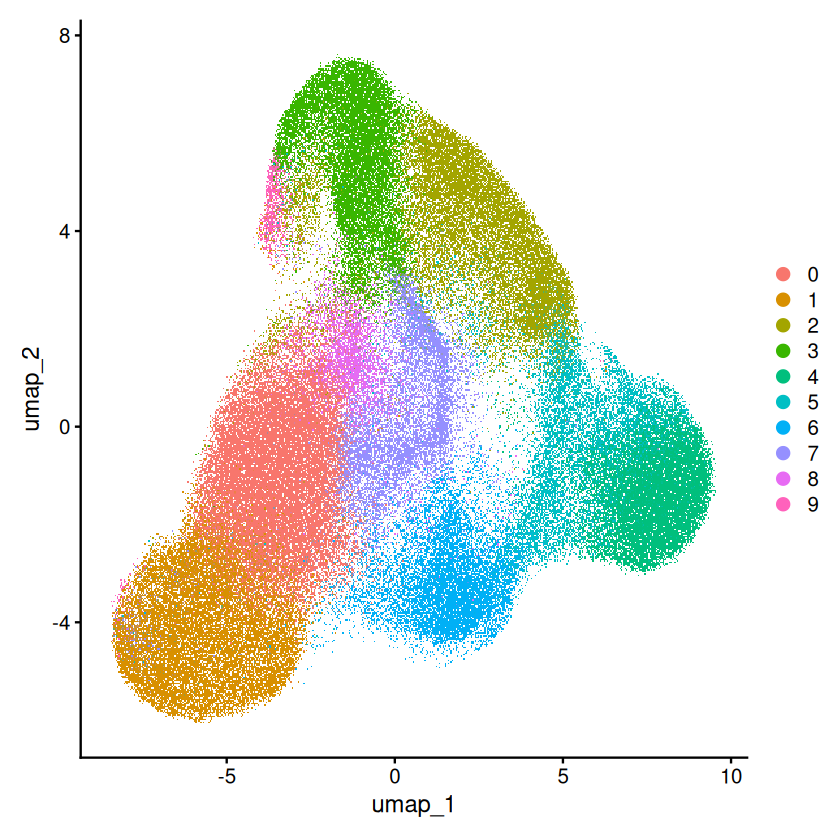

In [17]:
DimPlot(thomas_cd4)

In [18]:
cd4_ctl  <- colnames(subset(thomas_cd4, seurat_clusters == 6))

In [23]:
table(colnames(thomas_cd4) %in% colnames(thomas_merged_Ileum))


 FALSE 
145704 

In [21]:
head(colnames(thomas_merged_Ileum))

[1] "Cell_140_1" "Cell_141_1" "Cell_142_1" "Cell_143_1" "Cell_144_1"
[6] "Cell_145_1"

In [25]:
thomas_merged_Ileum$barcode  <- substr(colnames(thomas_merged_Ileum),1,nchar(colnames(thomas_merged_Ileum))-2)

In [24]:
head(colnames(thomas_cd4))

[1] "Cell_1" "Cell_2" "Cell_3" "Cell_4" "Cell_5" "Cell_6"

In [26]:
table(colnames(thomas_cd4) %in% thomas_merged_Ileum$barcode)


FALSE  TRUE 
50592 95112 

In [27]:
cd4_ctl  <- subset(thomas_cd4, seurat_clusters == 6)

In [28]:
cd4_ctl

An object of class Seurat 
34086 features across 11894 samples within 3 assays 
Active assay: integrated (1000 features, 1000 variable features)
 2 layers present: data, scale.data
 2 other assays present: RNA, prediction.score.id
 4 dimensional reductions calculated: pca, umap, ref.pca, ref.umap

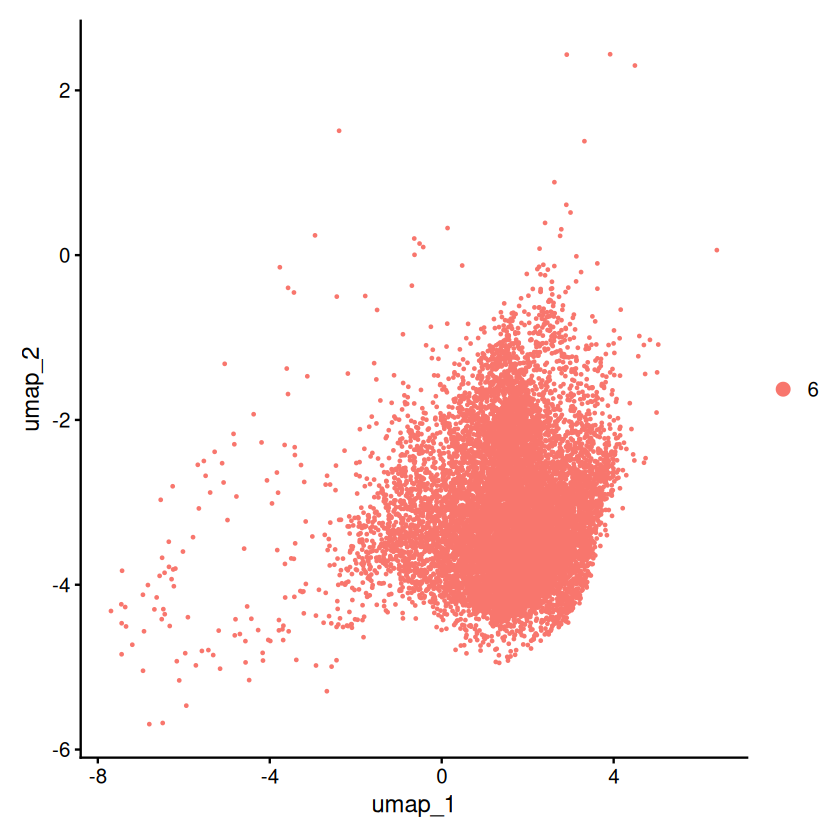

In [29]:
DimPlot(cd4_ctl)

In [35]:
cd4_ctl$Site  %>% table

.
 Ascending_Colon Descending_Colon           Rectum          Sigmoid 
            1696             2818             3208             1335 
  Terminal_Ileum 
            2837 

In [32]:
thomas_merged_Ileum$dataset  %>% table

.
                        CD4      thomas_bcells_ad_genes 
                      39714                       17319 
  thomas_cd8tcells_ad_genes     thomas_fibperi_ad_genes 
                      24304                        6119 
        thomas_ilc_ad_genes    thomas_ilealepi_ad_genes 
                        683                       49782 
    thomas_myeloid_ad_genes thomas_plasmacells_ad_genes 
                       9877                       16067 
       thomas_vasc_ad_genes 
                       7978 

In [33]:
thomas_merged_Ileum$cd4_ctl  <- ifelse(thomas_merged_Ileum$barcode %in% colnames(cd4_ctl) & thomas_merged_Ileum$dataset =="CD4","CD4_CTL","Other")

In [34]:
thomas_merged_Ileum$cd4_ctl  %>% table

.
CD4_CTL   Other 
   2837  169006 

In [36]:
seu_merged  <- thomas_merged_Ileum

In [37]:
seu_merged$major  %>% table

.
                                B                  C3pos_fibroblast 
                            17319                               700 
                            CD4_T                             CD8_T 
                            39714                             21679 
                      Cycling_MNP                    Cycling_stroma 
                              323                               106 
                               DC                       Endothelium 
                             3513                              6518 
                   Epi_fibroblast                        Fibroblast 
                              287                                20 
                            Glial                  Ileal_epithelium 
                             1354                             49782 
               Innate_lymphocytes                     LP_fibroblast 
                             1830                              2665 
                             Mas

In [38]:
seu_merged@meta.data  <- seu_merged@meta.data  %>% mutate(
    combinedMajorTypes_plus_cd4_ctl = if_else(cd4_ctl == "CD4_CTL", "CD4_CTL", major))

In [39]:
seu_merged$seurat_clusters  %>% table

.
    0     1    10     2     3     4     5     6     7     8     9 
54230 37111   268 24216 18448 12798  9543  6260  5228  2721  1020 

In [40]:
seu_merged$combinedMajorTypes_plus_cd4_ctl  %>% table

.
                                B                  C3pos_fibroblast 
                            17319                               700 
                          CD4_CTL                             CD4_T 
                             2837                             36877 
                            CD8_T                       Cycling_MNP 
                            21679                               323 
                   Cycling_stroma                                DC 
                              106                              3513 
                      Endothelium                    Epi_fibroblast 
                             6518                               287 
                       Fibroblast                             Glial 
                               20                              1354 
                 Ileal_epithelium                Innate_lymphocytes 
                            49782                              1830 
                    LP_fibroblas

In [41]:
Idents(seu_merged)  <- seu_merged$combinedMajorTypes_plus_cd4_ctl

In [42]:
library(nichenetr)

In [43]:
receiver = "CD4_CTL"
expressed_genes_receiver <- get_expressed_genes(receiver, seu_merged, pct = 0.05)

In [44]:
organism <- "human"

if(organism == "human"){
  lr_network <- readRDS(url("https://zenodo.org/record/7074291/files/lr_network_human_21122021.rds"))
  ligand_target_matrix <- readRDS(url("https://zenodo.org/record/7074291/files/ligand_target_matrix_nsga2r_final.rds"))
  weighted_networks <- readRDS(url("https://zenodo.org/record/7074291/files/weighted_networks_nsga2r_final.rds"))
} else if(organism == "mouse"){
  lr_network <- readRDS(url("https://zenodo.org/record/7074291/files/lr_network_mouse_21122021.rds"))
  ligand_target_matrix <- readRDS(url("https://zenodo.org/record/7074291/files/ligand_target_matrix_nsga2r_final_mouse.rds"))
  weighted_networks <- readRDS(url("https://zenodo.org/record/7074291/files/weighted_networks_nsga2r_final_mouse.rds"))

}

lr_network <- lr_network %>% distinct(from, to)
head(lr_network)

from,to
<chr>,<chr>
A2M,MMP2
A2M,MMP9
A2M,LRP1
A2M,KLK3
AANAT,MTNR1A
AANAT,MTNR1B


In [45]:
all_receptors <- unique(lr_network$to)  
expressed_receptors <- intersect(all_receptors, expressed_genes_receiver)

potential_ligands <- lr_network %>% filter(to %in% expressed_receptors) %>% pull(from) %>% unique()

In [46]:
seu_merged$major  %>% table

.
                                B                  C3pos_fibroblast 
                            17319                               700 
                            CD4_T                             CD8_T 
                            39714                             21679 
                      Cycling_MNP                    Cycling_stroma 
                              323                               106 
                               DC                       Endothelium 
                             3513                              6518 
                   Epi_fibroblast                        Fibroblast 
                              287                                20 
                            Glial                  Ileal_epithelium 
                             1354                             49782 
               Innate_lymphocytes                     LP_fibroblast 
                             1830                              2665 
                             Mas

In [47]:
sender_celltypes <- levels(factor(seu_merged$combinedMajorTypes_plus_cd4_ctl))

# Use lapply to get the expressed genes of every sender cell type separately here
list_expressed_genes_sender <- sender_celltypes %>% unique() %>% lapply(get_expressed_genes, seu_merged, 0.05)
expressed_genes_sender <- list_expressed_genes_sender %>% unlist() %>% unique()

potential_ligands_focused <- intersect(potential_ligands, expressed_genes_sender) 

# Also check 
length(expressed_genes_sender)
## [1] 8492
length(potential_ligands)
## [1] 483
length(potential_ligands_focused)
## [1] 127

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't leave any cells, so it is removed

integrated assay doesn't leave any cells, so it is removed

prediction.score.id assay doesn't lea

[1] 14448

[1] 538

[1] 371

In [48]:
seu_merged$Disease  %>% table

.
     CD Healthy      UC 
 135786   13100   22957 

In [49]:
seu_merged$combinedMajorTypes_plus_cd4_ctl  %>% table

.
                                B                  C3pos_fibroblast 
                            17319                               700 
                          CD4_CTL                             CD4_T 
                             2837                             36877 
                            CD8_T                       Cycling_MNP 
                            21679                               323 
                   Cycling_stroma                                DC 
                              106                              3513 
                      Endothelium                    Epi_fibroblast 
                             6518                               287 
                       Fibroblast                             Glial 
                               20                              1354 
                 Ileal_epithelium                Innate_lymphocytes 
                            49782                              1830 
                    LP_fibroblas

In [51]:
condition_oi <-  "CD"
condition_reference <- "Healthy"

seurat_obj_receiver <- subset(seu_merged, combinedMajorTypes_plus_cd4_ctl %in% c("CD4_CTL", "CD4_T"))

DE_table_receiver <-  FindMarkers(object = seurat_obj_receiver,
                                  ident.1 = condition_oi, ident.2 = condition_reference,
                                  group.by = "Disease",
                                  min.pct = 0.05) %>% rownames_to_column("gene")

geneset_oi <- DE_table_receiver %>% filter(p_val_adj <= 0.05 & abs(avg_log2FC) >= 0.25) %>% pull(gene)
geneset_oi <- geneset_oi %>% .[. %in% rownames(ligand_target_matrix)]

In [52]:
background_expressed_genes <- expressed_genes_receiver %>% .[. %in% rownames(ligand_target_matrix)]

length(background_expressed_genes)
## [1] 3476
length(geneset_oi)
## [1] 260

[1] 5859

[1] 276

In [53]:
ligand_activities <- predict_ligand_activities(geneset = geneset_oi,
                                               background_expressed_genes = background_expressed_genes,
                                               ligand_target_matrix = ligand_target_matrix,
                                               potential_ligands = potential_ligands)

In [54]:
ligand_activities <- ligand_activities %>% arrange(-aupr_corrected) %>% arrange(desc(aupr_corrected))
ligand_activities

test_ligand,auroc,aupr,aupr_corrected,pearson
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
IFNG,0.6438156,0.12393694,0.07692621,0.15679465
COL9A2,0.6183912,0.10942879,0.06241806,0.11653585
ANGPT2,0.5925386,0.10633901,0.05932828,0.14310821
IL6,0.6198612,0.10476418,0.05775345,0.12043303
FCER2,0.6360026,0.10438416,0.05737343,0.10013290
DEFB103B,0.6203896,0.10406054,0.05704981,0.11735734
GCG,0.6156357,0.10262265,0.05561192,0.09421302
PF4V1,0.6155140,0.10261311,0.05560238,0.11251998
OCLN,0.6258758,0.10243871,0.05542798,0.11541186


Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead."
`stat_bin()` using `bins = 30`. Pick better value with `binwidth`.


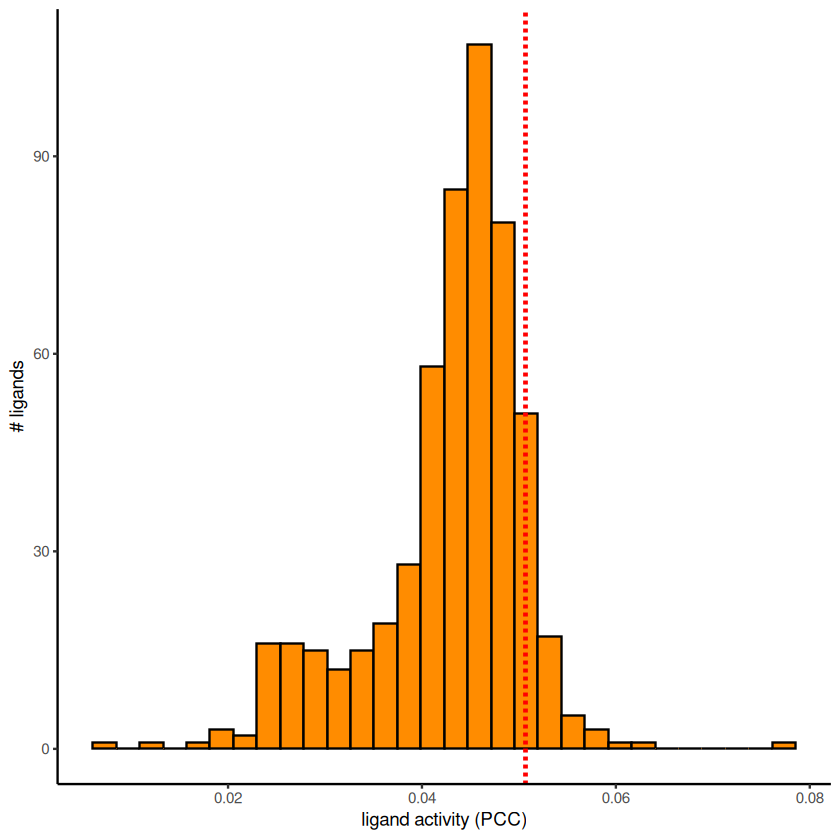

In [55]:
p_hist_lig_activity <- ggplot(ligand_activities, aes(x=aupr_corrected)) + 
  geom_histogram(color="black", fill="darkorange")  + 
  geom_vline(aes(xintercept=min(ligand_activities %>% top_n(50, aupr_corrected) %>% pull(aupr_corrected))),
             color="red", linetype="dashed", size=1) + 
  labs(x="ligand activity (PCC)", y = "# ligands") +
  theme_classic()

p_hist_lig_activity

In [56]:
best_upstream_ligands <- ligand_activities %>% top_n(50, aupr_corrected) %>% arrange(-aupr_corrected) %>% pull(test_ligand)

In [57]:
ggtheme <- function() {
  theme(
    axis.text = element_text(size = 20),
    axis.title = element_text(size = 20),
    text = element_text(size = 20, colour = "black"),
    legend.text = element_text(size = 20),
    legend.key.size =  unit(10, units = "points")
    
  )
}


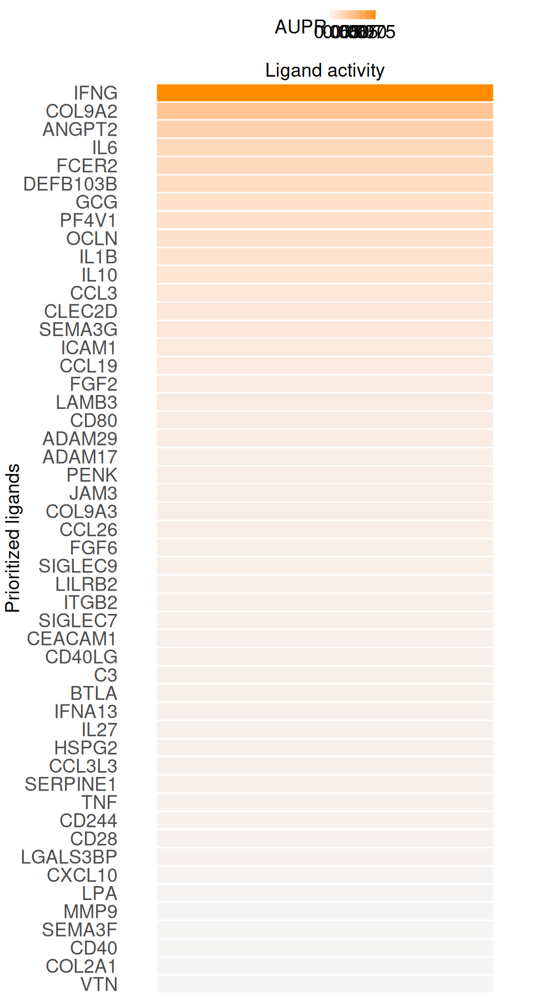

In [58]:
options(repr.plot.width = 8, repr.plot.height = 15)
vis_ligand_aupr <- ligand_activities %>% filter(test_ligand %in% best_upstream_ligands) %>%
  column_to_rownames("test_ligand") %>% select(aupr_corrected) %>% arrange(aupr_corrected) %>% as.matrix(ncol = 1)

(make_heatmap_ggplot(vis_ligand_aupr,
                     "Prioritized ligands", "Ligand activity", 
                     legend_title = "AUPR", color = "darkorange") + 
    theme(axis.text.x.top = element_blank())) + ggtheme()